# GPT-2 adaptation of the IMDb shortcut-mining / geometry notebook

**Primary GPT-2 analysis:** templated context + the **last token of each mined token group**. Because GPT-2 is causal, that final token is the first group token whose hidden state has seen the complete preceding group.

The original mean/sum views are retained as sensitivity analyses, but they do not have exactly the same interpretation as in bidirectional BERT.

Before running: upload `gpt2-imdb-finetuned-v1.zip` to `/content/`, or change `MODEL_PATH` in the model-loading cell.


# Analyzing Hidden States based on n-grams / bag of words

---
## Setting up S1 Vocabulary


Imports


In [5]:

from datasets import load_dataset, concatenate_datasets
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from transformers import (
    GPT2Model,
    GPT2TokenizerFast,
    GPT2ForSequenceClassification,
)
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.metrics import pairwise_distances
import os
import shutil
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth
from sklearn.decomposition import PCA

# Keep analysis length identical to the fine-tuning pipeline.
MAX_LENGTH = 500
LAYERS = (5, 8, 11, 12)


Load Models + Tokenizer: Fine-tuned BERT (IMDB) +  Pre-Trained


In [6]:
MODEL_PATH = "./gpt2-imdb-finetuned-v1"

tokenizer = GPT2TokenizerFast.from_pretrained(
    MODEL_PATH,
    local_files_only=True,
)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

ft_gpt2 = GPT2ForSequenceClassification.from_pretrained(
    MODEL_PATH,
    local_files_only=True,
)

ft_gpt2.config.pad_token_id = tokenizer.pad_token_id

# untouched pretrained GPT-2 reference
pt_gpt2 = GPT2Model.from_pretrained("gpt2")

  2026-10-09T08:15:44.595118Z  WARN  Reqwest(reqwest::Error { kind: Request, url: "https://us.aws.cdn.hf.co/xorbs/default/eb1fc521ace6626fa1c47a4be261876dfb431e83b337f8eb4be1fbbf1e2426e4?xip=keA2EyQMN8Q&X-Xet-Session-Id=01M4FVPZR1AVVQKQJNQDRFM1RB&repo_id=621ffdc036468d709f17434d&user_id=public&Expires=1791537344&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5hd3MuY2RuLmhmLmNvL3hvcmJzL2RlZmF1bHQvZWIxZmM1MjFhY2U2NjI2ZmExYzQ3YTRiZTI2MTg3NmRmYjQzMWU4M2IzMzdmOGViNGJlMWZiYmYxZTI0MjZlNFxcP3hpcD1rZUEyRXlRTU44USZYLVhldC1TZXNzaW9uLUlkPTAxTTRGVlBaUjFBVlZRS1FKTlFEUkZNMVJCJnJlcG9faWQ9NjIxZmZkYzAzNjQ2OGQ3MDlmMTc0MzRkJnVzZXJfaWQ9cHVibGljIiwiQ29uZGl0aW9uIjp7IkRhdGVMZXNzVGhhbiI6eyJFcG9jaFRpbWUiOjE3OTE1MzczNDR9LCJCeXRlUmFuZ2UiOnsiRXhwZWN0ZWRIZWFkZXIiOiJieXRlcz0wLTQ3OTM1NDkwIn19fV19&Signature=MEUCIDs8CCFwEZF0bEq8EpFQfdZLM7PUFCm07Jhl6viJsNg7AiEAwqd92QEjGk8bweOlXKPOS01-eg5Wk4YHVex2vY0OOGA_&Key-Pair-Id=01KXEF4KZ1B6FV465MAWR4M21F&Hash-Algorithm=SHA256", source: hyper_util::client::legacy::Error(Co

Load Dataset


In [7]:

dataset = load_dataset("stanfordnlp/imdb")
train_data = dataset["train"]
test_data = dataset["test"]


Generating unsupervised split: 100%|██████████| 50000/50000 [00:00<00:00, 891555.28 examples/s]


Setup Device


In [8]:

# Device setup
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

pt_gpt2 = pt_gpt2.to(device)
ft_gpt2 = ft_gpt2.to(device)

pt_gpt2.eval()
ft_gpt2.eval()

print("device:", device)


device: mps


Method used to extract Saliency.

Source: [Understanding Text Classification Data and Models Using Aggregated Input Salience](https://arxiv.org/abs/2211.05485)


In [9]:

def grad_l2_saliency(
    text: str,
    model,
    tokenizer,
    device,
    target_class: int | None = None,
    max_length: int = MAX_LENGTH,
):
    """
    Grad-L2 saliency for GPT-2 sequence classification.

    Important GPT-2 difference:
    - There are no [CLS]/[SEP] tokens.
    - There are no BERT token_type_ids.
    - The classifier uses the final non-padding token state.
    - For this single, unpadded input, the last token is therefore the
      classification state and receives information from all earlier tokens.

    Returns
    -------
    tokens      : list[str]
    saliency    : np.ndarray, shape [seq_len]
    input_ids   : np.ndarray, shape [seq_len]
    """
    model.eval()

    enc = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=max_length,
        add_special_tokens=False,
    )

    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)

    # Architecture-independent access to GPT-2's token embedding layer.
    # For GPT-2 this resolves to transformer.wte.
    with torch.no_grad():
        word_embeds = model.get_input_embeddings()(input_ids)

    word_embeds = word_embeds.detach().requires_grad_(True)

    model.zero_grad(set_to_none=True)

    # The sequence is not padded here, so when GPT2ForSequenceClassification
    # receives inputs_embeds, using the final sequence position is correct.
    outputs = model(
        inputs_embeds=word_embeds,
        attention_mask=attention_mask,
        return_dict=True,
    )

    logits = outputs.logits

    if target_class is None:
        target_class = logits.argmax(dim=-1).item()

    score = logits[0, target_class]
    score.backward()

    grads = word_embeds.grad
    saliency = torch.norm(grads, p=2, dim=-1).squeeze(0)

    saliency = saliency.detach().cpu().numpy()
    input_ids_cpu = input_ids.squeeze(0).detach().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids_cpu)

    return tokens, saliency, input_ids_cpu


Predict Test Set in preparation for S1 Vocabulary


In [10]:

def predict_labels(
    dataset_split,
    model,
    tokenizer,
    device,
    batch_size=32,
    max_length=MAX_LENGTH,
):
    model.eval()
    loader = DataLoader(dataset_split, batch_size=batch_size, shuffle=False)

    all_preds = []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Predicting IMDb labels"):
            texts = batch["text"]

            enc = tokenizer(
                list(texts),
                return_tensors="pt",
                truncation=True,
                padding=True,
                max_length=max_length,
                add_special_tokens=False,
            ).to(device)

            logits = model(**enc).logits
            preds = logits.argmax(dim=-1).cpu()
            all_preds.extend(preds.tolist())

    return all_preds


# IMPORTANT: do not reuse the old BERT cache.
path = "test_preds_gpt2.npy"

if os.path.exists(path):
    test_preds = np.load(path)
else:
    test_preds = predict_labels(test_data, ft_gpt2, tokenizer, device)
    np.save(path, test_preds)

print("number of predictions:", len(test_preds))


Predicting IMDb labels: 100%|██████████| 782/782 [09:36<00:00,  1.36it/s]

number of predictions: 25000


Function to extract top 5 salient tokens per sentence.


In [11]:
def topk_vocab_tokens_with_maxpos(input_ids, saliency, top_k=5, exclude_special_ids=None):
    """
    For one sentence:
    - For each vocab token_id, keep the maximum |saliency| value observed in this sentence,
      and the token position where that maximum occurs.
    - Return the top_k token_ids ranked by that max |saliency|.

    Output format (length <= top_k):
      [{"token_id": int, "position": int, "saliency": float}, ...]
    """
    exclude_special_ids = set(exclude_special_ids or [])
    best = {}  # token_id -> (best_abs_saliency, position)

    for pos, (tok_id, s) in enumerate(zip(input_ids, saliency)):
        tok_id = int(tok_id)
        if tok_id in exclude_special_ids:
            continue

        a = abs(float(s))
        if (tok_id not in best) or (a > best[tok_id][0]):
            best[tok_id] = (a, int(pos))

    if not best:
        return []

    items = [(tok_id, a, pos) for tok_id, (a, pos) in best.items()]
    items.sort(key=lambda x: x[1], reverse=True)
    items = items[:top_k]

    return [{"token_id": tok_id, "saliency": a, "position": pos} for tok_id, a, pos in items]


Fill up row per sentence vectors for top-5 tokens:

---

**Build S1-Vocab**

This function converts the first n text examples into their salience-fingerprints (S1 vectors), stacks those into a matrix, normalizes them, and returns both the matrix and the original texts.

Text example -> Row

<pre>
          column dimension → |V| (the r vector)
        ┌──────────────────────────────────────────────┐
 row 1  │ r(1)[0]   r(1)[1]   r(1)[2]   ...   r(1)[V-1]│
 row 2  │ r(2)[0]   r(2)[1]   r(2)[2]   ...   r(2)[V-1]│
   .    │    .         .         .              .      │
 row N  │ r(N)[0]   r(N)[1]   r(N)[2]   ...   r(N)[V-1]│
        └──────────────────────────────────────────────┘
             ↑
             vocabulary-dimension (S1 vector)***
<pre>


In [12]:
def saliency_to_vocab_vector(input_ids, saliency, vocab_size, top_k=5):
    """
    Implements S1 from the paper: a |V|-dim vector with the
    max |saliency| per vocab item, zeroed except for top-k entries.
    """
    r = np.zeros(vocab_size, dtype=np.float32) # GPT-2 vocabulary size

    for tok_id, s in zip(input_ids, saliency):
        tok_id = int(tok_id)
        r[tok_id] = max(r[tok_id], abs(float(s))) # get max saliency value

    if top_k is not None and top_k < vocab_size:
        # Keep only top-k entries, zero out the rest
        if np.count_nonzero(r) > top_k: # count how many positoons in r are not zero
            top_idx = np.argpartition(r, -top_k)[-top_k:] # Find the indices of the k largest values in r, argsort begin nlogn efficient
            mask = np.zeros_like(r)
            mask[top_idx] = r[top_idx]
            r = mask

    return r


def build_salience_vocab_matrix_from_indices(
    dataset_split,
    indices,
    model,
    tokenizer,
    device,
    top_k=5,
    max_length=MAX_LENGTH,
):
    """Build a row-normalized vocabulary salience matrix for selected dataset indices.

    For each text, computes token saliency, aggregates the top-k salient tokens into a
    vocabulary-sized vector, and returns the stacked matrix along with the source texts
    and per-example top-k token metadata including raw and normalized saliency scores.
    """
    vocab_size = tokenizer.vocab_size
    R_rows = []
    texts = []
    salient_token_info = [] # save positions

    special_ids = tokenizer.all_special_ids  


    for idx in tqdm(indices):
        text = dataset_split[idx]["text"]
        tokens, sal, ids = grad_l2_saliency(
            text, model, tokenizer, device, max_length=max_length
        )
        r = saliency_to_vocab_vector(ids, sal, vocab_size, top_k=top_k)
        R_rows.append(r)
        texts.append(text)


        # extract token_positions
        topk_vocab = topk_vocab_tokens_with_maxpos(
            ids, sal, top_k=top_k, exclude_special_ids=special_ids
        )
        salient_token_info.append({
            "dataset_idx": idx,
            "text": text,
            "topk_vocab": topk_vocab
        })

    R_vocab = np.stack(R_rows, axis=0)
    # row-wise L2 normalization as in the paper
    norms = np.linalg.norm(R_vocab, axis=1, keepdims=True) + 1e-12
    R_vocab = R_vocab / norms
    #store both raw + normalized saliency per token in salient_token_info
    for row_i, info in enumerate(salient_token_info):
        for item in info["topk_vocab"]:
            tok_id = int(item["token_id"])
            item["saliency_raw"] = float(item["saliency"])              # existing raw abs-saliency
            item["saliency_norm"] = float(R_vocab[row_i, tok_id])       # exact value from r_vocab row

    return R_vocab, texts, salient_token_info


Create S1-Vocab for 2500 negatively predicted samples


In [13]:
# select indices of negatively predicted examples
neg_indices = [i for i, p in enumerate(test_preds) if p == 0]  

# sample 2500 
# First seed: np.random.seed(42)
# Second seed: 
np.random.seed(1)
# third seed:  np.random.seed(2)
sample_size = min(2500, len(neg_indices))
neg_sample_indices = np.random.choice(neg_indices, size=sample_size, replace=False)

R_vocab_5_neg, texts_neg, salient_token_info_neg = build_salience_vocab_matrix_from_indices(
    test_data,
    neg_sample_indices,
    ft_gpt2,
    tokenizer,
    device,
    top_k=5,
)


100%|██████████| 2500/2500 [03:55<00:00, 10.60it/s]


Create S1-Vocab for 2500 positively predicted samples


In [14]:
# # select indices of negatively predicted examples
# pos_indices = [i for i, p in enumerate(test_preds) if p == 1]  

# # sample 2500 
# np.random.seed(42)
# sample_size = min(2500, len(pos_indices))
# neg_sample_indices = np.random.choice(pos_indices, size=sample_size, replace=False)

# R_vocab_5_pos, texts_pos, salient_token_info_pos = build_salience_vocab_matrix_from_indices(
#     test_data,
#     neg_sample_indices,
#     ft_gpt2,
#     tokenizer,
#     device,
#     top_k=5, ######################
# )


## Pattern Mining
Using FP-Growth Algorithm


Imports


Setup Transactions and Lookup Table (Salient tokens per Sentence identified with L2-Grad Saliency Method)


In [15]:
transactions_neg_5 = []
pos_lookup_neg_5 = []   # list of dicts: token_id -> position (for this transaction)

for item in salient_token_info_neg:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]

    transactions_neg_5.append(toks)
    pos_lookup_neg_5.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

print("num transactions_neg_5:", len(transactions_neg_5))
print("avg len:", np.mean([len(t) for t in transactions_neg_5]))
print(transactions_neg_5[:5])


num transactions_neg_5: 2500
avg len: 5.0
[[13898, 13388, 6896, 10607, 5633], [20039, 46835, 4615, 2822, 34192], [19689, 28906, 11648, 7818, 4313], [47149, 2538, 50029, 8120, 11483], [45315, 24786, 1360, 13915, 294]]


Running FP-Algorithm


In [16]:
te = TransactionEncoder() # Creates encoder that converts lists of tokens into a binary matrix (One hot encoded)
X = te.fit(transactions_neg_5).transform(transactions_neg_5) # fit and transform bool matrix to prepare for fp-growth

df = pd.DataFrame(X, columns=te.columns_) # to pandas

freq_itemsets_neg_5 = fpgrowth(
    df,
    min_support=0.002, # minimum frequency of items -> 0.002 = 0.2%
    use_colnames=True, # return column names not indices
    max_len=4 # max item size per pattern
)

freq_itemsets_neg_5["length"] = freq_itemsets_neg_5["itemsets"].apply(len) # add length column

def order_itemset_like_sentence(itemset):
    # pick a transaction and use its token positions as the order reference
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions_neg_5, pos_lookup_neg_5):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items


freq_itemsets_neg_5["ordered_ids"] = freq_itemsets_neg_5["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_neg_5["ordered_tokens"] = freq_itemsets_neg_5["ordered_ids"].apply(lambda ids: tokenizer.convert_ids_to_tokens(ids))


Inspecting Frequent, high support, itemsets larger than 1.


In [17]:
freq_itemsets_neg_5[freq_itemsets_neg_5["length"] > 1].sort_values("support", ascending=False).head(20)


,support,itemsets,length,ordered_ids,ordered_tokens
475,0.0200,"(940, 14)",2,"[14, 940]","[/, 10]"
469,0.0124,"(5290, 13)",2,"[5290, 13]","[Ġworst, .]"
527,0.0096,"(12659, 13)",2,"[12659, 13]","[Ġawful, .]"
555,0.0080,"(540, 2342)",2,"[2342, 540]","[Ġwatch, able]"
466,0.0072,"(7818, 13)",2,"[7818, 13]","[Ġterrible, .]"
501,0.0072,"(940, 604)",2,"[604, 940]","[Ġ4, 10]"
484,0.0072,"(13, 3807)",2,"[3807, 13]","[Ġmovie, .]"
507,0.0068,"(2089, 13)",2,"[2089, 13]","[Ġbad, .]"
509,0.0068,"(13, 14262)",2,"[14262, 13]","[Ġboring, .]"
519,0.0064,"(11037, 6927)",2,"[6927, 11037]","[><, Ġ/>]"


### Creating negative R_Vocab with the top 10 salient tokens per sentence.


In [18]:
R_vocab_10_neg, texts_neg_10, salient_token_info_neg_10 = build_salience_vocab_matrix_from_indices(
    test_data,
    neg_sample_indices,
    ft_gpt2,
    tokenizer,
    device,
    top_k=10, ######################
)


100%|██████████| 2500/2500 [02:39<00:00, 15.63it/s]


Setup Transactions and Lookup Table (Salient tokens per Sentence identified with L2-Grad Saliency Method)


In [19]:
transactions_neg_10 = []
pos_lookup_10 = []   # list of dicts: token_id -> position (for this transaction)

for item in salient_token_info_neg_10:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]

    transactions_neg_10.append(toks)
    pos_lookup_10.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

print("num transactions_neg_10:", len(transactions_neg_10))
print("avg len:", np.mean([len(t) for t in transactions_neg_10]))
print(transactions_neg_10[:5])


num transactions_neg_10: 2500
avg len: 9.9992
[[13898, 13388, 6896, 10607, 5633, 14404, 7110, 8508, 826, 2514], [20039, 46835, 4615, 2822, 34192, 355, 13, 3807, 1212, 9394], [19689, 28906, 11648, 7818, 4313, 13, 4571, 9335, 12659, 3807], [47149, 2538, 50029, 8120, 11483, 11811, 18871, 13, 406, 17534], [45315, 24786, 1360, 13915, 294, 519, 499, 510, 13, 22665]]


Running FP-Algorithm


In [20]:
te = TransactionEncoder() # Creates encoder that converts lists of tokens into a binary matrix (One hot encoded)
X = te.fit(transactions_neg_10).transform(transactions_neg_10) # fit and transform bool matrix to prepare for fp-growth

df = pd.DataFrame(X, columns=te.columns_) # to pandas

freq_itemsets_neg_10 = fpgrowth(
    df,
    min_support=0.002, # minimum frequency of items -> 0.002 = 0.2%
    use_colnames=True, # return column names not indices
    max_len=4 # max item size per pattern
)

freq_itemsets_neg_10["length"] = freq_itemsets_neg_10["itemsets"].apply(len) # add length column

def order_itemset_like_sentence(itemset):
    # pick a transaction and use its token positions as the order reference
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions_neg_10, pos_lookup_10):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items


freq_itemsets_neg_10["ordered_ids"] = freq_itemsets_neg_10["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_neg_10["ordered_tokens"] = freq_itemsets_neg_10["ordered_ids"].apply(lambda ids: tokenizer.convert_ids_to_tokens(ids))


Inspecting Frequent, high support, itemsets larger than 1.


In [21]:
freq_itemsets_neg_10[freq_itemsets_neg_10["length"] > 1].sort_values("support", ascending=False).head(20)


,support,itemsets,length,ordered_ids,ordered_tokens
964,0.0564,"(13, 3807)",2,"[3807, 13]","[Ġmovie, .]"
1025,0.0408,"(5290, 13)",2,"[5290, 13]","[Ġworst, .]"
1073,0.0364,"(940, 14)",2,"[14, 940]","[/, 10]"
1207,0.0340,"(2089, 13)",2,"[2089, 13]","[Ġbad, .]"
992,0.0284,"(12659, 13)",2,"[12659, 13]","[Ġawful, .]"
1046,0.0260,"(11037, 29847)",2,"[29847, 11037]","[.<, Ġ/>]"
1206,0.0240,"(2089, 3807)",2,"[3807, 2089]","[Ġmovie, Ġbad]"
1335,0.0232,"(13, 2646)",2,"[2646, 13]","[Ġfilm, .]"
965,0.0220,"(1212, 3807)",2,"[1212, 3807]","[This, Ġmovie]"
951,0.0216,"(13, 7110)",2,"[7110, 13]","[Ġplot, .]"


In [22]:
freq_itemsets_neg_10[freq_itemsets_neg_10["length"] > 2].sort_values("support", ascending=False).head(20)


,support,itemsets,length,ordered_ids,ordered_tokens
1461,0.0132,"(29847, 11037, 6927)",3,"[29847, 6927, 11037]","[.<, ><, Ġ/>]"
1085,0.0124,"(940, 13, 14)",3,"[14, 940, 13]","[/, 10, .]"
1208,0.0112,"(2089, 13, 3807)",3,"[2089, 3807, 13]","[Ġbad, Ġmovie, .]"
1091,0.0104,"(940, 11037, 14)",3,"[11037, 14, 940]","[Ġ/>, /, 10]"
973,0.0104,"(1212, 13, 3807)",3,"[1212, 3807, 13]","[This, Ġmovie, .]"
1251,0.0080,"(940, 604, 14)",3,"[604, 14, 940]","[Ġ4, /, 10]"
1031,0.0080,"(5290, 13, 3807)",3,"[5290, 3807, 13]","[Ġworst, Ġmovie, .]"
974,0.0076,"(5290, 1212, 13)",3,"[1212, 5290, 13]","[This, Ġworst, .]"
975,0.0076,"(5290, 1212, 3807)",3,"[1212, 5290, 3807]","[This, Ġworst, Ġmovie]"
1364,0.0064,"(513, 940, 14)",3,"[513, 14, 940]","[Ġ3, /, 10]"


---
## Experiment 1: Inspecting Saliency of top 100 high support transactions


Add Saliency values per transaction


In [23]:
transactions_neg_10 = []
pos_lookup_neg_10 = []   # list of dicts: token_id -> position (per sample)
saliency_lookup = []   # list of dicts: token_id -> saliency_norm (per sample)


for item in salient_token_info_neg_10:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]

    transactions_neg_10.append(toks)
    pos_lookup_neg_10.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

    saliency_lookup.append({int(t["token_id"]): float(t["saliency_norm"]) for t in item["topk_vocab"]})

print("transactions_neg_10:", len(transactions_neg_10))
print("avg transaction length:", np.mean([len(t) for t in transactions_neg_10]))
print(transactions_neg_10[:5])

# Convert transactions_neg_10 to matrix
te = TransactionEncoder()
X = te.fit(transactions_neg_10).transform(transactions_neg_10)
df = pd.DataFrame(X, columns=te.columns_)

print("transaction matrix shape:", df.shape)

#Run FP-Growth
freq_itemsets_neg_10 = fpgrowth(
    df,
    min_support=0.002, # minimum frequency of items -> 0.002 = 0.2%
    use_colnames=True, # return column names not indices
    max_len=4 # max item size per pattern
)

freq_itemsets_neg_10["length"] = freq_itemsets_neg_10["itemsets"].apply(len)

def order_itemset_like_sentence(itemset):
    # pick a transaction and use its token positions as the order reference
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions_neg_10, pos_lookup_neg_10):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items

freq_itemsets_neg_10["ordered_ids"] = freq_itemsets_neg_10["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_neg_10["ordered_tokens"] = freq_itemsets_neg_10["ordered_ids"].apply(
    lambda ids: tokenizer.convert_ids_to_tokens([int(x) for x in ids])
)

# GPT-2 tokens often contain the byte-level-BPE whitespace marker "Ġ".
# Keep ordered_tokens for exact token identity, but also add a readable string.
freq_itemsets_neg_10["ordered_text"] = freq_itemsets_neg_10["ordered_ids"].apply(
    lambda ids: tokenizer.decode(
        [int(x) for x in ids],
        clean_up_tokenization_spaces=False
    ).strip()
)

# compute saliency only from the tokens in the itemset,
# and only in the supporting transactions_neg_10 of that itemset ===
def pattern_saliency(itemset):
    items = [int(t) for t in itemset]
    scores = []

    for tx, sm in zip(transactions_neg_10, saliency_lookup):
        if all(i in tx for i in items):   # supporting transaction
            for i in items:               # only itemset tokens
                scores.append(sm[i])

    return sum(scores) / len(scores) if scores else 0


freq_itemsets_neg_10["saliency_score"] = freq_itemsets_neg_10["itemsets"].apply(pattern_saliency)
freq_itemsets_neg_10["score"] = freq_itemsets_neg_10["support"] * freq_itemsets_neg_10["saliency_score"]


transactions_neg_10: 2500
avg transaction length: 9.9992
[[13898, 13388, 6896, 10607, 5633, 14404, 7110, 8508, 826, 2514], [20039, 46835, 4615, 2822, 34192, 355, 13, 3807, 1212, 9394], [19689, 28906, 11648, 7818, 4313, 13, 4571, 9335, 12659, 3807], [47149, 2538, 50029, 8120, 11483, 11811, 18871, 13, 406, 17534], [45315, 24786, 1360, 13915, 294, 519, 499, 510, 13, 22665]]
transaction matrix shape: (2500, 7500)


In [24]:
two_grams = freq_itemsets_neg_10[freq_itemsets_neg_10["length"] > 1].sort_values("score", ascending=False).head(100)


In [25]:
two_grams.head(20)


,support,itemsets,length,ordered_ids,ordered_tokens,ordered_text,saliency_score,score
964,0.0564,"(13, 3807)",2,"[3807, 13]","[Ġmovie, .]",movie.,0.240685,0.013575
1073,0.0364,"(940, 14)",2,"[14, 940]","[/, 10]",/10,0.355178,0.012928
1025,0.0408,"(5290, 13)",2,"[5290, 13]","[Ġworst, .]",worst.,0.313751,0.012801
1207,0.0340,"(2089, 13)",2,"[2089, 13]","[Ġbad, .]",bad.,0.269931,0.009178
992,0.0284,"(12659, 13)",2,"[12659, 13]","[Ġawful, .]",awful.,0.323079,0.009175
1046,0.0260,"(11037, 29847)",2,"[29847, 11037]","[.<, Ġ/>]",.< />,0.269794,0.007015
1305,0.0208,"(13, 14262)",2,"[14262, 13]","[Ġboring, .]",boring.,0.315954,0.006572
1206,0.0240,"(2089, 3807)",2,"[3807, 2089]","[Ġmovie, Ġbad]",movie bad,0.262577,0.006302
1003,0.0216,"(7818, 13)",2,"[7818, 13]","[Ġterrible, .]",terrible.,0.289927,0.006262
1455,0.0200,"(11037, 6927)",2,"[6927, 11037]","[><, Ġ/>]",>< />,0.288894,0.005778


Comparing Saliency and Support of highes support itemsets


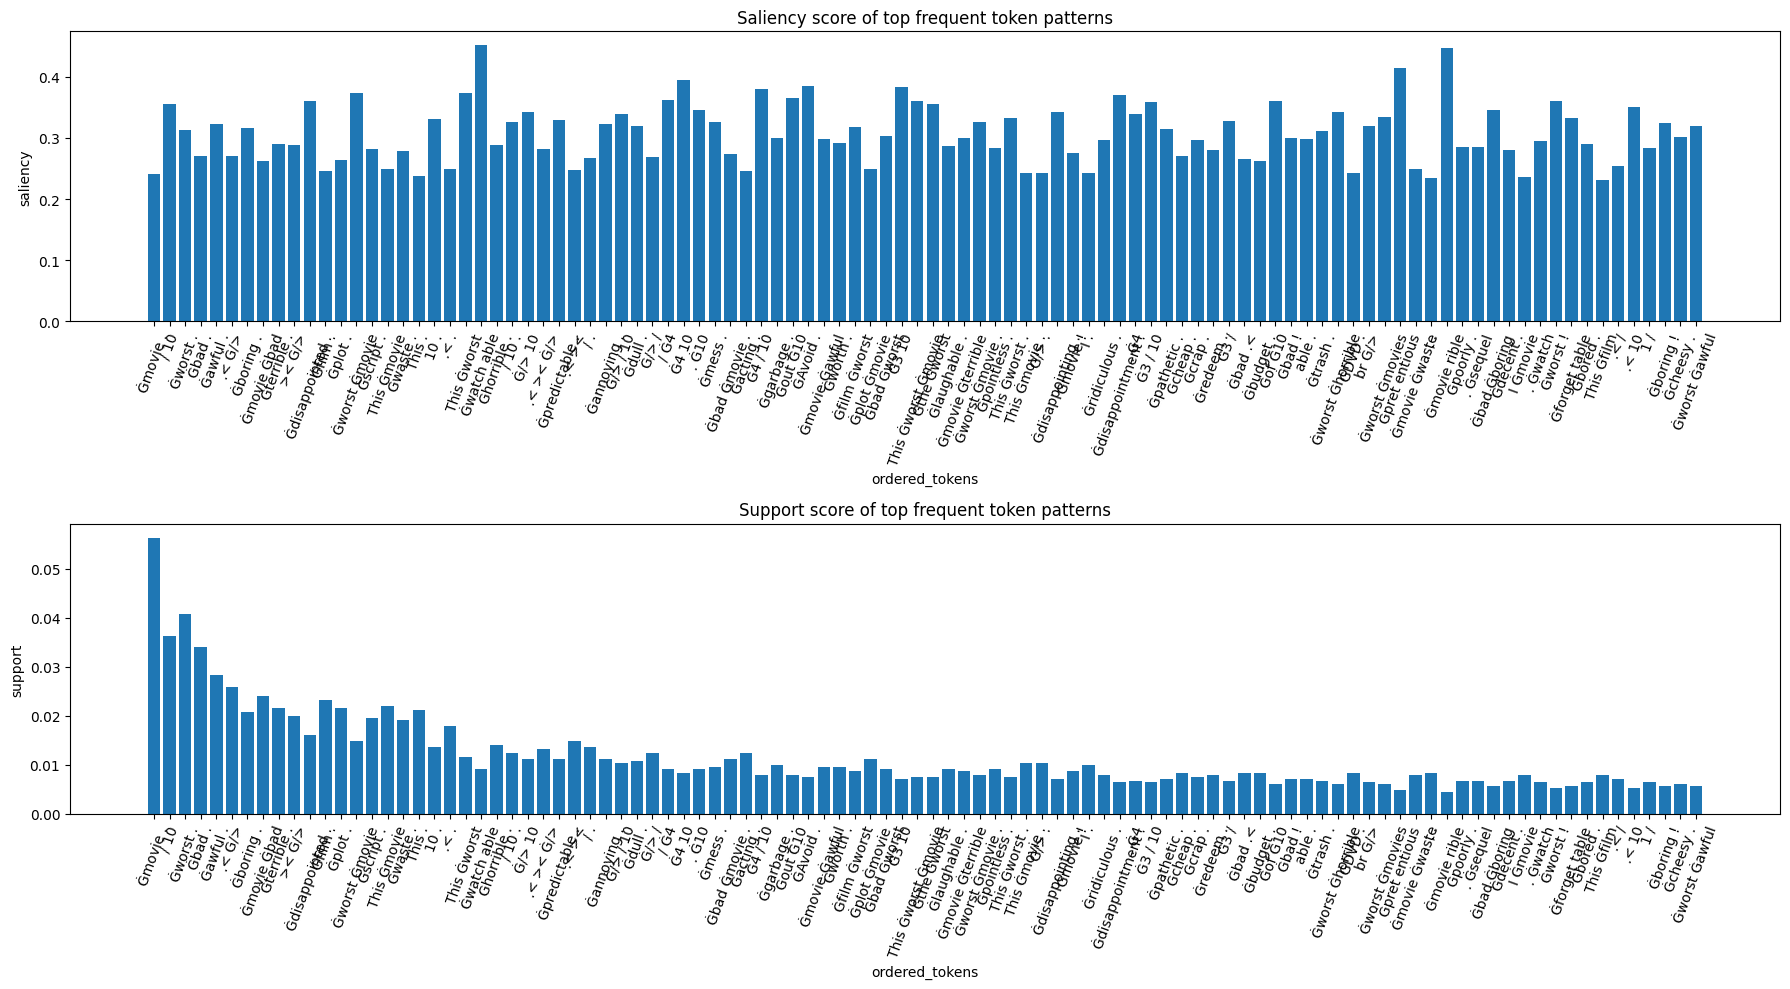

In [26]:
# convert token lists to readable strings
labels = two_grams["ordered_tokens"].apply(lambda x: " ".join(x))

fig, axes = plt.subplots(2, 1, figsize=(18,10))  # 2 rows, 1 column

# first plot
axes[0].bar(labels, two_grams["saliency_score"])
axes[0].set_xlabel("ordered_tokens")
axes[0].set_ylabel("saliency")
axes[0].set_title("Saliency score of top frequent token patterns")
axes[0].tick_params(axis="x", rotation=70)

# second plot (example)
axes[1].bar(labels, two_grams["support"])  # replace with your second data
axes[1].set_xlabel("ordered_tokens")
axes[1].set_ylabel("support")
axes[1].set_title("Support score of top frequent token patterns")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()


Function to extract hidden states for high support tokens.


In [27]:

@torch.no_grad()
def extract_itemset_hidden_states(
    model,
    tokenizer,
    itemsets_token_ids,
    device,
    layers=LAYERS,
    context_mode="isolated",     # "isolated" or "template"
    template_prefix="The movie is",
    batch_size=32,
    num_labels=2,
):
    """
    Extract hidden states for a mined token group from GPT-2.

    GPT-2 adaptation
    ----------------
    BERT used:
        [CLS] + prefix + itemset + [SEP]

    GPT-2 uses:
        prefix + itemset

    There is deliberately NO suffix after the itemset. Because GPT-2 is causal,
    the final token of the itemset is the first representation that has observed
    the complete ordered token group.

    Returns
    -------
    out:
        dict[layer] -> list[np.ndarray(itemset_len, hidden_dim)]

    logits_out:
        Fine-tuned GPT-2: classification logits.
        Pretrained GPT2Model: NaNs (there is no classifier head).
    """
    model.eval()

    pad_id = tokenizer.pad_token_id
    if pad_id is None:
        raise ValueError("GPT-2 tokenizer must have pad_token_id configured.")

    if context_mode == "isolated":
        base_ids = []
    elif context_mode == "template":
        base_ids = tokenizer(
            template_prefix,
            add_special_tokens=False
        ).input_ids
    else:
        raise ValueError("context_mode must be 'isolated' or 'template'")

    token_start = len(base_ids)

    out = {L: [] for L in layers}
    logits_out = []

    for start in range(0, len(itemsets_token_ids), batch_size):
        batch_itemsets = itemsets_token_ids[start:start + batch_size]

        input_ids_list = []
        token_ranges = []

        for ids in batch_itemsets:
            ids = [int(t) for t in ids]

            # GPT-2: no CLS/SEP.
            full_ids = base_ids + ids

            input_ids_list.append(full_ids)
            token_ranges.append(
                (token_start, token_start + len(ids))
            )

        max_len = max(len(x) for x in input_ids_list)

        padded_input_ids = []
        attention_masks = []

        for ids in input_ids_list:
            pad_len = max_len - len(ids)

            padded_input_ids.append(
                ids + [pad_id] * pad_len
            )
            attention_masks.append(
                [1] * len(ids) + [0] * pad_len
            )

        input_ids = torch.tensor(
            padded_input_ids,
            dtype=torch.long,
            device=device,
        )

        attention_mask = torch.tensor(
            attention_masks,
            dtype=torch.long,
            device=device,
        )

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_hidden_states=True,
            return_dict=True,
        )

        if hasattr(outputs, "logits"):
            logits_out.append(
                outputs.logits.detach().cpu().numpy()
            )
        else:
            bsz = input_ids.shape[0]
            logits_out.append(
                np.full(
                    (bsz, num_labels),
                    np.nan,
                    dtype=float,
                )
            )

        hs = outputs.hidden_states

        # hidden_states[0] = embedding output
        # hidden_states[L] = output after GPT-2 transformer block L
        for b_idx, (s, e) in enumerate(token_ranges):
            for L in layers:
                vecs = (
                    hs[L][b_idx, s:e, :]
                    .detach()
                    .cpu()
                    .numpy()
                )
                out[L].append(vecs)

    logits_out = np.vstack(logits_out)

    return out, logits_out


Run Function for isolated tokens and for tokens within a template


In [28]:
layers = (5, 8, 11, 12)
itemset_ids = two_grams["ordered_ids"].tolist()

# Pretrained
pt_iso, pt_logits_iso = extract_itemset_hidden_states(
    pt_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
pt_tpl, pt_logits_tpl = extract_itemset_hidden_states(
    pt_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Finetuned
ft_iso, ft_logits_iso = extract_itemset_hidden_states(
    ft_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
ft_tpl, ft_logits_tpl = extract_itemset_hidden_states(
    ft_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)


Add to dataframe


In [29]:
for L in layers:
    two_grams[f"pt_iso_l{L}"] = list(pt_iso[L])
    two_grams[f"pt_tpl_l{L}"] = list(pt_tpl[L])
    two_grams[f"ft_iso_l{L}"] = list(ft_iso[L])
    two_grams[f"ft_tpl_l{L}"] = list(ft_tpl[L])


Inspect consine/euclidean distance between mean embeddings l12 from pre trained and finetuned bert per itemset


In [77]:

import numpy as np

# GPT-2 primary representation for a multi-token shortcut:
# the final token has seen every preceding token in the shortcut.
GROUP_REDUCTION = "mean"#"last_token"

def pool(x, mode=GROUP_REDUCTION):
    x = np.asarray(x)

    if x.ndim == 1:
        return x

    if mode == "last_token":
        return x[-1]
    if mode == "mean":
        return x.mean(axis=0)
    if mode == "sum":
        return x.sum(axis=0)
    if mode == "first_token":
        return x[0]

    raise ValueError("mode must be last_token, mean, sum, or first_token")


def cos_shift(pt, ft, mode=GROUP_REDUCTION):
    a = pool(pt, mode)
    b = pool(ft, mode)

    denom = np.linalg.norm(a) * np.linalg.norm(b)
    if denom == 0:
        return np.nan

    cos = np.dot(a, b) / denom
    return 1 - cos


def euc_dist(pt, ft, mode=GROUP_REDUCTION):
    a = pool(pt, mode)
    b = pool(ft, mode)
    return np.linalg.norm(a - b)


layers = LAYERS

top = (
    two_grams
    .sort_values("support", ascending=False)
    .head(30)
    .copy()
)

for L in layers:
    top[f"cos_shift_iso_l{L}"] = [
        cos_shift(pt, ft)
        if pt is not None and ft is not None else None
        for pt, ft in zip(
            top[f"pt_iso_l{L}"],
            top[f"ft_iso_l{L}"],
        )
    ]

    top[f"euc_iso_l{L}"] = [
        euc_dist(pt, ft)
        if pt is not None and ft is not None else None
        for pt, ft in zip(
            top[f"pt_iso_l{L}"],
            top[f"ft_iso_l{L}"],
        )
    ]

    top[f"cos_shift_tpl_l{L}"] = [
        cos_shift(pt, ft)
        if pt is not None and ft is not None else None
        for pt, ft in zip(
            top[f"pt_tpl_l{L}"],
            top[f"ft_tpl_l{L}"],
        )
    ]

    top[f"euc_tpl_l{L}"] = [
        euc_dist(pt, ft)
        if pt is not None and ft is not None else None
        for pt, ft in zip(
            top[f"pt_tpl_l{L}"],
            top[f"ft_tpl_l{L}"],
        )
    ]

print("Primary GPT-2 group reduction:", GROUP_REDUCTION)


Primary GPT-2 group reduction: mean


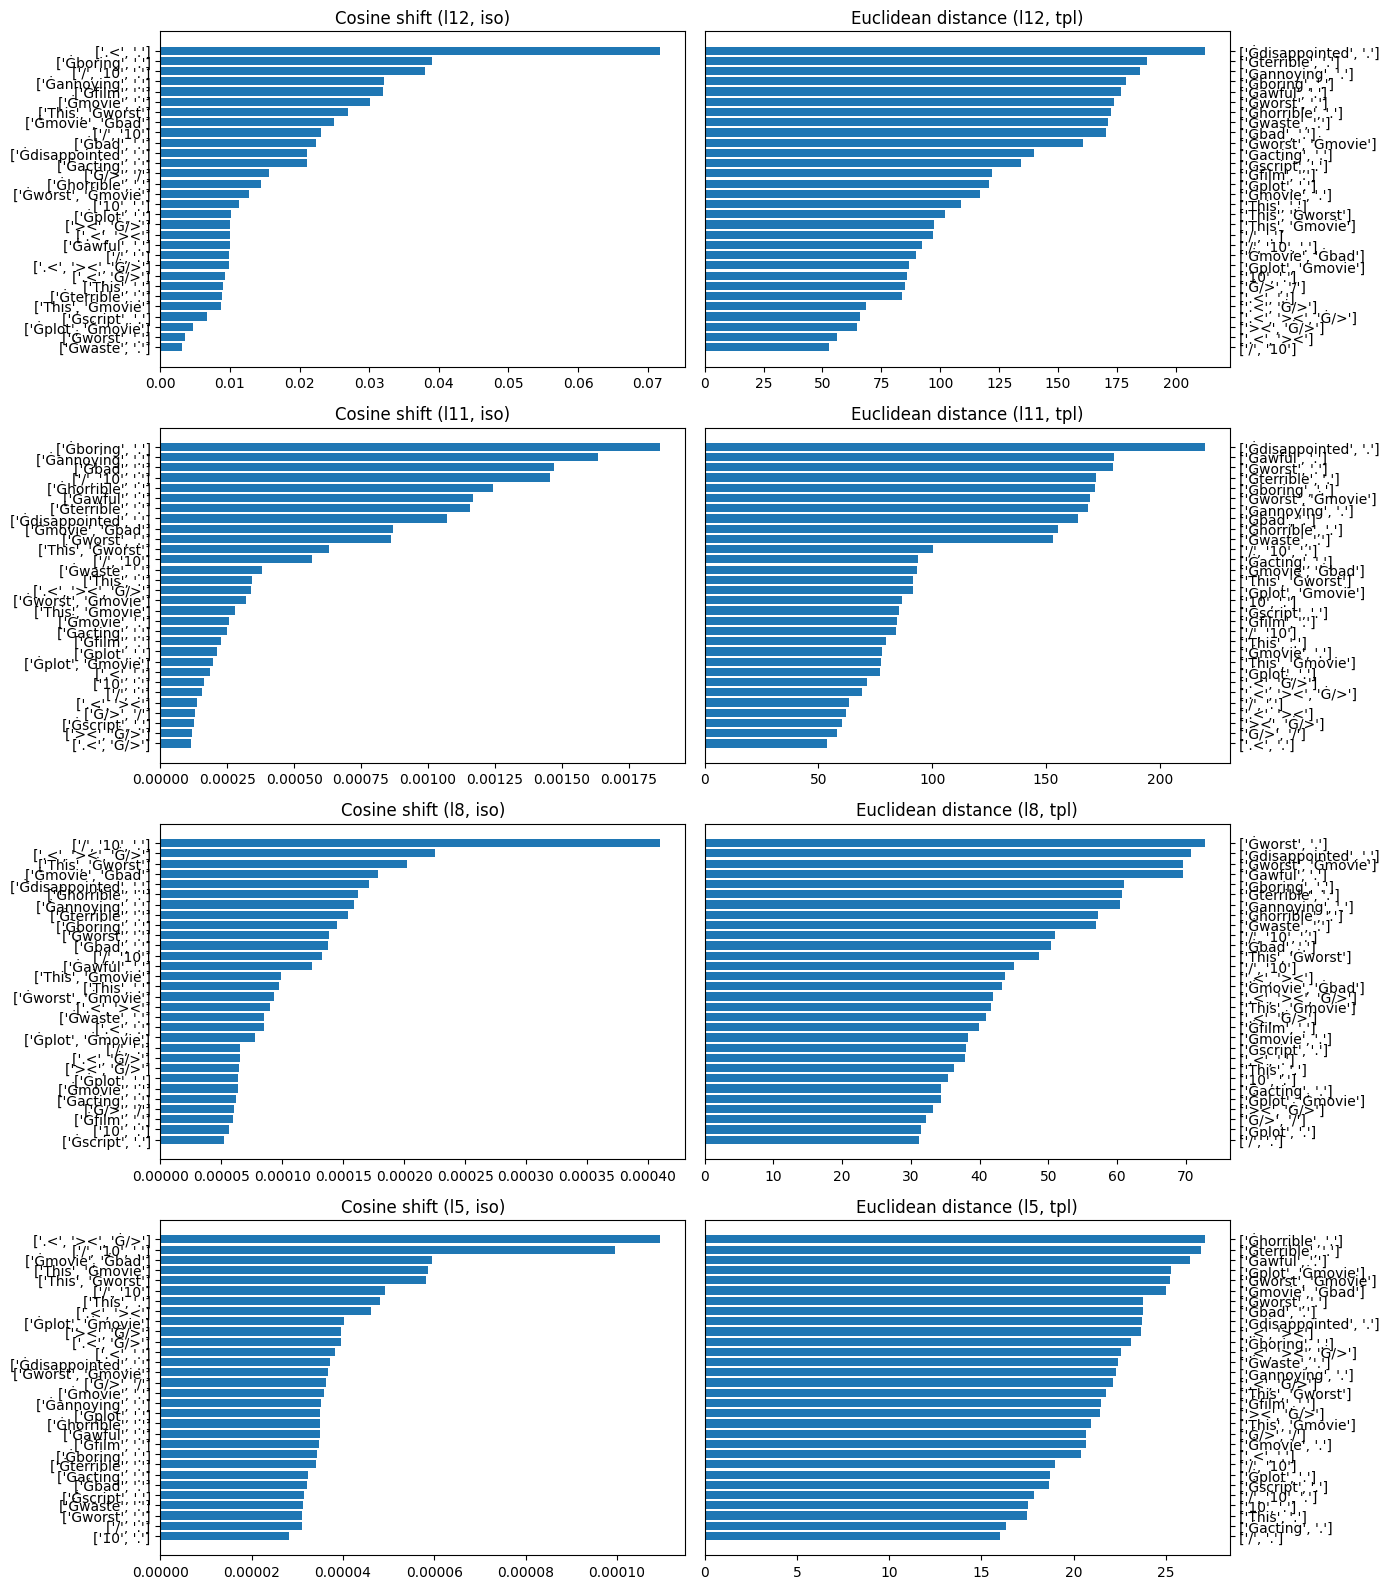

In [78]:
# Experiments

layers = (12,11,8,5)

fig, axes = plt.subplots(len(layers), 2, figsize=(14, 4 * len(layers)))
plt.subplots_adjust(wspace=0.6, hspace=0.4)

for i, L in enumerate(layers):
    # --- Cosine ---
    s1 = top.sort_values(f"cos_shift_iso_l{L}", ascending=False)
    axes[i, 0].barh(range(len(s1)), s1[f"cos_shift_iso_l{L}"])
    axes[i, 0].set_yticks(range(len(s1)))
    axes[i, 0].set_yticklabels(s1.ordered_tokens)
    axes[i, 0].set_title(f"Cosine shift (l{L}, iso)")
    axes[i, 0].invert_yaxis()

    # --- Euclidean ---
    s2 = top.sort_values(f"euc_tpl_l{L}", ascending=False)
    axes[i, 1].barh(range(len(s2)), s2[f"euc_tpl_l{L}"])
    axes[i, 1].set_yticks(range(len(s2)))
    axes[i, 1].set_yticklabels(s2.ordered_tokens)
    axes[i, 1].set_title(f"Euclidean distance (l{L}, tpl)")
    axes[i, 1].invert_yaxis()

    # move right labels outward to avoid overlap
    axes[i, 1].yaxis.tick_right()

plt.tight_layout()


Adding Manual Lables for testings purposes.


In [79]:

# =====================================================
# Manual shortcut labels must be redone for GPT-2
# =====================================================
#
# DO NOT reuse the old BERT labels here:
# GPT-2 uses a different tokenizer and will mine a different ranked list.
#
# Inspect the newly mined GPT-2 groups first.
display_cols = [
    c for c in [
        "ordered_tokens",
        "ordered_text",
        "support",
        "saliency_score",
        "score",
    ]
    if c in two_grams.columns
]

display(two_grams[display_cols].head(100))

# After inspection, manually provide one label per row if you want to run
# shortcut-vs-non-shortcut PCA later, for example:
#
# shortcut_labels = [1, 0, 0, ...]  # exactly len(two_grams) entries
# two_grams["shortcuts"] = shortcut_labels
#
# Until then, leave the labels unassigned.
if "shortcuts" not in two_grams.columns:
    two_grams["shortcuts"] = np.nan


,ordered_tokens,ordered_text,support,saliency_score,score
964,"[Ġmovie, .]",movie.,0.0564,0.240685,0.013575
1073,"[/, 10]",/10,0.0364,0.355178,0.012928
1025,"[Ġworst, .]",worst.,0.0408,0.313751,0.012801
1207,"[Ġbad, .]",bad.,0.0340,0.269931,0.009178
992,"[Ġawful, .]",awful.,0.0284,0.323079,0.009175
...,...,...,...,...,...
1075,"[.<, 10]",.<10,0.0052,0.350197,0.001821
1252,"[1, /]",1/,0.0064,0.283979,0.001817
1042,"[Ġboring, !]",boring!,0.0056,0.323977,0.001814
1296,"[Ġcheesy, .]",cheesy.,0.0060,0.302065,0.001812


In [80]:

def ids_to_string(x):
    if isinstance(x, (list, tuple)):
        return " | ".join(map(str, x))
    return str(x)


def row_to_single_vector(x, reduce_mode="last_token"):
    arr = np.asarray(x, dtype=float)

    if arr.ndim == 1:
        return arr

    if arr.ndim == 2:
        if reduce_mode == "last_token":
            return arr[-1]
        elif reduce_mode == "mean":
            return arr.mean(axis=0)
        elif reduce_mode == "sum":
            return arr.sum(axis=0)
        elif reduce_mode == "first_token":
            return arr[0]
        else:
            raise ValueError(
                "reduce_mode must be 'last_token', 'mean', 'sum', or 'first_token'"
            )

    raise ValueError(f"Unexpected embedding shape: {arr.shape}")


def plot_3d_pca_pt_ft_shortcut(
    df,
    pt_col,
    ft_col,
    ordered_tokens_col="ordered_tokens",
    shortcut_col="shortcuts",
    reduce_mode="last_token",
    title=None,
    annotate_ids=False,
    annotate_top_n=None,
):
    """
    Plot pretrained vs fine-tuned group representations.

    For GPT-2, reduce_mode='last_token' is the primary analysis because the
    final shortcut token has observed the complete preceding shortcut sequence.
    """
    if shortcut_col not in df.columns or df[shortcut_col].isna().all():
        raise ValueError(
            "No GPT-2 shortcut labels are assigned yet. "
            "Inspect the mined GPT-2 groups and populate two_grams['shortcuts'] first."
        )

    work_df = (
        df[[pt_col, ft_col, ordered_tokens_col, shortcut_col]]
        .copy()
        .reset_index(drop=True)
    )

    work_df["pt_vec"] = work_df[pt_col].apply(
        lambda x: row_to_single_vector(x, reduce_mode=reduce_mode)
    )
    work_df["ft_vec"] = work_df[ft_col].apply(
        lambda x: row_to_single_vector(x, reduce_mode=reduce_mode)
    )

    vecs_pt = np.vstack(work_df["pt_vec"].to_numpy())
    vecs_ft = np.vstack(work_df["ft_vec"].to_numpy())

    combined = np.vstack([vecs_pt, vecs_ft])

    pca = PCA(n_components=3)
    coords = pca.fit_transform(combined)

    n = len(work_df)

    plot_df = pd.DataFrame({
        "PC1": coords[:, 0],
        "PC2": coords[:, 1],
        "PC3": coords[:, 2],
        "embedding_type": ["PT"] * n + ["FT"] * n,
        "shortcut": work_df[shortcut_col].tolist() + work_df[shortcut_col].tolist(),
        "ordered_tokens": (
            work_df[ordered_tokens_col].apply(ids_to_string).tolist()
            + work_df[ordered_tokens_col].apply(ids_to_string).tolist()
        ),
    })

    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")

    for emb_type, marker in [("PT", "o"), ("FT", "^")]:
        for shortcut_value in sorted(plot_df["shortcut"].dropna().unique()):
            subset = plot_df[
                (plot_df["embedding_type"] == emb_type)
                & (plot_df["shortcut"] == shortcut_value)
            ]

            ax.scatter(
                subset["PC1"],
                subset["PC2"],
                subset["PC3"],
                marker=marker,
                alpha=0.75,
                label=f"{emb_type}, shortcut={shortcut_value}",
            )

    if annotate_ids:
        ann_df = plot_df if annotate_top_n is None else plot_df.head(annotate_top_n)
        for _, row in ann_df.iterrows():
            ax.text(
                row["PC1"],
                row["PC2"],
                row["PC3"],
                row["ordered_tokens"],
                fontsize=8,
            )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title(
        title or f"3D PCA: {pt_col} vs {ft_col} ({reduce_mode})"
    )
    ax.legend()
    plt.tight_layout()
    plt.show()

    return plot_df, pca


## Experiment 2: Inspecting Hidden States: Layer 5,8,11 and 12

- Using freq_itemset with all tokens since we want a larger pool of tokens for neighbourhood analysis


In [34]:
freq_itemsets_neg_10


,support,itemsets,length,ordered_ids,ordered_tokens,ordered_text,saliency_score,score
0,0.0528,(7110),1,[7110],[Ġplot],plot,0.262680,0.013869
1,0.0032,(13898),1,[13898],[Unfortunately],Unfortunately,0.384932,0.001232
2,0.0020,(10607),1,[10607],[Ġpleased],pleased,0.457898,0.000916
3,0.3512,(13),1,[13],[.],.,0.253572,0.089054
4,0.1344,(3807),1,[3807],[Ġmovie],movie,0.235648,0.031671
...,...,...,...,...,...,...,...,...
1894,0.0028,"(3684, 16948)",2,"[3684, 16948]","[Ġunf, unny]",unfunny,0.322674,0.000903
1895,0.0020,"(4420, 13)",2,"[4420, 13]","[ingly, .]",ingly.,0.270306,0.000541
1896,0.0020,"(12876, 13)",2,"[12876, 13]","[Ġok, .]",ok.,0.273930,0.000548
1897,0.0036,"(22364, 13)",2,"[22364, 13]","[Ġstereotypes, .]",stereotypes.,0.262928,0.000947


In [35]:
neighbour_analysis_df = freq_itemsets_neg_10[freq_itemsets_neg_10["length"] > 0].sort_values("score", ascending=False)


Adding Hidden States


In [36]:
layers = (5, 8, 11, 12)
itemset_ids = neighbour_analysis_df["ordered_ids"].tolist()

# Pretrained
pt_iso, pt_logits_iso = extract_itemset_hidden_states(
    pt_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
pt_tpl, pt_logits_tpl = extract_itemset_hidden_states(
    pt_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Finetuned
ft_iso, ft_logits_iso = extract_itemset_hidden_states(
    ft_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
ft_tpl, ft_logits_tpl = extract_itemset_hidden_states(
    ft_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Assign pretrained
neighbour_analysis_df["pt_iso_l5"]  = list(pt_iso[5])
neighbour_analysis_df["pt_iso_l8"]  = list(pt_iso[8])
neighbour_analysis_df["pt_iso_l11"] = list(pt_iso[11])
neighbour_analysis_df["pt_iso_l12"] = list(pt_iso[12])

neighbour_analysis_df["pt_tpl_l5"]  = list(pt_tpl[5])
neighbour_analysis_df["pt_tpl_l8"]  = list(pt_tpl[8])
neighbour_analysis_df["pt_tpl_l11"] = list(pt_tpl[11])
neighbour_analysis_df["pt_tpl_l12"] = list(pt_tpl[12])

# Assign finetuned
neighbour_analysis_df["ft_iso_l5"]  = list(ft_iso[5])
neighbour_analysis_df["ft_iso_l8"]  = list(ft_iso[8])
neighbour_analysis_df["ft_iso_l11"] = list(ft_iso[11])
neighbour_analysis_df["ft_iso_l12"] = list(ft_iso[12])

neighbour_analysis_df["ft_tpl_l5"]  = list(ft_tpl[5])
neighbour_analysis_df["ft_tpl_l8"]  = list(ft_tpl[8])
neighbour_analysis_df["ft_tpl_l11"] = list(ft_tpl[11])
neighbour_analysis_df["ft_tpl_l12"] = list(ft_tpl[12])

# logits
neighbour_analysis_df["ft_iso_logits"] = list(ft_logits_iso)
neighbour_analysis_df["ft_tpl_logits"] = list(ft_logits_tpl)


In [37]:
neighbour_analysis_df.columns


Index(['support', 'itemsets', 'length', 'ordered_ids', 'ordered_tokens',
       'ordered_text', 'saliency_score', 'score', 'pt_iso_l5', 'pt_iso_l8',
       'pt_iso_l11', 'pt_iso_l12', 'pt_tpl_l5', 'pt_tpl_l8', 'pt_tpl_l11',
       'pt_tpl_l12', 'ft_iso_l5', 'ft_iso_l8', 'ft_iso_l11', 'ft_iso_l12',
       'ft_tpl_l5', 'ft_tpl_l8', 'ft_tpl_l11', 'ft_tpl_l12', 'ft_iso_logits',
       'ft_tpl_logits'],
      dtype='object')

Building three dfs for nieghbourhood analysis of embeddings of itemsets:
- Inspecting mean of all tokens from one itemset
- Inspecting just the first embedding of an itemset
- Inspecting the sum of all tokens within an itemset


This code builds a pipeline to visualize embedding differences between  PT and FT BERT using 3-D PCA. 
- It starts from the original neighbour_analysis_df, dynamically aggregates token-level embeddings into a single vector per itemset using one of three selectable strategies (mean, first_token, or sum)
- For a chosen pair of embedding columns (e.g., pt_tpl_l12 vs ft_tpl_l12 or pt_iso_l12 vs ft_iso_l12), it stacks the vectors from both embeddings, runs PCA to reduce them to three dimensions, and plots the results in a 3D scatter plot where each point represents an itemset embedding and colors distinguish the embedding type (pretrained vs finetuned)
- The result allows visual comparison of how itemset representations shift between pretrained and finetuned models under different embedding aggregation strategies.


In [38]:

layers = LAYERS
types = ("pt", "ft")
contexts = ("iso", "tpl")

EMBEDDING_COLS = [
    f"{t}_{ctx}_l{L}"
    for t in types
    for ctx in contexts
    for L in layers
]

BASE_COLS = [
    "support",
    "length",
    "ordered_ids",
    "ordered_tokens",
    "saliency_score",
]


def emb_mean(x):
    return np.asarray(x).mean(axis=0)


def emb_first(x):
    return np.asarray(x)[0]


def emb_last(x):
    # Primary GPT-2 representation:
    # this token has observed the complete shortcut prefix.
    return np.asarray(x)[-1]


def emb_sum(x):
    return np.asarray(x).sum(axis=0)


def get_aggregation_function(mode):
    if mode == "mean":
        return emb_mean
    if mode == "first_token":
        return emb_first
    if mode == "last_token":
        return emb_last
    if mode == "sum":
        return emb_sum

    raise ValueError(
        "mode must be one of: 'mean', 'first_token', 'last_token', 'sum'"
    )


def build_embedding_view(source_df, mode):
    agg_func = get_aggregation_function(mode)

    base_df = source_df[BASE_COLS + EMBEDDING_COLS].copy()
    out_df = base_df[BASE_COLS].copy()

    for col in EMBEDDING_COLS:
        out_df[col] = base_df[col].apply(agg_func)

    return out_df.reset_index(drop=True)


def tokens_to_string(tokens):
    if isinstance(tokens, (list, tuple)):
        return " | ".join(tokens)
    return str(tokens)


def build_pca_input(df, col_a, col_b):
    vecs_a = np.vstack(df[col_a].to_numpy())
    vecs_b = np.vstack(df[col_b].to_numpy())

    combined = np.vstack([vecs_a, vecs_b])

    labels = [col_a] * len(vecs_a) + [col_b] * len(vecs_b)
    itemsets = list(df["ordered_tokens"].apply(tokens_to_string)) * 2
    lengths = list(df["length"]) * 2
    supports = list(df["support"]) * 2

    return combined, labels, itemsets, lengths, supports


def plot_3d_pca_pair(source_df, mode, col_a, col_b, title):
    work_df = build_embedding_view(source_df, mode)

    combined, labels, itemsets, lengths, supports = build_pca_input(
        work_df, col_a, col_b
    )

    pca = PCA(n_components=3)
    coords = pca.fit_transform(combined)

    plot_df = pd.DataFrame({
        "PC1": coords[:, 0],
        "PC2": coords[:, 1],
        "PC3": coords[:, 2],
        "embedding_type": labels,
        "ordered_tokens_str": itemsets,
        "length": lengths,
        "support": supports,
    })

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    mask_a = plot_df["embedding_type"] == col_a
    mask_b = plot_df["embedding_type"] == col_b

    ax.scatter(
        plot_df.loc[mask_a, "PC1"],
        plot_df.loc[mask_a, "PC2"],
        plot_df.loc[mask_a, "PC3"],
        label=col_a,
        alpha=0.7,
    )

    ax.scatter(
        plot_df.loc[mask_b, "PC1"],
        plot_df.loc[mask_b, "PC2"],
        plot_df.loc[mask_b, "PC3"],
        label=col_b,
        alpha=0.7,
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title(f"{title} ({mode})")
    ax.legend()

    plt.tight_layout()
    plt.show()

    return plot_df


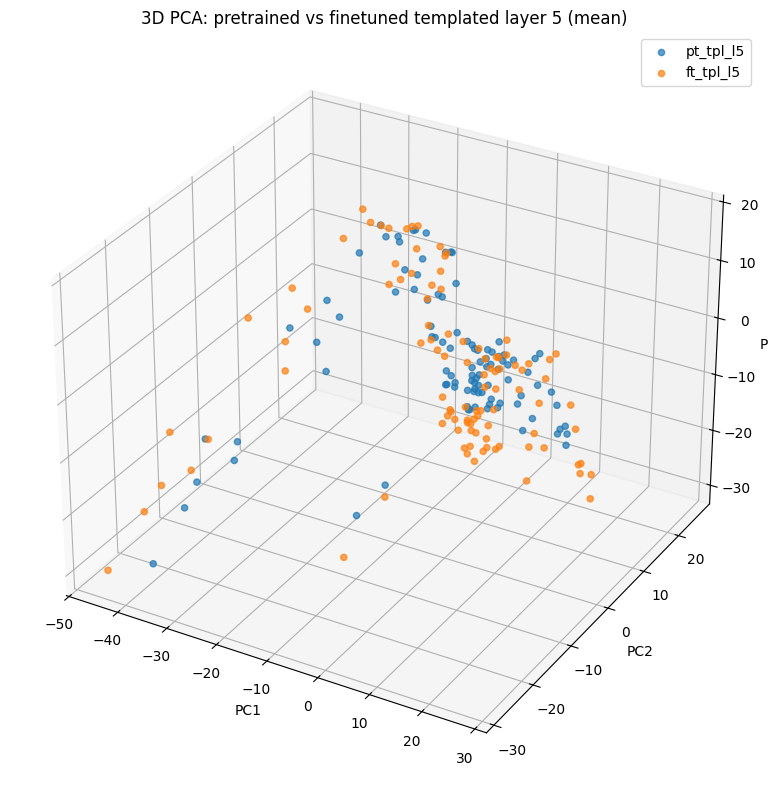

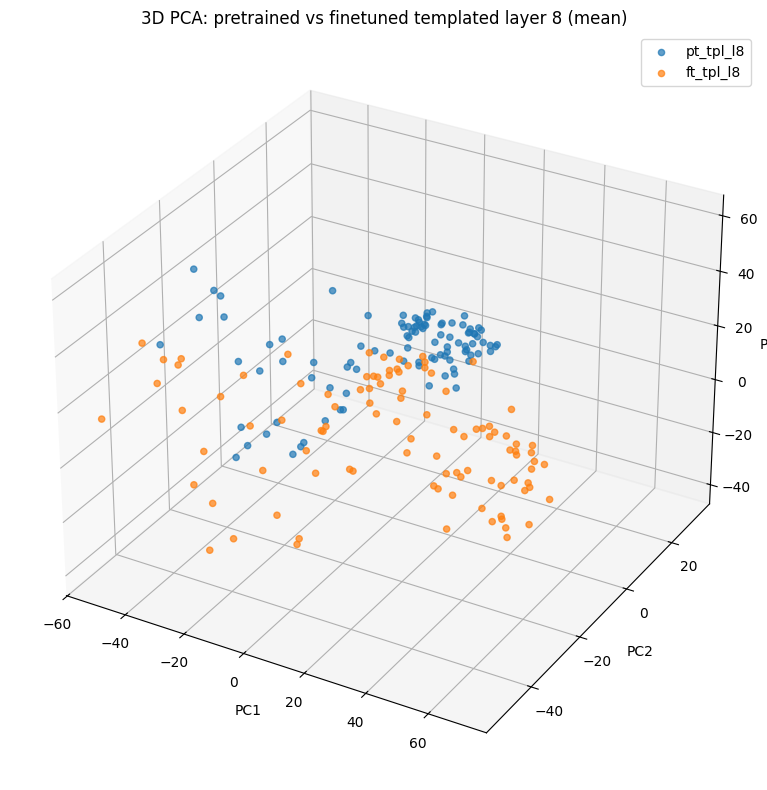

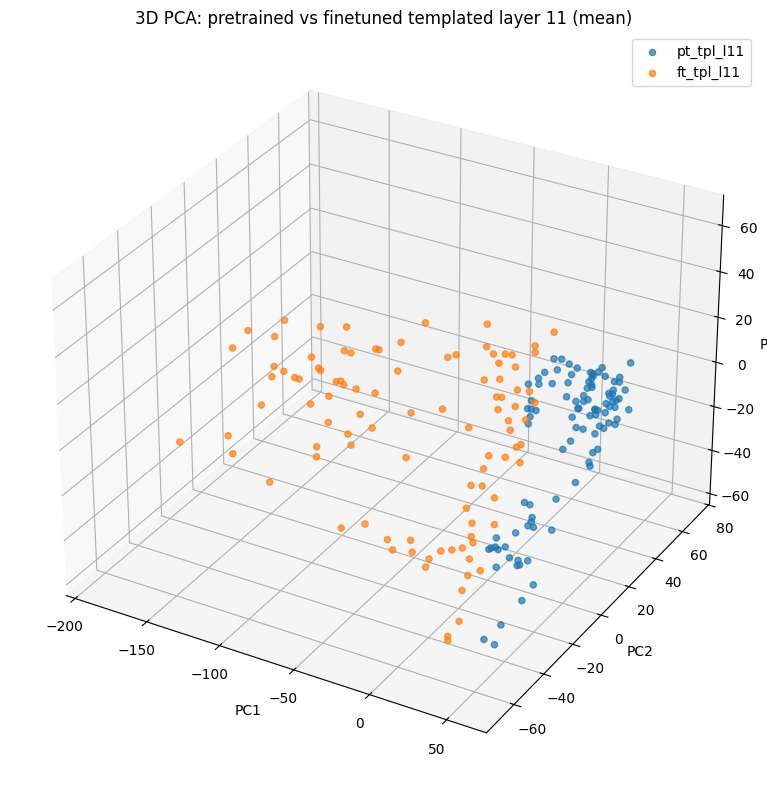

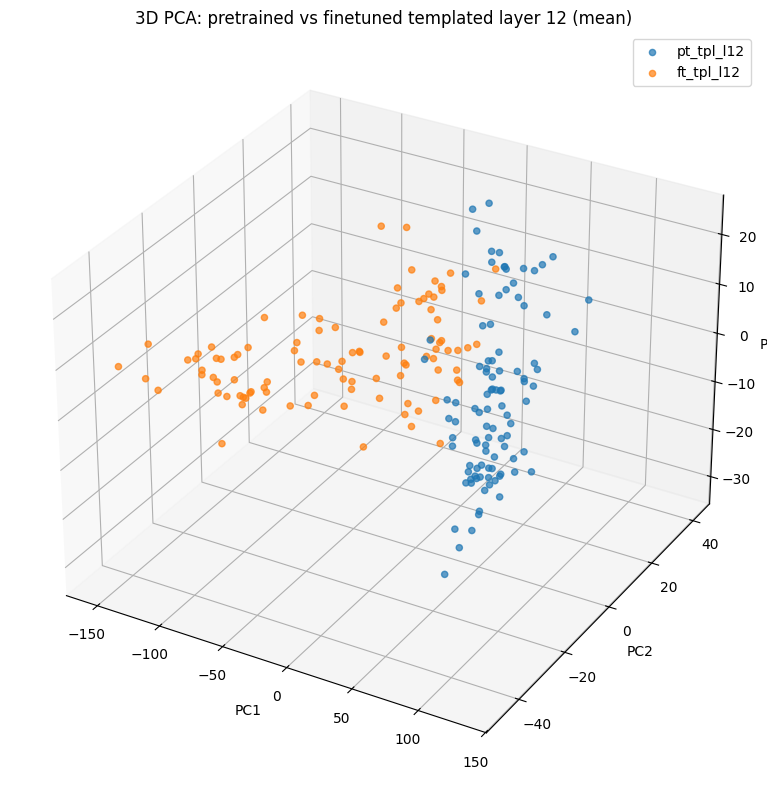

In [39]:
plot_df_tpl_mean_l5 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(100),
    mode="mean",
    col_a="pt_tpl_l5",
    col_b="ft_tpl_l5",
    title="3D PCA: pretrained vs finetuned templated layer 5"
)

plot_df_tpl_mean_l8 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(100),
    mode="mean",
    col_a="pt_tpl_l8",
    col_b="ft_tpl_l8",
    title="3D PCA: pretrained vs finetuned templated layer 8"
)

plot_df_tpl_mean_l11 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(100),
    mode="mean",
    col_a="pt_tpl_l11",
    col_b="ft_tpl_l11",
    title="3D PCA: pretrained vs finetuned templated layer 11"
)

plot_df_tpl_mean_l12 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(100),
    mode="mean",
    col_a="pt_tpl_l12",
    col_b="ft_tpl_l12",
    title="3D PCA: pretrained vs finetuned templated layer 12"
)


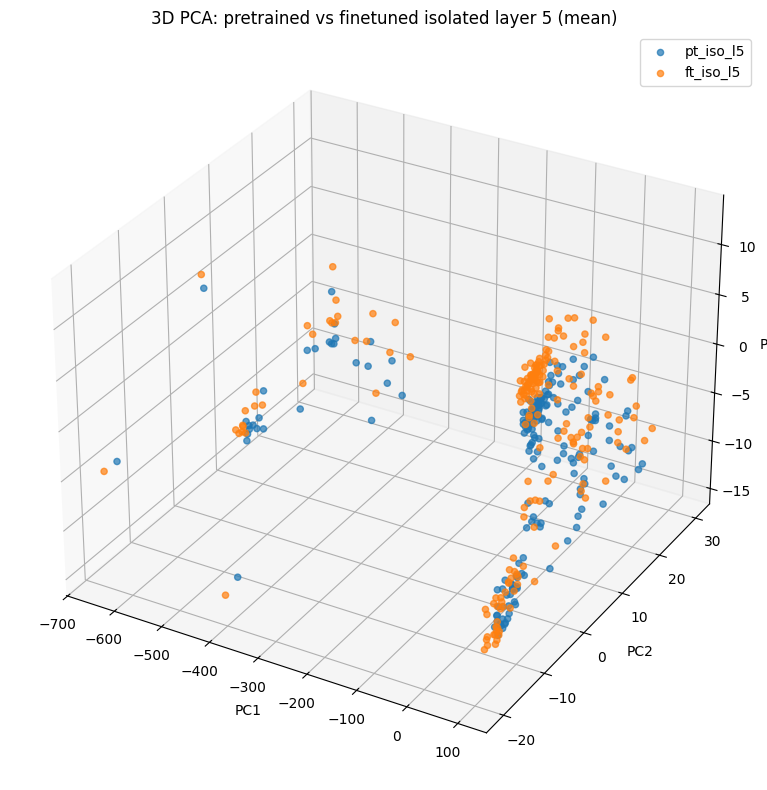

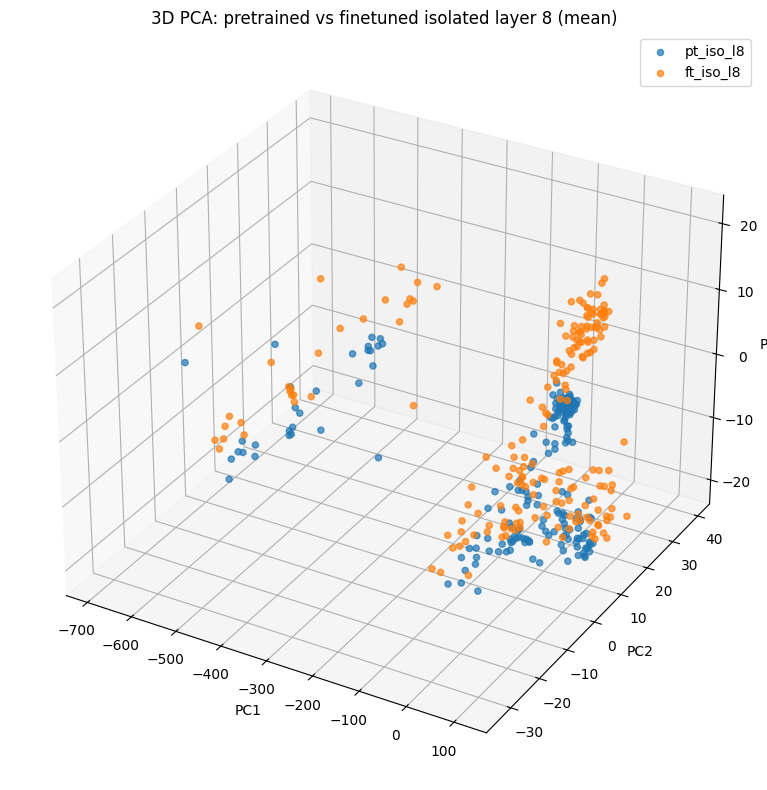

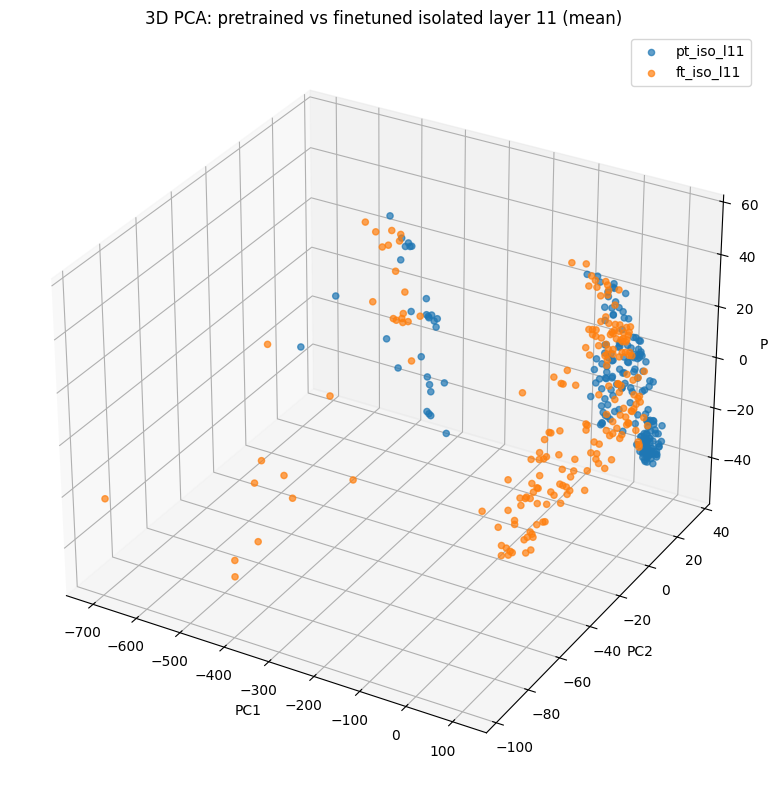

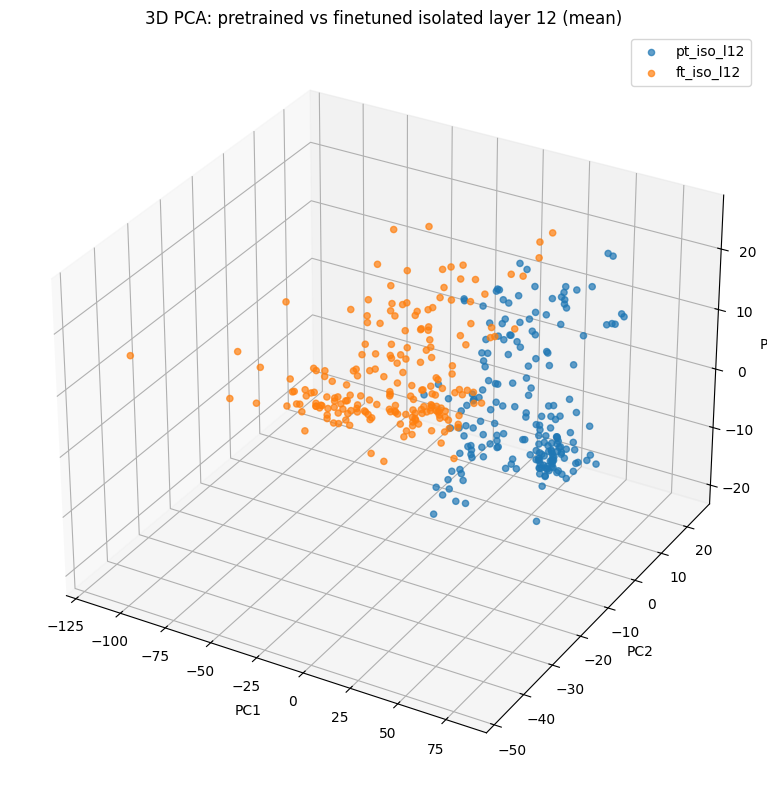

In [40]:
plot_df_iso_mean_l5 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(200),
    mode="mean",
    col_a="pt_iso_l5",
    col_b="ft_iso_l5",
    title="3D PCA: pretrained vs finetuned isolated layer 5"
)

plot_df_iso_mean_l8 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(200),
    mode="mean",
    col_a="pt_iso_l8",
    col_b="ft_iso_l8",
    title="3D PCA: pretrained vs finetuned isolated layer 8"
)

plot_df_iso_mean_l11 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(200),
    mode="mean",
    col_a="pt_iso_l11",
    col_b="ft_iso_l11",
    title="3D PCA: pretrained vs finetuned isolated layer 11"
)

plot_df_iso_mean_l12 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(200),
    mode="mean",
    col_a="pt_iso_l12",
    col_b="ft_iso_l12",
    title="3D PCA: pretrained vs finetuned isolated layer 12"
)


## Experiment 3: Neighbourhood analysis


Aggregating Embeddings


In [41]:

layers = LAYERS
types = ("pt", "ft")
contexts = ("iso", "tpl")

embedding_cols = [
    f"{type_}_{context}_l{layer}"
    for type_ in types
    for context in contexts
    for layer in layers
]

base_cols = [
    "support",
    "length",
    "ordered_ids",
    "ordered_tokens",
    "saliency_score",
]

base_df = neighbour_analysis_df[
    base_cols + embedding_cols
].copy()


def emb_mean(x):
    return np.asarray(x).mean(axis=0)


def emb_first(x):
    return np.asarray(x)[0]


def emb_last(x):
    return np.asarray(x)[-1]


def emb_sum(x):
    return np.asarray(x).sum(axis=0)


df_mean = base_df[base_cols].copy()
df_first_token = base_df[base_cols].copy()
df_last_token = base_df[base_cols].copy()
df_sum = base_df[base_cols].copy()

for col in embedding_cols:
    df_mean[col] = base_df[col].apply(emb_mean)
    df_first_token[col] = base_df[col].apply(emb_first)
    df_last_token[col] = base_df[col].apply(emb_last)
    df_sum[col] = base_df[col].apply(emb_sum)

df_mean = df_mean.reset_index(drop=True)
df_first_token = df_first_token.reset_index(drop=True)
df_last_token = df_last_token.reset_index(drop=True)
df_sum = df_sum.reset_index(drop=True)

print("mean:", df_mean.shape)
print("first:", df_first_token.shape)
print("last (PRIMARY GPT-2):", df_last_token.shape)
print("sum:", df_sum.shape)

display(df_last_token.head(2))


mean: (1899, 21)
first: (1899, 21)
last (PRIMARY GPT-2): (1899, 21)
sum: (1899, 21)


,support,length,ordered_ids,ordered_tokens,saliency_score,pt_iso_l5,pt_iso_l8,pt_iso_l11,pt_iso_l12,pt_tpl_l5,...,pt_tpl_l11,pt_tpl_l12,ft_iso_l5,ft_iso_l8,ft_iso_l11,ft_iso_l12,ft_tpl_l5,ft_tpl_l8,ft_tpl_l11,ft_tpl_l12
0,0.3512,1,[13],[.],0.253572,"[-0.34412244, -0.3693989, 0.08893001, 0.598878...","[-0.5428848, -0.34471357, 0.08806266, 0.374128...","[-0.7055024, 0.008076653, -0.54906857, 0.21792...","[-0.10071249, 0.044424396, -0.25366664, 0.0656...","[0.98082197, -0.3415668, -0.25791728, 0.255630...",...,"[1.8717347, -1.9341642, 0.8093586, -0.79709345...","[0.30781692, -0.117381416, 0.019199558, -0.099...","[-0.6946141, -1.2719994, 0.02143392, -0.165841...","[-0.94179904, -1.3007374, 0.3839978, -0.338025...","[-1.3521535, -0.5692649, -0.27946186, -1.03395...","[-0.19539136, -0.030083712, -0.24745601, 0.016...","[1.8921618, 0.22668736, -0.76985323, -0.621923...","[3.492046, 0.36932835, 0.8987543, -2.6154003, ...","[4.1296945, -0.6000824, 1.1193253, -3.7013822,...","[0.7199881, -0.11713153, -0.045719303, -0.2883..."
1,0.1344,1,[3807],[Ġmovie],0.235648,"[0.2830849, 0.18769503, 0.22438708, -0.3032521...","[0.102294, 0.2389971, 0.17406765, -0.64940494,...","[-0.1371987, 0.68570715, -0.45271283, -0.89291...","[-0.081168644, 0.15403458, -0.36112458, -0.067...","[-0.6056349, 1.5292981, -1.0512731, -0.7246246...",...,"[0.4332128, 7.7449474, -5.127202, -3.4447033, ...","[0.15601689, 1.106275, -1.5419625, -0.67776686...","[0.015402406, -0.740593, -0.15801483, -1.28371...","[-0.20160484, -0.7398606, 0.16158244, -1.59225...","[-0.6998278, 0.094640315, -0.47410792, -2.4001...","[-0.18538903, 0.06847498, -0.41102296, -0.1507...","[0.10409963, 1.670729, -1.5612097, -1.6918776,...","[1.3421721, 4.2313128, -4.403834, -1.86395, -5...","[1.7551243, 8.183756, -4.494884, -2.891842, -7...","[0.2917534, 1.1362109, -1.4832758, -0.56867945..."


Extracting Hidden States for Each token: Layer12


In [42]:

# Extract unique token ids from the mined GPT-2 patterns.
unique_token_ids = sorted(
    set(
        tok
        for ids in df_last_token["ordered_ids"]
        for tok in ids
    )
)

# Map exact GPT-2 token IDs to byte-level-BPE token strings.
id_to_token = {}

for ids, toks in zip(
    df_last_token["ordered_ids"],
    df_last_token["ordered_tokens"],
):
    for i, t in zip(ids, toks):
        id_to_token[i] = t

token_df = pd.DataFrame({
    "token_id": unique_token_ids,
    "token": [id_to_token[i] for i in unique_token_ids],
})

token_df.head()


,token_id,token
0,0,!
1,1,""""
2,7,(
3,8,)
4,9,*


In [43]:

import numpy as np
import torch


@torch.no_grad()
def extract_token_hidden_states(
    model,
    tokenizer,
    token_ids,
    device,
    layers=LAYERS,
    context_mode="isolated",     # "isolated" or "template"
    template_prefix="The movie is",
    batch_size=64,
):
    """
    Extract one GPT-2 token representation per requested vocabulary token.

    isolated:
        token

    template:
        template_prefix + token

    For GPT-2 the token is deliberately the final token, so its hidden state has
    access to the complete left context.
    """
    model.eval()

    pad_id = tokenizer.pad_token_id
    if pad_id is None:
        raise ValueError("GPT-2 tokenizer must have pad_token_id configured.")

    if context_mode == "isolated":
        base_ids = []
    elif context_mode == "template":
        base_ids = tokenizer(
            template_prefix,
            add_special_tokens=False
        ).input_ids
    else:
        raise ValueError(
            "context_mode must be 'isolated' or 'template'"
        )

    token_pos = len(base_ids)

    all_vecs = {L: [] for L in layers}

    for start in range(0, len(token_ids), batch_size):
        batch_ids = [
            int(t)
            for t in token_ids[start:start + batch_size]
        ]

        input_ids_list = [
            base_ids + [tok_id]
            for tok_id in batch_ids
        ]

        max_len = max(len(x) for x in input_ids_list)

        padded_input_ids = []
        attention_masks = []

        for ids in input_ids_list:
            pad_len = max_len - len(ids)

            padded_input_ids.append(
                ids + [pad_id] * pad_len
            )

            attention_masks.append(
                [1] * len(ids) + [0] * pad_len
            )

        input_ids = torch.tensor(
            padded_input_ids,
            dtype=torch.long,
            device=device,
        )

        attention_mask = torch.tensor(
            attention_masks,
            dtype=torch.long,
            device=device,
        )

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_hidden_states=True,
            return_dict=True,
        )

        for L in layers:
            vecs = (
                outputs.hidden_states[L][:, token_pos, :]
                .detach()
                .cpu()
                .numpy()
            )

            all_vecs[L].append(vecs)

    return {
        L: np.vstack(all_vecs[L])
        for L in layers
    }


In [44]:
layers = (5, 8, 11, 12)

# extract isolated embeddings
pt_iso = extract_token_hidden_states(
    model=pt_gpt2,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="isolated",
)

ft_iso = extract_token_hidden_states(
    model=ft_gpt2,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="isolated",
)

# extract templated embeddings
pt_tpl = extract_token_hidden_states(
    model=pt_gpt2,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="template",
)

ft_tpl = extract_token_hidden_states(
    model=ft_gpt2,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="template",
)

# store as vectors in the dataframe
for L in layers:
    token_df[f"pt_iso_l{L}"] = list(pt_iso[L])
    token_df[f"ft_iso_l{L}"] = list(ft_iso[L])
    token_df[f"pt_tpl_l{L}"] = list(pt_tpl[L])
    token_df[f"ft_tpl_l{L}"] = list(ft_tpl[L])

token_df.head()


,token_id,token,pt_iso_l5,ft_iso_l5,pt_tpl_l5,ft_tpl_l5,pt_iso_l8,ft_iso_l8,pt_tpl_l8,ft_tpl_l8,pt_iso_l11,ft_iso_l11,pt_tpl_l11,ft_tpl_l11,pt_iso_l12,ft_iso_l12,pt_tpl_l12,ft_tpl_l12
0,0,!,"[-0.8859215, -0.45970833, 0.601935, 0.7686564,...","[-1.2074177, -1.3749028, 0.7692618, -0.2010979...","[0.0610649, -1.5238783, -0.33707047, -1.160708...","[1.1537315, -2.2472394, -0.08711304, -2.523498...","[-1.127248, -0.4113569, 0.66267836, 0.5469148,...","[-1.4935672, -1.3771652, 1.1847832, -0.3884570...","[1.2488426, -2.1599503, -0.97494256, -2.089290...","[2.9189293, -3.7620742, 2.4624195, -2.378484, ...","[-1.4086221, 0.0450102, 0.0431633, 0.3862875, ...","[-2.0218647, -0.52946615, 0.55029, -1.1060941,...","[2.0023, -3.437622, -1.0201507, -3.7045405, 1....","[8.199314, -6.6775827, -0.6626796, -8.287618, ...","[-0.20574906, 0.07202934, -0.18510175, 0.07444...","[-0.31597835, -0.0019393936, -0.14781158, 0.01...","[0.24047843, -0.21396205, -0.16945077, -0.2734...","[0.6490609, -0.3624757, -0.061584566, -0.38091..."
1,1,"""","[-0.076905124, -0.20140025, -0.23725581, -0.90...","[-0.36307877, -1.0390724, -0.29056722, -1.8848...","[-1.0117576, 1.3795035, -0.9441032, -3.9742777...","[-0.97526467, 1.3826896, -1.3577011, -5.657535...","[-0.28077298, -0.18794003, -0.30750296, -1.194...","[-0.61250734, -1.0746566, -0.015459798, -2.158...","[-1.9801061, 0.9894631, -1.337486, -3.7153385,...","[-0.16050786, 2.357065, -1.389701, -4.8437734,...","[-0.39530817, 0.22618195, -0.919904, -1.392440...","[-0.9732537, -0.2622498, -0.6471726, -2.907081...","[-1.835747, 2.8613334, -3.0896232, -5.0630584,...","[-1.4732974, 2.989852, -4.3338184, -7.6125035,...","[-0.051771905, 0.12072376, -0.42840725, -0.080...","[-0.14034212, 0.06491585, -0.43423793, -0.1555...","[-0.05332607, 0.44989035, -0.5544621, -0.40339...","[-0.09392162, 0.5710789, -0.60575753, -0.52925..."
2,7,(,"[-0.74543387, -0.66464573, 0.47027597, 0.27916...","[-1.062958, -1.6489682, 0.5758208, -0.70098966...","[0.86354446, -1.254179, -2.4630127, -0.3393818...","[1.6835707, -1.3046851, -2.4659724, -1.2103487...","[-0.88461626, -0.62210494, 0.44672787, 0.07223...","[-1.2387327, -1.6525426, 0.90009946, -0.886820...","[-0.66599864, -3.34808, 0.625778, -0.25625613,...","[-0.0819571, -2.9688025, 1.4623743, -0.6541588...","[-1.1855747, -0.28778967, -0.13865262, -0.0604...","[-1.7787181, -0.92131937, 0.3058647, -1.575951...","[-3.33956, -4.1127443, 0.19394608, 0.8200591, ...","[-4.631928, -5.782366, 2.5642715, 1.1193984, 2...","[-0.17398156, 0.053194106, -0.2967986, 0.05272...","[-0.2742228, -0.018506996, -0.28160825, -0.029...","[-0.3142482, -0.6574113, 0.0050784126, 0.07286...","[-0.48691025, -0.79165214, 0.14705738, 0.10563..."
3,8,),"[-1.1323922, -1.0966505, -0.600328, -0.5532265...","[-1.5778409, -2.1106513, -0.6544775, -1.420553...","[-1.9589305, -2.086144, -1.6815777, -2.7463355...","[-1.8863797, -2.9776673, -2.5960824, -5.297942...","[-1.3056903, -1.0614058, -0.61631465, -0.81849...","[-1.789633, -2.132439, -0.32303792, -1.6512778...","[-1.7526174, -2.304078, -0.3920899, -3.047955,...","[-1.1331378, -1.385, -0.3839902, -6.5474987, 3...","[-1.5462111, -0.70105785, -1.307976, -0.925774...","[-2.2744813, -1.3972602, -1.031639, -2.306301,...","[-1.859615, 0.7872919, -3.2749834, -3.6315277,...","[-2.3412013, 0.72184753, -3.6952806, -7.541075...","[-0.1837014, -0.018485494, -0.40841383, -0.048...","[-0.29453507, -0.104267314, -0.4073167, -0.112...","[-0.056800127, 0.24868172, -0.60424376, -0.340...","[-0.15528622, 0.3062912, -0.7379616, -0.499784..."
4,9,*,"[0.26982072, -1.8434185, 0.97882235, -0.265132...","[-0.0179127, -2.9077585, 1.2412872, -1.2532969...","[2.4744594, -2.7391667, 0.11112571, -1.6288979...","[3.6306298, -2.496416, 0.7815461, -1.9393843, ...","[0.10662301, -1.8160976, 1.0251406, -0.5151368...","[-0.22456339, -2.9376922, 1.6338319, -1.475762...","[1.7219219, -4.4878173, 1.9436572, -2.262783, ...","[2.9260385, -2.8053272, 2.954193, -2.7185988, ...","[-0.09095591, -1.448603, 0.4497922, -0

# Find the nearest neighbour of an itemset


In [88]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

def stack_embs(series):
    return np.vstack(series.apply(np.asarray).to_list())

def add_nearest_neighbors(
    query_df,
    token_df,
    query_emb_col,
    token_emb_col,
    prefix,
    k=1,
    metric="cosine",   # "cosine" or "euclidean"
    exclude_constituents=False,
    drop_embedding_cols=False,
    embedding_cols_to_drop=None,
):
    q_mat = stack_embs(query_df[query_emb_col])
    t_mat = stack_embs(token_df[token_emb_col])

    if metric == "cosine":
        scores = cosine_similarity(q_mat, t_mat)
        larger_is_better = True
        score_col = f"{prefix}_nn_cosines"
    elif metric == "euclidean":
        scores = euclidean_distances(q_mat, t_mat)
        larger_is_better = False
        score_col = f"{prefix}_nn_euclidean"
    else:
        raise ValueError("metric must be 'cosine' or 'euclidean'")

    token_ids = token_df["token_id"].values
    token_strs = token_df["token"].values

    nn_token_ids = []
    nn_tokens = []
    nn_scores = []

    for i in range(len(query_df)):
        row = scores[i].copy()

        if exclude_constituents:
            itemset_ids = query_df.iloc[i]["ordered_ids"]
            if larger_is_better:
                row[np.isin(token_ids, list(itemset_ids))] = -np.inf
            else:
                row[np.isin(token_ids, list(itemset_ids))] = np.inf

        top_idx = np.argsort(row)[::-1][:k] if larger_is_better else np.argsort(row)[:k]

        nn_token_ids.append(token_ids[top_idx].tolist())
        nn_tokens.append(token_strs[top_idx].tolist())
        nn_scores.append(row[top_idx].tolist())

    out = query_df.copy()
    out[f"{prefix}_nn_token_ids"] = nn_token_ids
    out[f"{prefix}_nn_tokens"] = nn_tokens
    out[score_col] = nn_scores
    out[f"{prefix}_nn_metric"] = metric

    if drop_embedding_cols:
        if embedding_cols_to_drop is None:
            embedding_cols_to_drop = [c for c in out.columns if "_l" in c]
        cols_to_drop = [c for c in embedding_cols_to_drop if c in out.columns]
        out = out.drop(columns=cols_to_drop)

    return out


In [89]:
from sklearn.metrics.pairwise import euclidean_distances

def add_euclidean_distances(
    df_with_nns,
    query_df,
    token_df,
    query_emb_col,
    token_emb_col,
    nn_ids_col,
    out_col,
):
    out = df_with_nns.copy()

    q_lookup = {
        tuple(row["ordered_ids"]): np.asarray(row[query_emb_col])
        for _, row in query_df.iterrows()
    }
    t_lookup = {
        row["token_id"]: np.asarray(row[token_emb_col])
        for _, row in token_df.iterrows()
    }

    all_dists = []

    for _, row in out.iterrows():
        q_vec = q_lookup[tuple(row["ordered_ids"])].reshape(1, -1)
        dists = []

        for tok_id in row[nn_ids_col]:
            t_vec = t_lookup[tok_id].reshape(1, -1)
            dists.append(euclidean_distances(q_vec, t_vec)[0, 0])

        all_dists.append(dists)

    out[out_col] = all_dists
    return out

def add_cosine_values(
    df_with_nns,
    query_df,
    token_df,
    query_emb_col,
    token_emb_col,
    nn_ids_col,
    out_col,
    as_distance=False,
):
    out = df_with_nns.copy()

    q_lookup = {
        tuple(row["ordered_ids"]): np.asarray(row[query_emb_col])
        for _, row in query_df.iterrows()
    }
    t_lookup = {
        row["token_id"]: np.asarray(row[token_emb_col])
        for _, row in token_df.iterrows()
    }

    all_vals = []

    for _, row in out.iterrows():
        q_vec = q_lookup[tuple(row["ordered_ids"])].reshape(1, -1)
        vals = []

        for tok_id in row[nn_ids_col]:
            t_vec = t_lookup[tok_id].reshape(1, -1)
            cos_sim = cosine_similarity(q_vec, t_vec)[0, 0]
            vals.append(1 - cos_sim if as_distance else cos_sim)

        all_vals.append(vals)

    out[out_col] = all_vals
    return out


In [90]:
import numpy as np

def add_distance_deltas(
    df,
    ft_euclidean_col,
    pt_euclidean_col,
    ft_cosine_col,
    pt_cosine_col,
    out_ft_cosine_distance_col,
    out_delta_euclidean_col,
    out_delta_cosine_col,
    out_mean_delta_euclidean_col=None,
    out_mean_delta_cosine_col=None,
    ft_cosine_is_similarity=True,
):
    out = df.copy()

    if ft_cosine_is_similarity:
        out[out_ft_cosine_distance_col] = out[ft_cosine_col].apply(
            lambda xs: [1 - x for x in xs]
        )
        ft_cosine_distance_col = out_ft_cosine_distance_col
    else:
        ft_cosine_distance_col = ft_cosine_col

    out[out_delta_euclidean_col] = [
        np.abs(np.array(pt) - np.array(ft)).tolist()
        for ft, pt in zip(out[ft_euclidean_col], out[pt_euclidean_col])
    ]

    out[out_delta_cosine_col] = [
        np.abs(np.array(pt) - np.array(ft)).tolist()
        for ft, pt in zip(out[ft_cosine_distance_col], out[pt_cosine_col])
    ]

    if out_mean_delta_euclidean_col is not None:
        out[out_mean_delta_euclidean_col] = out[out_delta_euclidean_col].apply(np.mean)

    if out_mean_delta_cosine_col is not None:
        out[out_mean_delta_cosine_col] = out[out_delta_cosine_col].apply(np.mean)

    return out


In [91]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LAYERS = (12, 11, 8, 5)
ALL_NN_LAYERS = (5, 8, 11, 12)


def run_anchor_analysis(
    df_mean,
    token_df,
    anchor_layer,
    context="iso",   # "iso" or "tpl"
    k=10,
):
    """
    Build full NN / cross-layer distance / delta analysis for one anchor layer.

    Returns a dataframe with:
      - NN columns for all layers
      - FT distances to anchor-layer neighbours across all layers
      - PT distances to same anchor-layer neighbours across all layers
      - FT/PT deltas across all layers
    """
    assert context in {"iso", "tpl"}

    ctx = "iso" if context == "iso" else "tpl"
    out = df_mean.copy()

    # 1) nearest neighbours for all layers in FT space
    for L in ALL_NN_LAYERS:
        prefix = f"ft_{ctx}_l{L}" if ctx == "tpl" else f"ft_l{L}"
        out = add_nearest_neighbors(
            query_df=out,
            token_df=token_df,
            query_emb_col=f"ft_{ctx}_l{L}",
            token_emb_col=f"ft_{ctx}_l{L}",
            prefix=prefix,
            k=k,
            exclude_constituents=True,
        )

    # anchor neighbour ids column
    nn_ids_col = f"ft_{ctx}_l{anchor_layer}_nn_token_ids" if ctx == "tpl" else f"ft_l{anchor_layer}_nn_token_ids"

    # naming prefixes for cross-layer outputs
    ft_base = f"ft_{ctx}_l{anchor_layer}" if ctx == "tpl" else f"ft_l{anchor_layer}"
    pt_base = f"pt_{ctx}_l{anchor_layer}" if ctx == "tpl" else f"pt_l{anchor_layer}"

    # 2) FT/PT distances to the same anchor-layer neighbours across all layers
    for L in LAYERS:
        out = add_euclidean_distances(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=f"ft_{ctx}_l{L}",
            token_emb_col=f"ft_{ctx}_l{L}",
            nn_ids_col=nn_ids_col,
            out_col=f"{ft_base}_nns_euclidean_l{L}",
        )

        out = add_cosine_values(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=f"ft_{ctx}_l{L}",
            token_emb_col=f"ft_{ctx}_l{L}",
            nn_ids_col=nn_ids_col,
            out_col=f"{ft_base}_nns_cosine_l{L}",
            as_distance=False,
        )

        out = add_euclidean_distances(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=f"pt_{ctx}_l{L}",
            token_emb_col=f"pt_{ctx}_l{L}",
            nn_ids_col=nn_ids_col,
            out_col=f"{pt_base}_same_nns_euclidean_l{L}",
        )

        out = add_cosine_values(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=f"pt_{ctx}_l{L}",
            token_emb_col=f"pt_{ctx}_l{L}",
            nn_ids_col=nn_ids_col,
            out_col=f"{pt_base}_same_nns_cosdist_l{L}",
            as_distance=True,
        )

    # 3) deltas
    for L in LAYERS:
        if ctx == "iso":
            out = add_distance_deltas(
                df=out,
                ft_euclidean_col=f"{ft_base}_nns_euclidean_l{L}",
                pt_euclidean_col=f"{pt_base}_same_nns_euclidean_l{L}",
                ft_cosine_col=f"{ft_base}_nns_cosine_l{L}",
                pt_cosine_col=f"{pt_base}_same_nns_cosdist_l{L}",
                out_ft_cosine_distance_col=f"{ft_base}_nns_cosdist_l{L}",
                out_delta_euclidean_col=f"delta_l{anchor_layer}_euclidean_l{L}",
                out_delta_cosine_col=f"delta_l{anchor_layer}_cosine_l{L}",
                out_mean_delta_euclidean_col=f"mean_delta_l{anchor_layer}_euclidean_l{L}",
                out_mean_delta_cosine_col=f"mean_delta_l{anchor_layer}_cosine_l{L}",
                ft_cosine_is_similarity=True,
            )
        else:
            out = add_distance_deltas(
                df=out,
                ft_euclidean_col=f"{ft_base}_nns_euclidean_l{L}",
                pt_euclidean_col=f"{pt_base}_same_nns_euclidean_l{L}",
                ft_cosine_col=f"{ft_base}_nns_cosine_l{L}",
                pt_cosine_col=f"{pt_base}_same_nns_cosdist_l{L}",
                out_ft_cosine_distance_col=f"{ft_base}_nns_cosdist_l{L}",
                out_delta_euclidean_col=f"delta_tpl_l{anchor_layer}_euclidean_l{L}",
                out_delta_cosine_col=f"delta_tpl_l{anchor_layer}_cosine_l{L}",
                out_mean_delta_euclidean_col=f"mean_delta_tpl_l{anchor_layer}_euclidean_l{L}",
                out_mean_delta_cosine_col=f"mean_delta_tpl_l{anchor_layer}_cosine_l{L}",
                ft_cosine_is_similarity=True,
            )

    return out


def plot_anchor_overlay(
    df,
    anchor_layer,
    context="iso",   # "iso" or "tpl"
    top_n=50,
    min_length=2,
    sort_col="support",
):
    """
    Overlay bar plots of mean deltas across layers for one anchor layer.
    """
    assert context in {"iso", "tpl"}

    if context == "iso":
        euc_cols = {L: f"mean_delta_l{anchor_layer}_euclidean_l{L}" for L in LAYERS}
        cos_cols = {L: f"mean_delta_l{anchor_layer}_cosine_l{L}" for L in LAYERS}
        title_prefix = f"Layer-{anchor_layer} anchor, isolated"
    else:
        euc_cols = {L: f"mean_delta_tpl_l{anchor_layer}_euclidean_l{L}" for L in LAYERS}
        cos_cols = {L: f"mean_delta_tpl_l{anchor_layer}_cosine_l{L}" for L in LAYERS}
        title_prefix = f"Layer-{anchor_layer} anchor, templated"

    plot_df = (
        df[df["length"] >= min_length]
        .sort_values(sort_col, ascending=False)
        .head(top_n)
        .copy()
    )

    plot_df["label"] = plot_df["ordered_tokens"].apply(
        lambda x: " ".join(x) if isinstance(x, list) else str(x)
    )

    x = np.arange(len(plot_df))
    width = 0.2

    plt.figure(figsize=(20, 6))
    for i, L in enumerate(LAYERS):
        plt.bar(x + i * width, plot_df[euc_cols[L]], width, label=f"L{L}")
    plt.xticks(x + width * (len(LAYERS) - 1) / 2, plot_df["label"], rotation=75, ha="right")
    plt.ylabel("mean delta euclidean")
    plt.title(f"{title_prefix}: mean delta euclidean across layers")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(20, 6))
    for i, L in enumerate(LAYERS):
        plt.bar(x + i * width, plot_df[cos_cols[L]], width, label=f"L{L}")
    plt.xticks(x + width * (len(LAYERS) - 1) / 2, plot_df["label"], rotation=75, ha="right")
    plt.ylabel("mean delta cosine")
    plt.title(f"{title_prefix}: mean delta cosine across layers")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_numeric_vs_non_numeric(
    df,
    anchor_layer,
    context="iso",   # "iso" or "tpl"
):
    """
    Overlay plots for numeric/dash-only vs non-numeric groups across layers.
    """
    assert context in {"iso", "tpl"}

    pattern = re.compile(r'^[0-9\-]+$')

    def tokens_to_string(x):
        return " ".join(x) if isinstance(x, list) else str(x)

    df_plot = df.copy()
    df_plot["token_str"] = df_plot["ordered_tokens"].apply(tokens_to_string)

    is_numeric_dash = df_plot["token_str"].apply(
        lambda x: bool(pattern.fullmatch(x.replace(" ", "")))
    )

    df_numeric_dash = df_plot[is_numeric_dash]
    df_non_numeric = df_plot[~is_numeric_dash]

    if context == "iso":
        euc_name = lambda L: f"mean_delta_l{anchor_layer}_euclidean_l{L}"
        cos_name = lambda L: f"mean_delta_l{anchor_layer}_cosine_l{L}"
        title_prefix = f"Layer-{anchor_layer} anchor, isolated"
    else:
        euc_name = lambda L: f"mean_delta_tpl_l{anchor_layer}_euclidean_l{L}"
        cos_name = lambda L: f"mean_delta_tpl_l{anchor_layer}_cosine_l{L}"
        title_prefix = f"Layer-{anchor_layer} anchor, templated"

    summary_rows = []
    for L in LAYERS:
        summary_rows.append({
            "group": "numeric",
            "layer": f"L{L}",
            "mean_delta_euclidean": df_numeric_dash[euc_name(L)].mean(),
            "mean_delta_cosine": df_numeric_dash[cos_name(L)].mean(),
        })
        summary_rows.append({
            "group": "non_numeric",
            "layer": f"L{L}",
            "mean_delta_euclidean": df_non_numeric[euc_name(L)].mean(),
            "mean_delta_cosine": df_non_numeric[cos_name(L)].mean(),
        })

    summary = pd.DataFrame(summary_rows)

    x = np.arange(len(LAYERS))
    width = 0.35

    plt.figure(figsize=(8, 5))
    num_vals = summary[summary["group"] == "numeric"]["mean_delta_euclidean"].values
    non_vals = summary[summary["group"] == "non_numeric"]["mean_delta_euclidean"].values
    plt.bar(x - width/2, num_vals, width, label="numeric")
    plt.bar(x + width/2, non_vals, width, label="non_numeric")
    plt.xticks(x, [f"L{L}" for L in LAYERS])
    plt.ylabel("average mean delta euclidean")
    plt.title(f"{title_prefix}: numeric vs non-numeric")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    num_vals = summary[summary["group"] == "numeric"]["mean_delta_cosine"].values
    non_vals = summary[summary["group"] == "non_numeric"]["mean_delta_cosine"].values
    plt.bar(x - width/2, num_vals, width, label="numeric")
    plt.bar(x + width/2, non_vals, width, label="non_numeric")
    plt.xticks(x, [f"L{L}" for L in LAYERS])
    plt.ylabel("average mean delta cosine")
    plt.title(f"{title_prefix}: numeric vs non-numeric")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [96]:
import re

def decode_pattern(ids):
    return tokenizer.decode(
        [int(i) for i in ids],
        clean_up_tokenization_spaces=False,
    ).strip()


RATING_PATTERN = re.compile(
    r"^(?:10|[0-9])\s*/\s*10$"
)


def is_rating_pattern(text):
    return bool(
        RATING_PATTERN.fullmatch(text.strip())
    )

In [97]:
#### Version with Standard dev
def plot_numeric_vs_non_numeric(
    df,
    anchor_layer,
    context="iso",
):
    assert context in {"iso", "tpl"}

    df_plot = df.copy()

    # Decode GPT-2 token IDs back into normal text
    df_plot["token_str"] = df_plot["ordered_ids"].apply(
        decode_pattern
    )

    is_numeric_dash = df_plot["token_str"].apply(is_rating_pattern)

    df_numeric_dash = df_plot[is_numeric_dash]
    df_non_numeric = df_plot[~is_numeric_dash]

    if context == "iso":
        euc_name = lambda L: f"mean_delta_l{anchor_layer}_euclidean_l{L}"
        cos_name = lambda L: f"mean_delta_l{anchor_layer}_cosine_l{L}"
        title_prefix = f"Layer-{anchor_layer} anchor, isolated"
    else:
        euc_name = lambda L: f"mean_delta_tpl_l{anchor_layer}_euclidean_l{L}"
        cos_name = lambda L: f"mean_delta_tpl_l{anchor_layer}_cosine_l{L}"
        title_prefix = f"Layer-{anchor_layer} anchor, templated"

    summary_rows = []
    for L in LAYERS:
        summary_rows.append({
            "group": "numeric",
            "layer": f"L{L}",
            "mean_delta_euclidean": df_numeric_dash[euc_name(L)].mean(),
            "std_delta_euclidean": df_numeric_dash[euc_name(L)].std(),
            "mean_delta_cosine": df_numeric_dash[cos_name(L)].mean(),
            "std_delta_cosine": df_numeric_dash[cos_name(L)].std(),
        })
        summary_rows.append({
            "group": "non_numeric",
            "layer": f"L{L}",
            "mean_delta_euclidean": df_non_numeric[euc_name(L)].mean(),
            "std_delta_euclidean": df_non_numeric[euc_name(L)].std(),
            "mean_delta_cosine": df_non_numeric[cos_name(L)].mean(),
            "std_delta_cosine": df_non_numeric[cos_name(L)].std(),
        })

    summary = pd.DataFrame(summary_rows)

    x = np.arange(len(LAYERS))
    width = 0.35

    # --- Euclidean ---
    plt.figure(figsize=(8, 5))

    num = summary[summary["group"] == "numeric"]
    non = summary[summary["group"] == "non_numeric"]

    plt.bar(
        x - width/2,
        num["mean_delta_euclidean"].values,
        width,
        yerr=num["std_delta_euclidean"].values,
        label="numeric",
        capsize=4
    )

    plt.bar(
        x + width/2,
        non["mean_delta_euclidean"].values,
        width,
        yerr=non["std_delta_euclidean"].values,
        label="non_numeric",
        capsize=4
    )

    plt.xticks(x, [f"L{L}" for L in LAYERS])
    plt.ylabel("average mean delta euclidean")
    plt.title(f"{title_prefix}: numeric vs non-numeric")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --- Cosine ---
    plt.figure(figsize=(8, 5))

    plt.bar(
        x - width/2,
        num["mean_delta_cosine"].values,
        width,
        yerr=num["std_delta_cosine"].values,
        label="numeric",
        capsize=4
    )

    plt.bar(
        x + width/2,
        non["mean_delta_cosine"].values,
        width,
        yerr=non["std_delta_cosine"].values,
        label="non_numeric",
        capsize=4
    )

    plt.xticks(x, [f"L{L}" for L in LAYERS])
    plt.ylabel("average mean delta cosine")
    plt.title(f"{title_prefix}: numeric vs non-numeric")
    plt.legend()
    plt.tight_layout()
    plt.show()


#### Version with Standard dev


### Anchor layer 12


### Top 10 Nearest Neighbours

Calculated in finetuned embedding space


Isolated


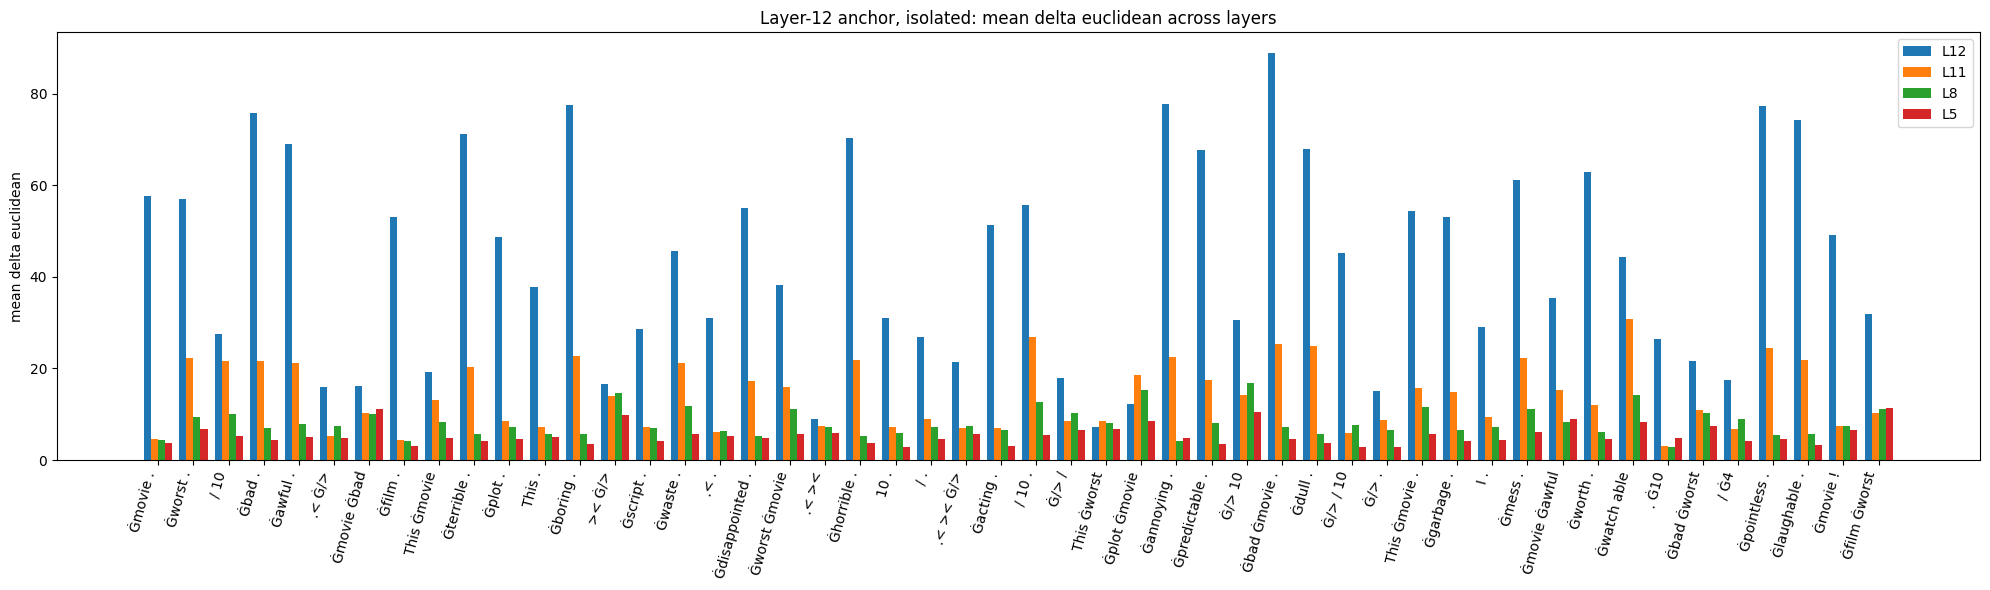

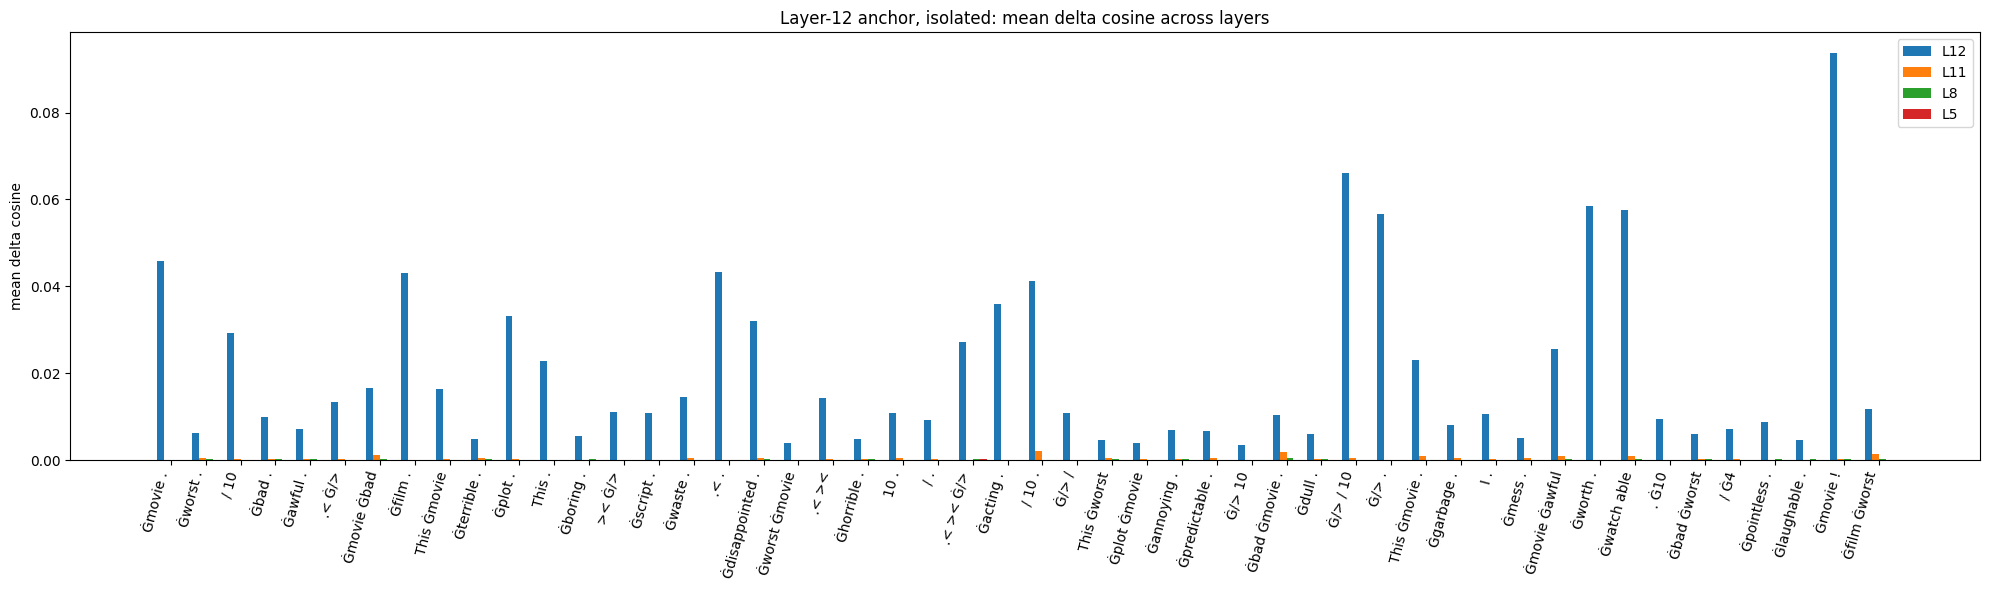

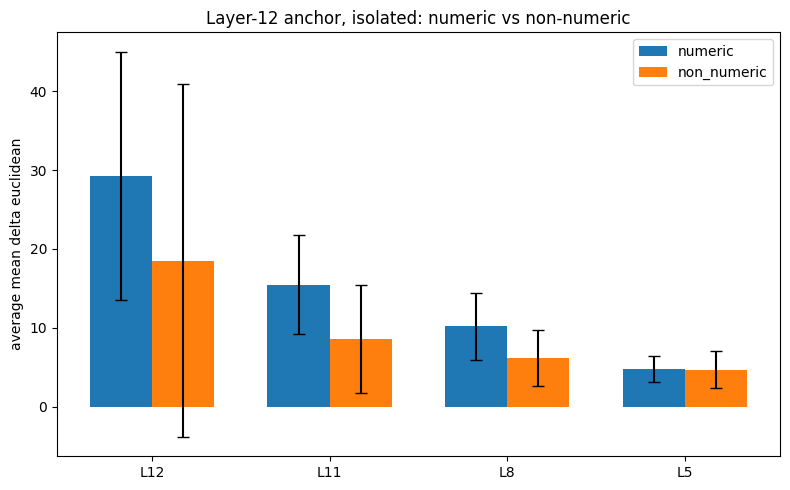

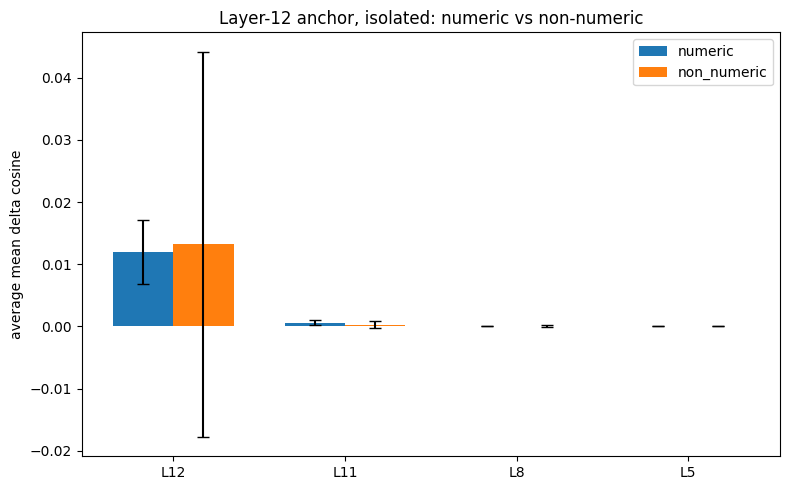

In [98]:
df_iso_l12 = run_anchor_analysis(df_mean, token_df, anchor_layer=12, context="iso")
plot_anchor_overlay(df_iso_l12, anchor_layer=12, context="iso")
plot_numeric_vs_non_numeric(df_iso_l12, anchor_layer=12, context="iso")


Templated


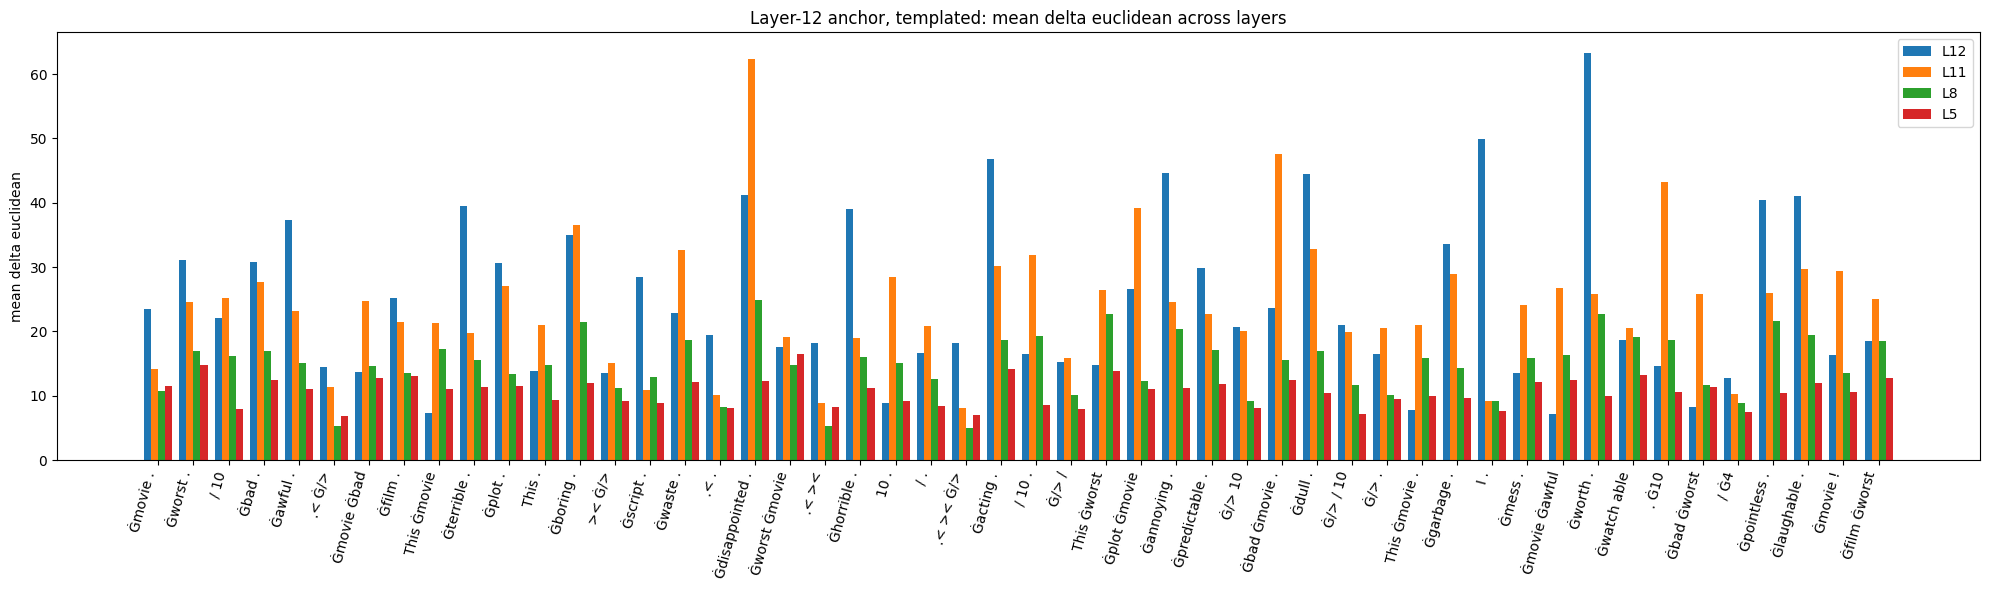

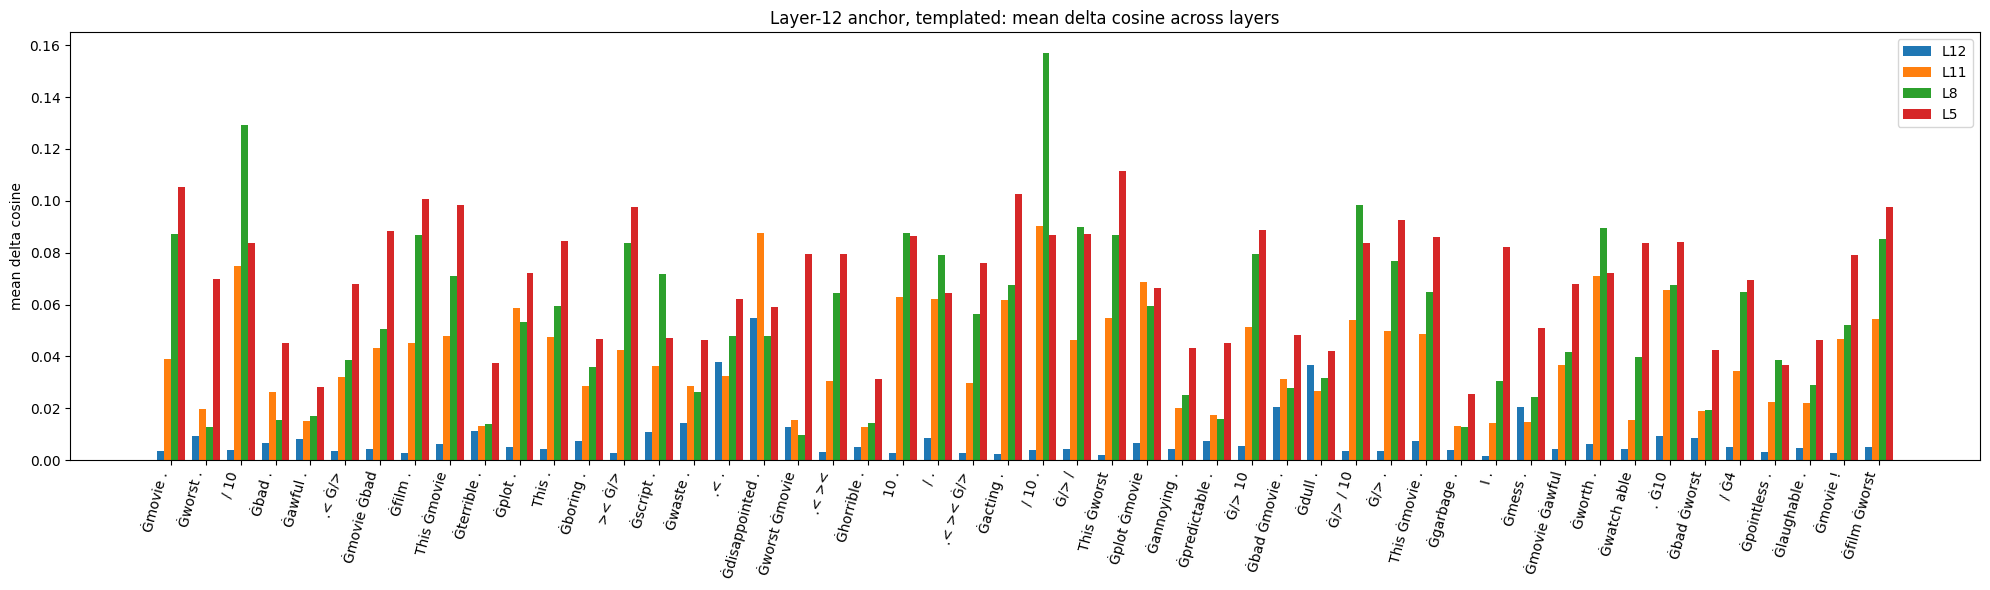

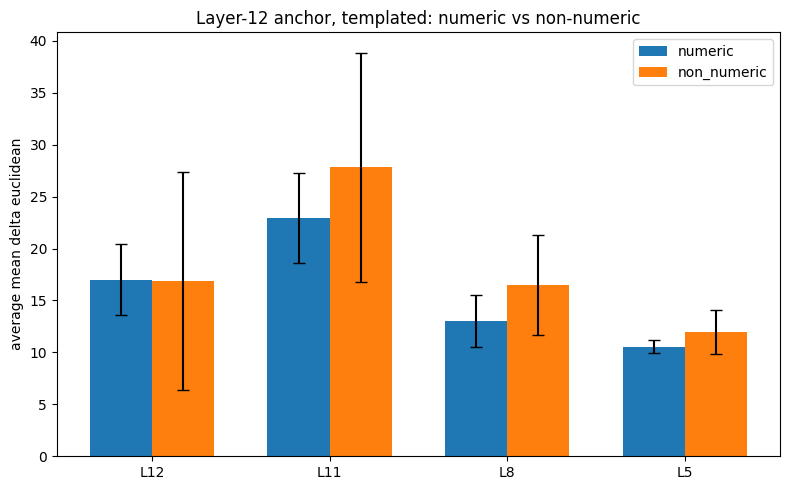

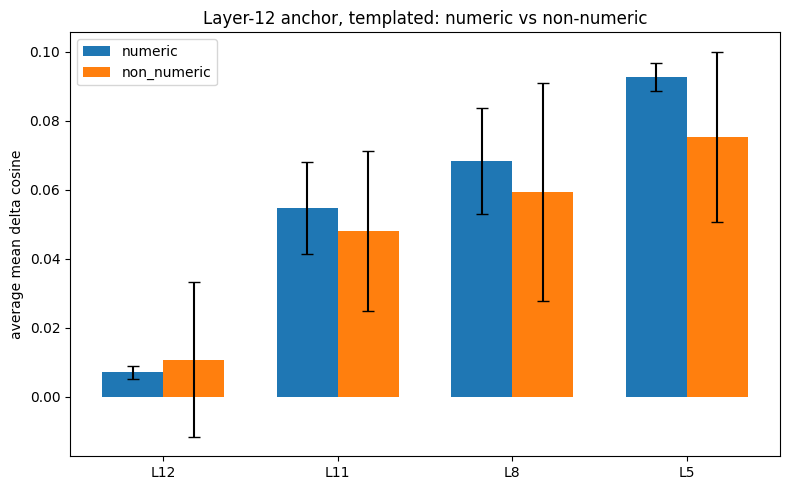

In [99]:
df_tpl_l12 = run_anchor_analysis(df_mean, token_df, anchor_layer=12, context="tpl")
plot_anchor_overlay(df_tpl_l12, anchor_layer=12, context="tpl")
plot_numeric_vs_non_numeric(df_tpl_l12, anchor_layer=12, context="tpl")


### Anchor layer 11


Isolated


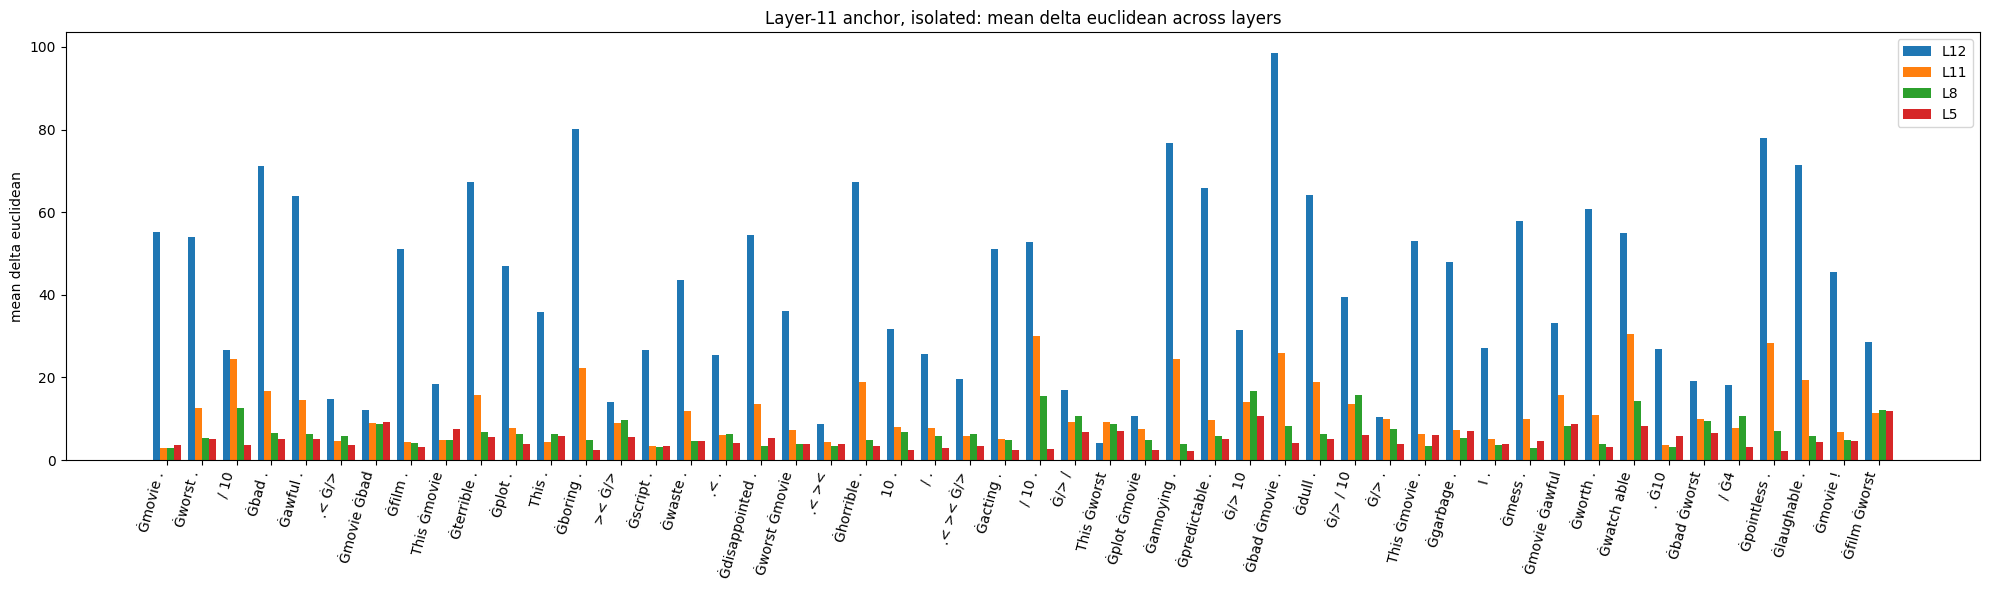

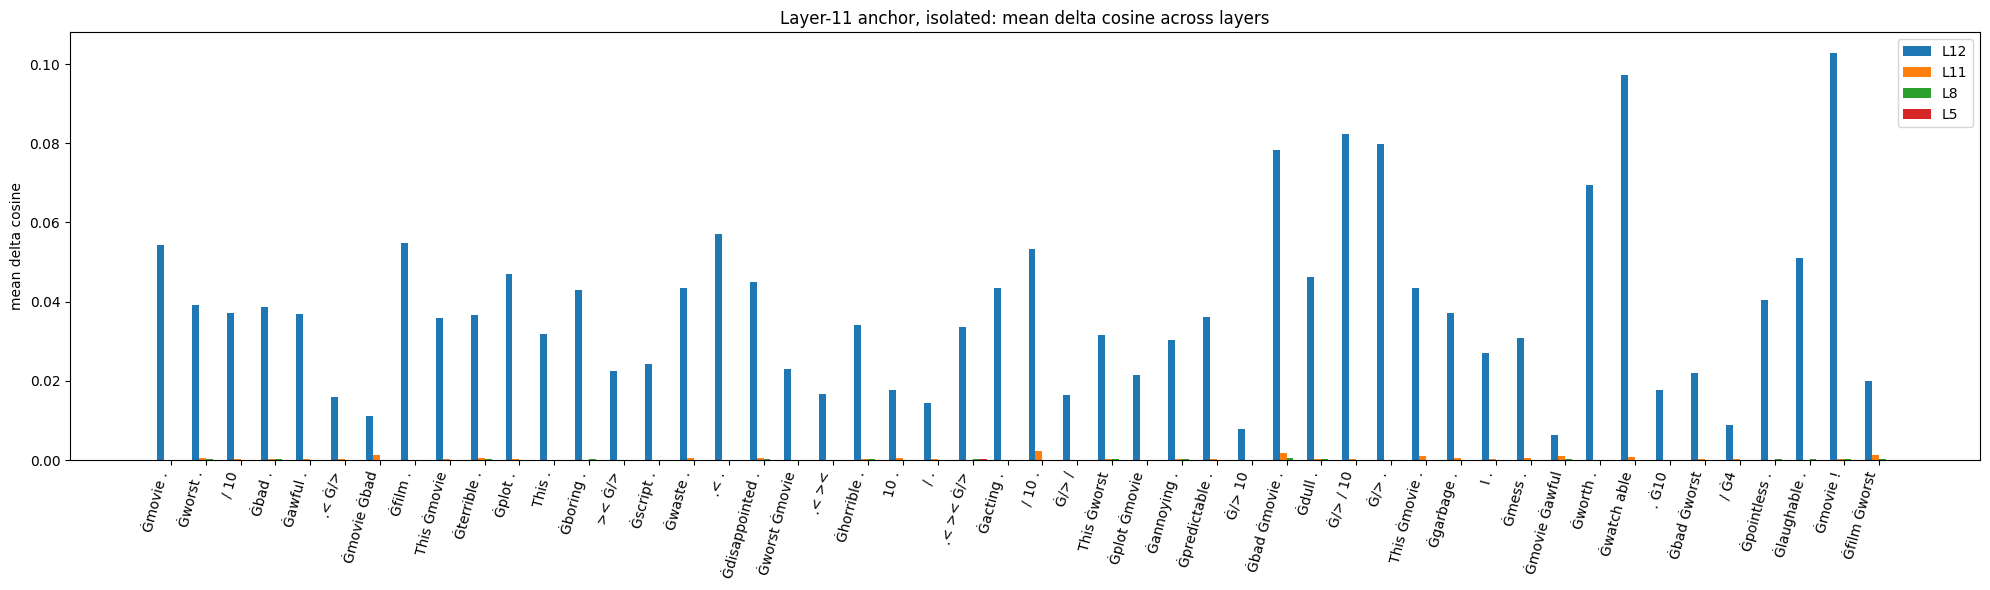

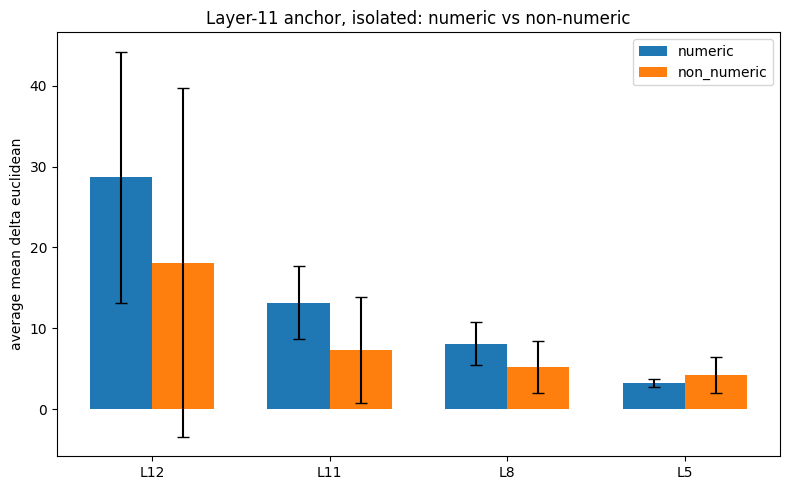

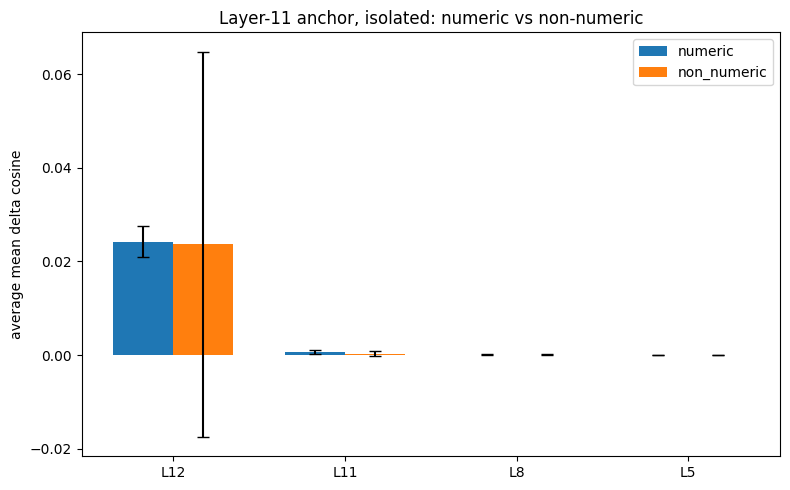

In [100]:
df_iso_l11 = run_anchor_analysis(df_mean, token_df, anchor_layer=11, context="iso")
plot_anchor_overlay(df_iso_l11, anchor_layer=11, context="iso")
plot_numeric_vs_non_numeric(df_iso_l11, anchor_layer=11, context="iso")


Templated


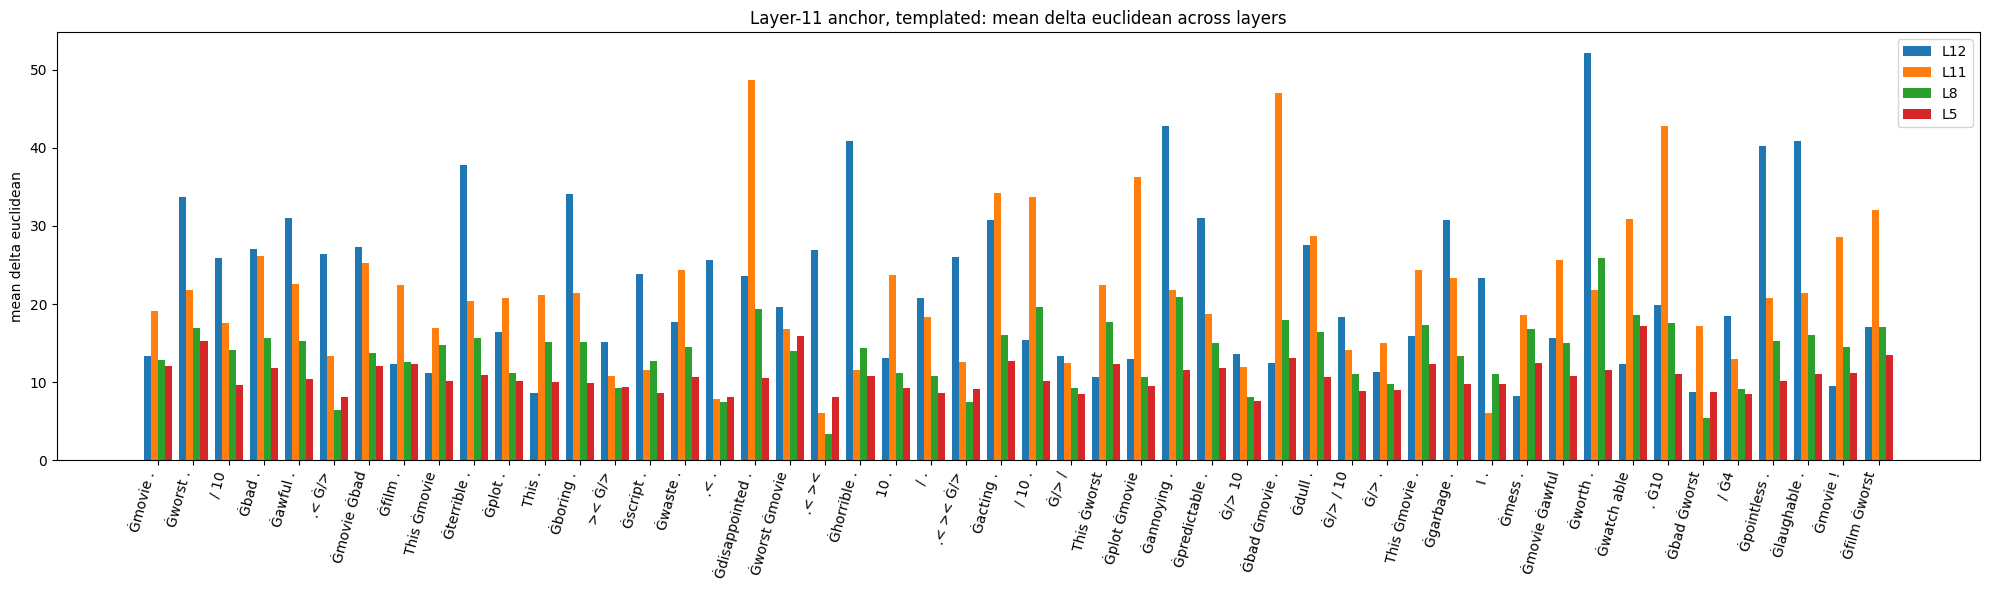

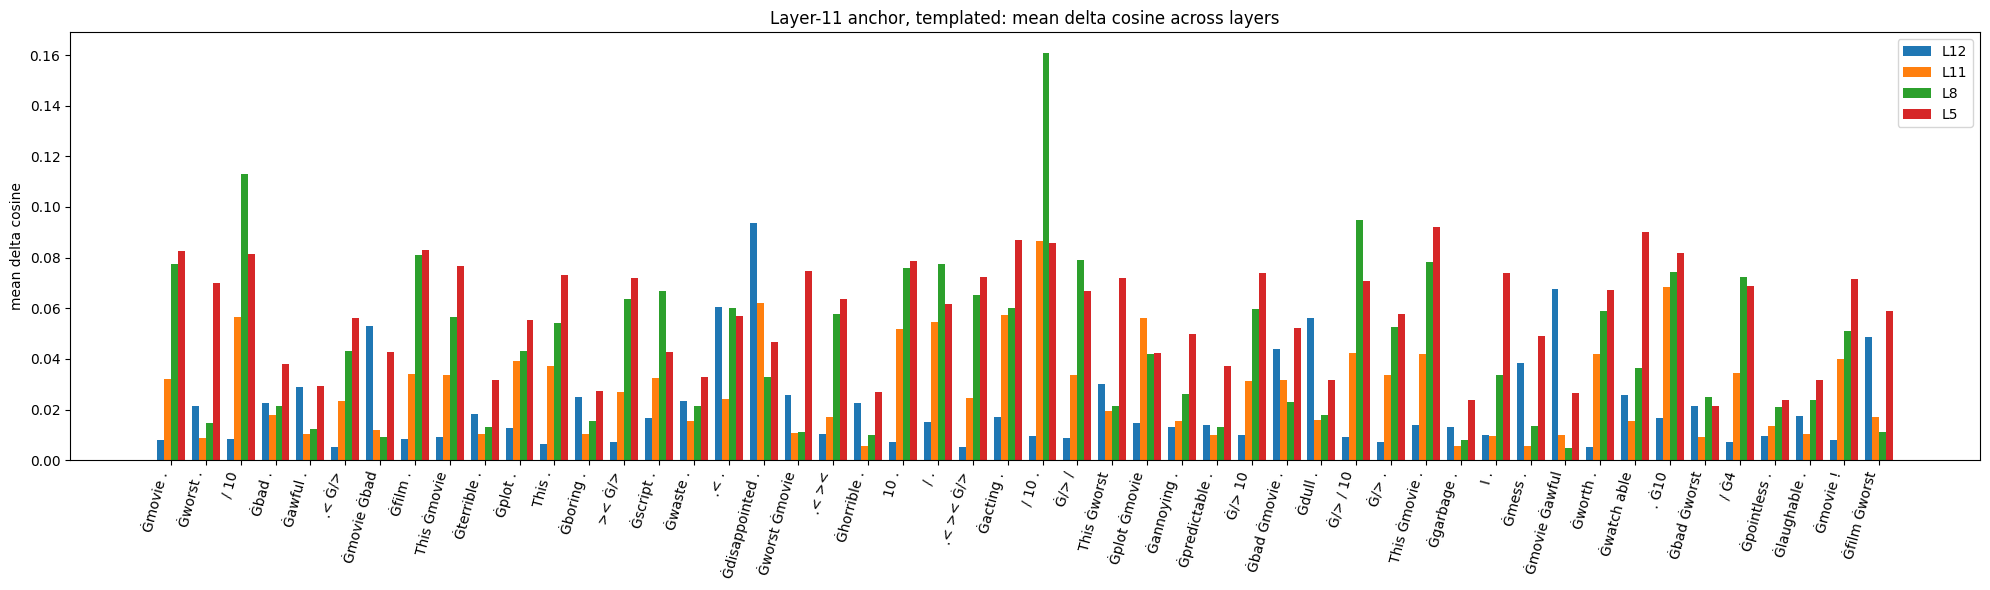

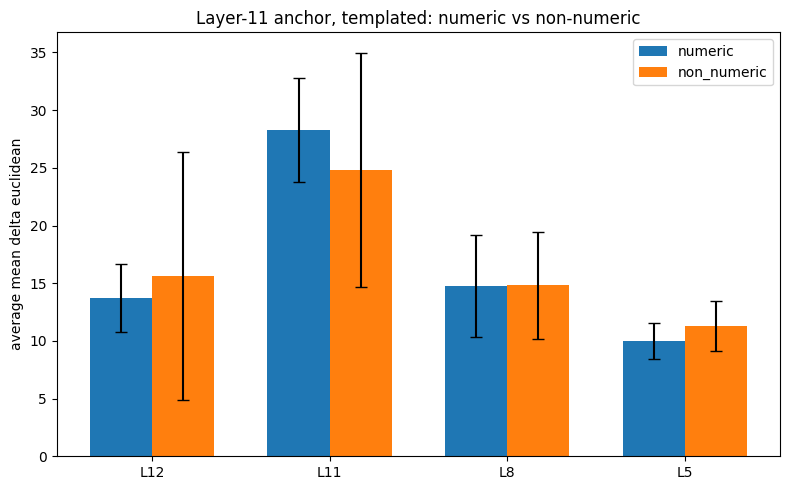

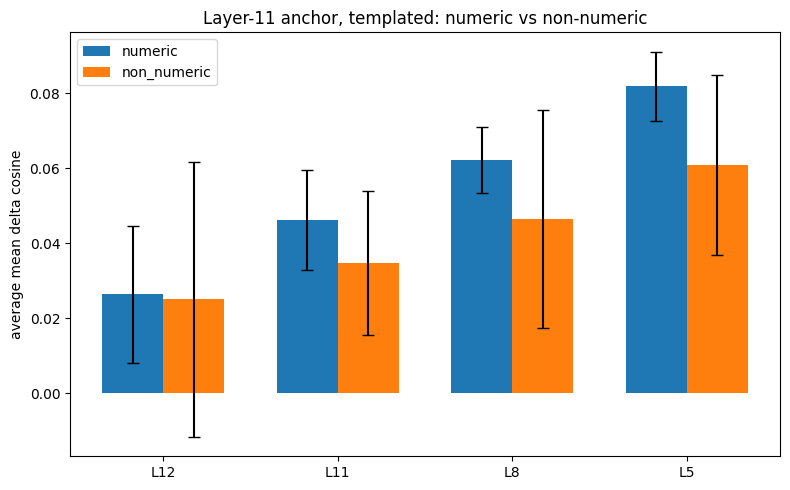

In [101]:
df_tpl_l11 = run_anchor_analysis(df_mean, token_df, anchor_layer=11, context="tpl")
plot_anchor_overlay(df_tpl_l11, anchor_layer=11, context="tpl")
plot_numeric_vs_non_numeric(df_tpl_l11, anchor_layer=11, context="tpl")


### Anchor Layer 8


Isolated


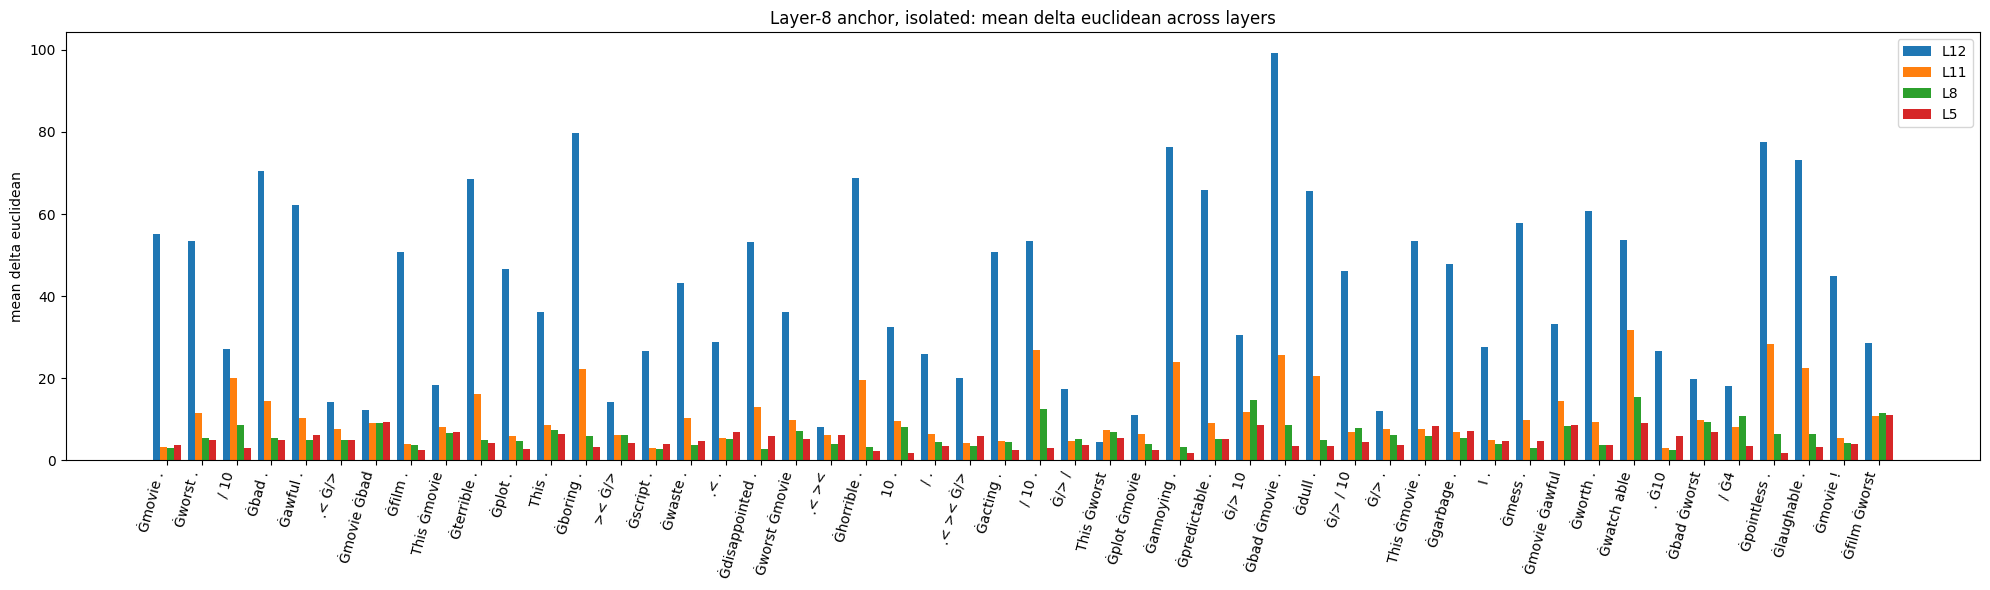

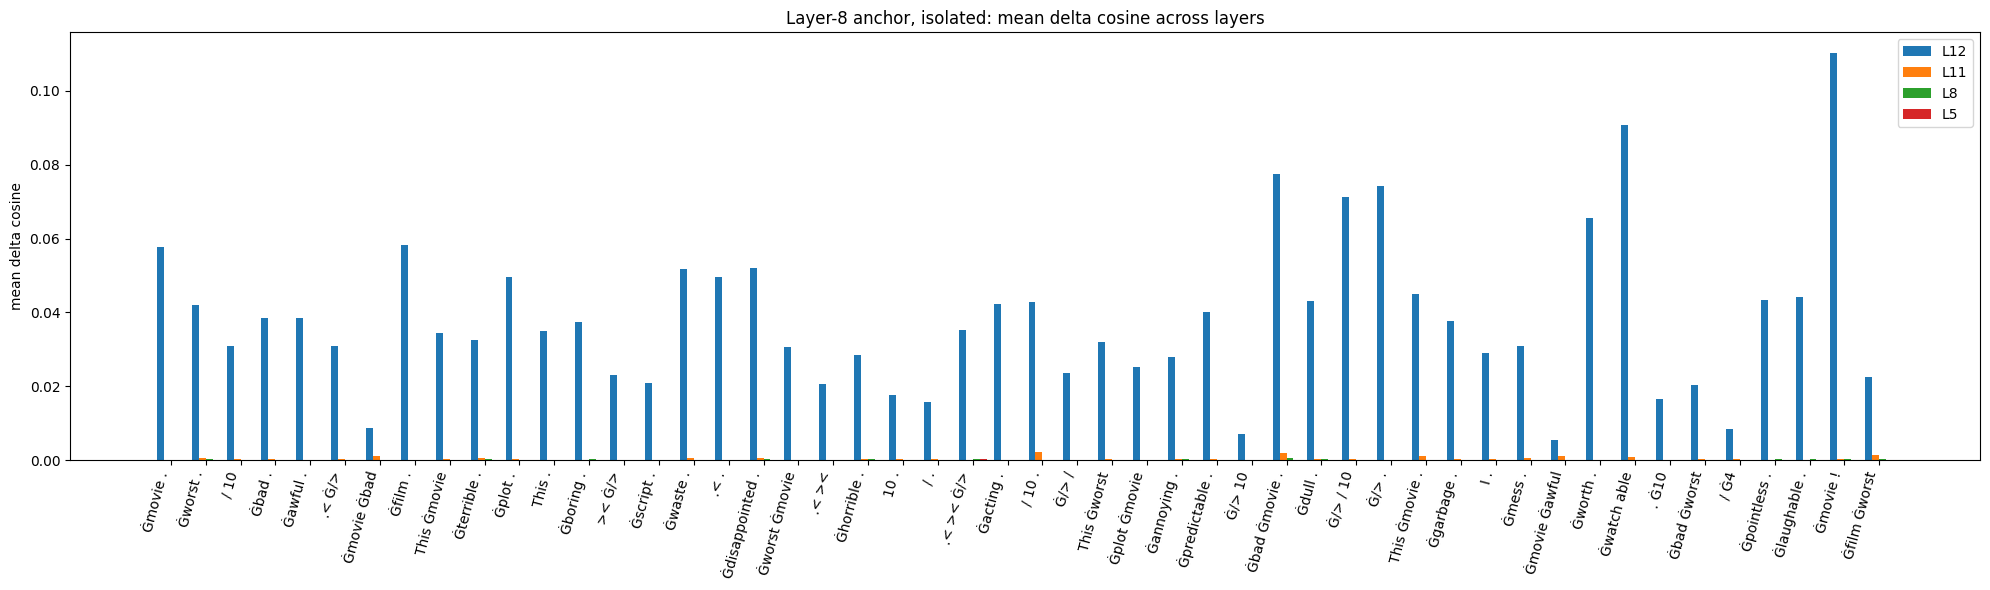

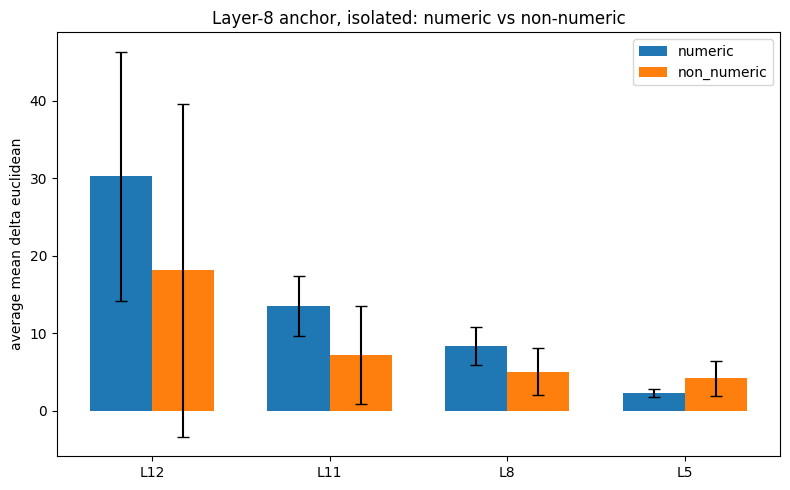

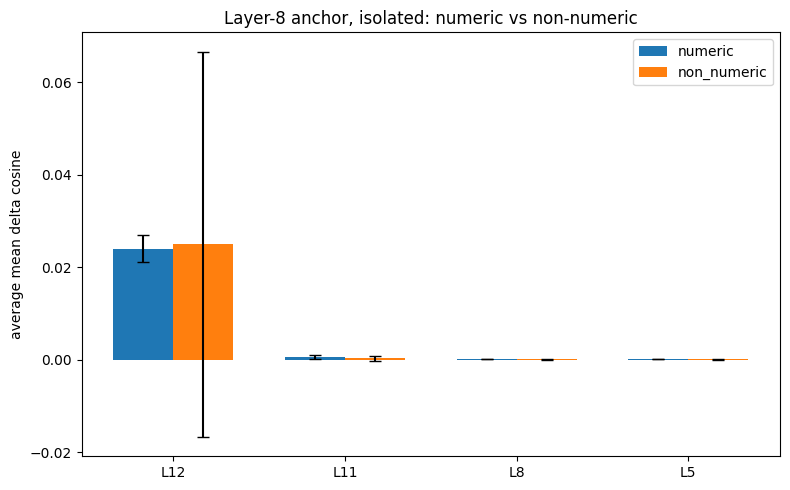

In [102]:
df_iso_l8 = run_anchor_analysis(df_mean, token_df, anchor_layer=8, context="iso")
plot_anchor_overlay(df_iso_l8, anchor_layer=8, context="iso")
plot_numeric_vs_non_numeric(df_iso_l8, anchor_layer=8, context="iso")


Templated


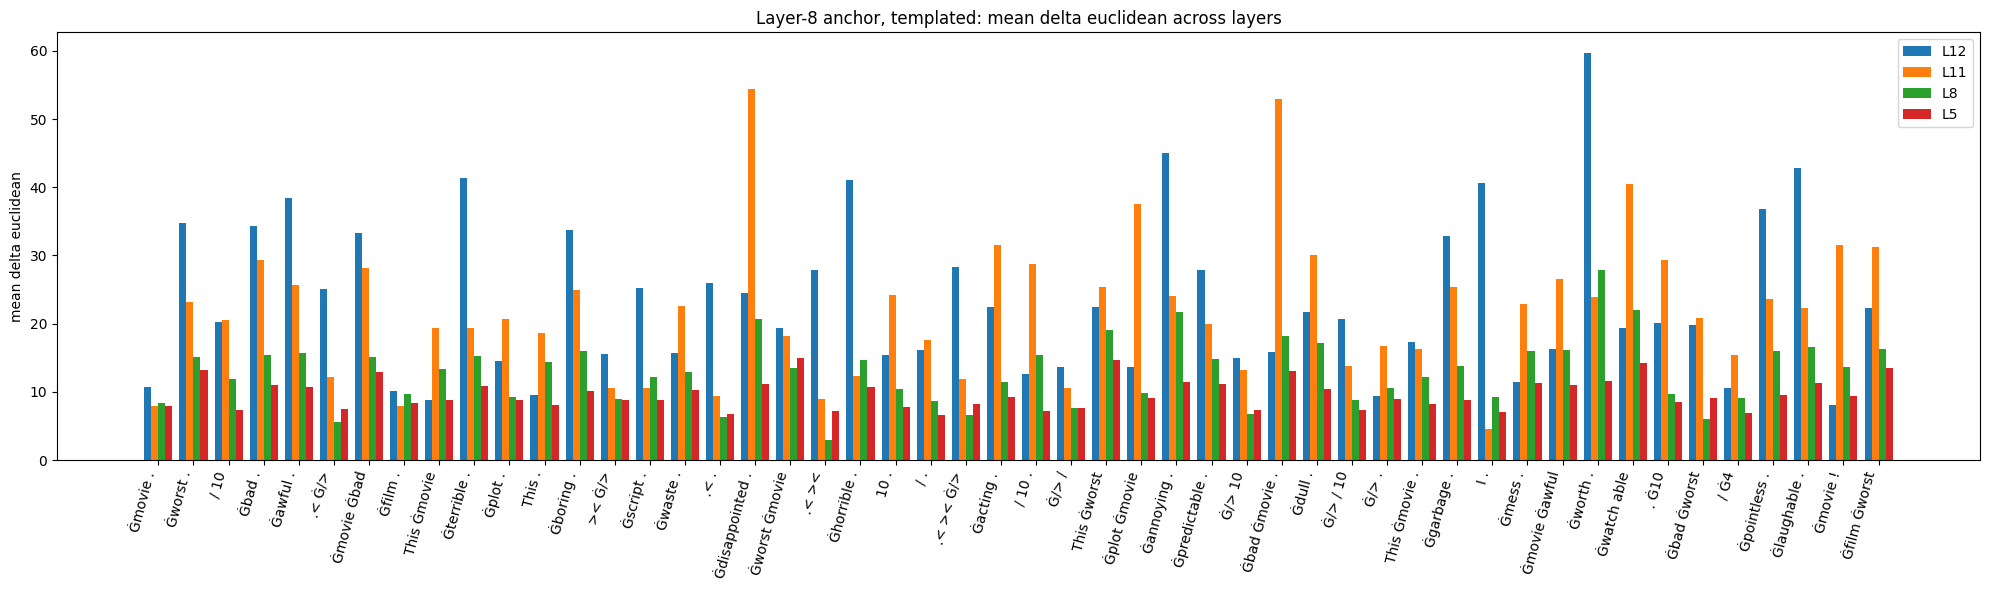

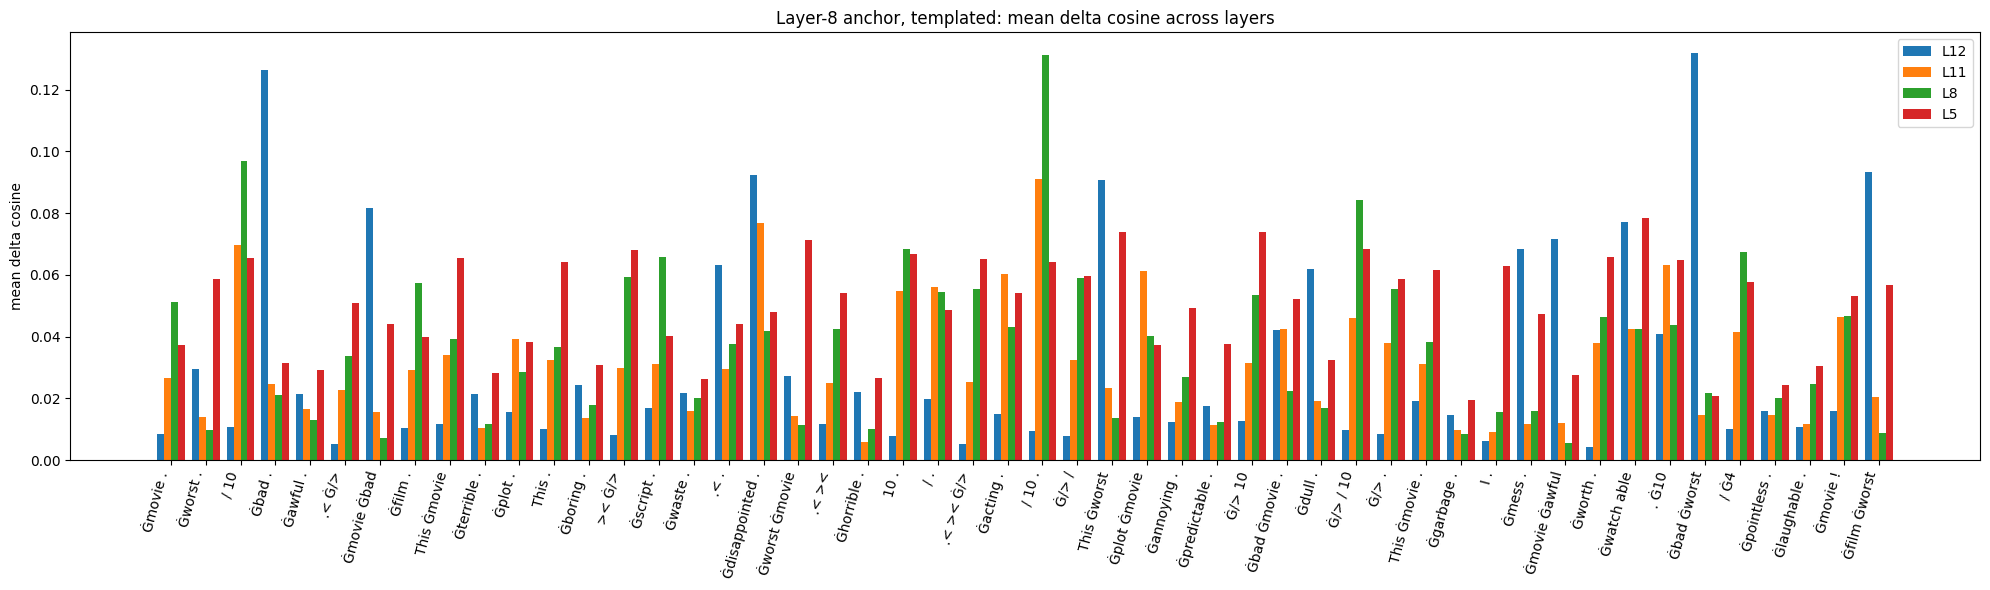

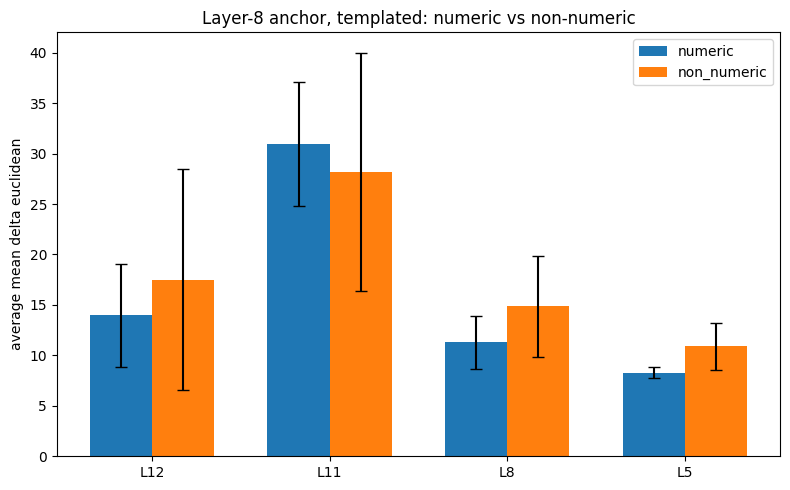

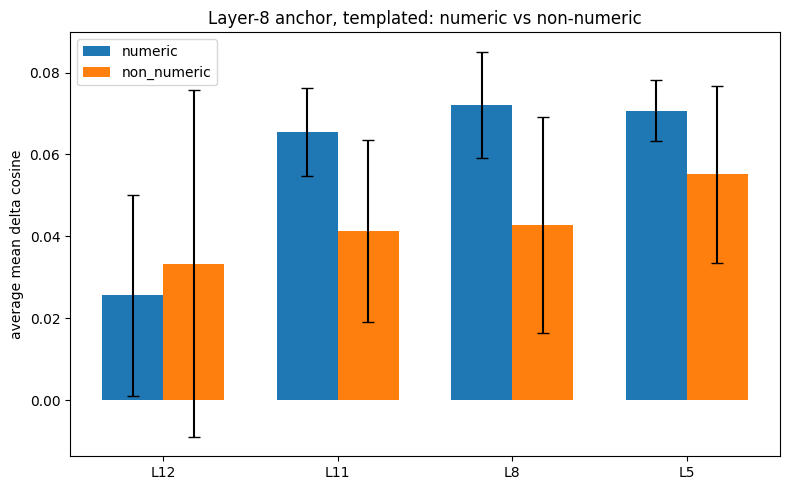

In [103]:
df_tpl_l8 = run_anchor_analysis(df_mean, token_df, anchor_layer=8, context="tpl")
plot_anchor_overlay(df_tpl_l8, anchor_layer=8, context="tpl")
plot_numeric_vs_non_numeric(df_tpl_l8, anchor_layer=8, context="tpl")


### Anchor Layer 5


Isolate


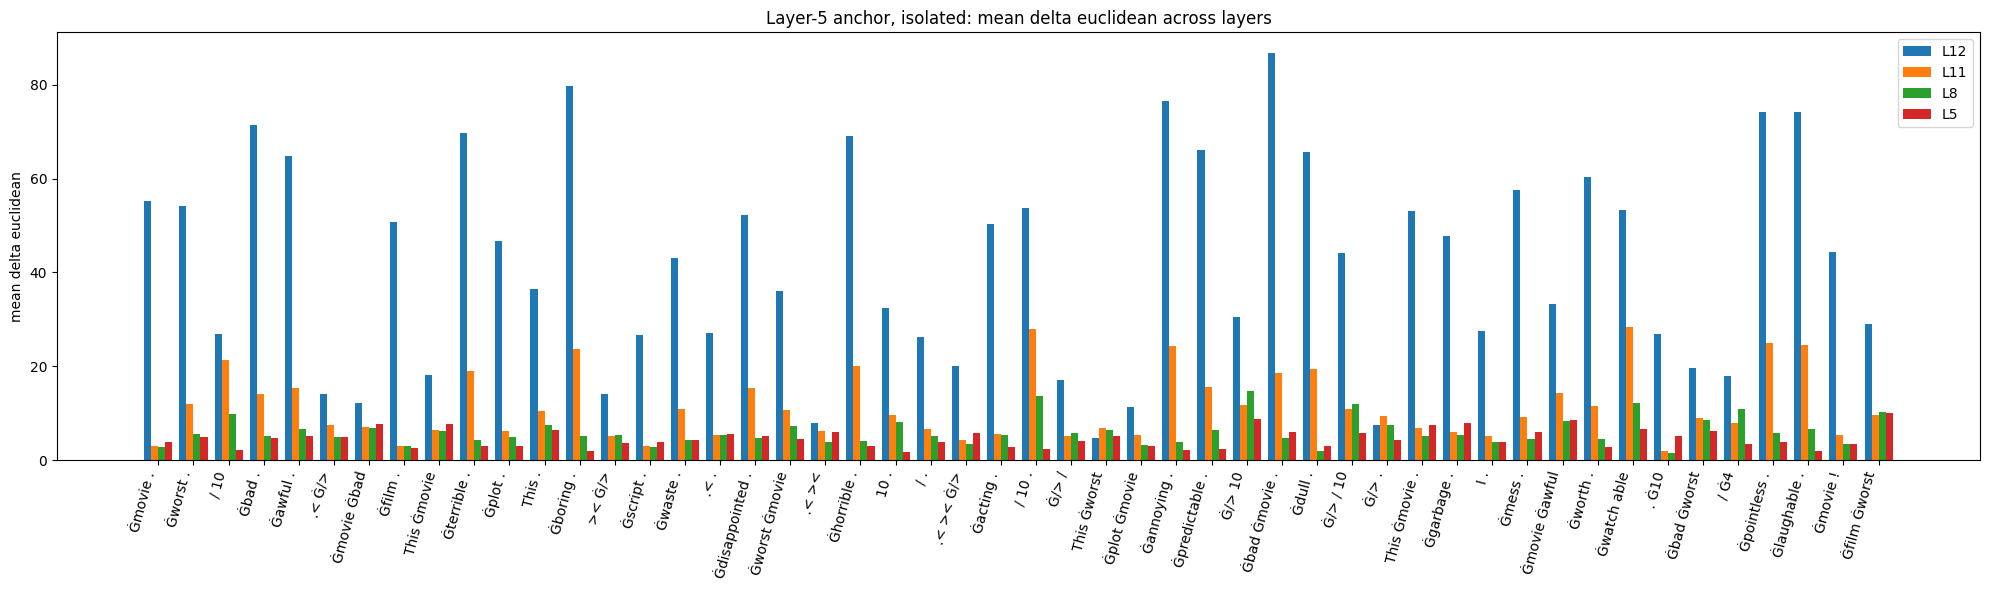

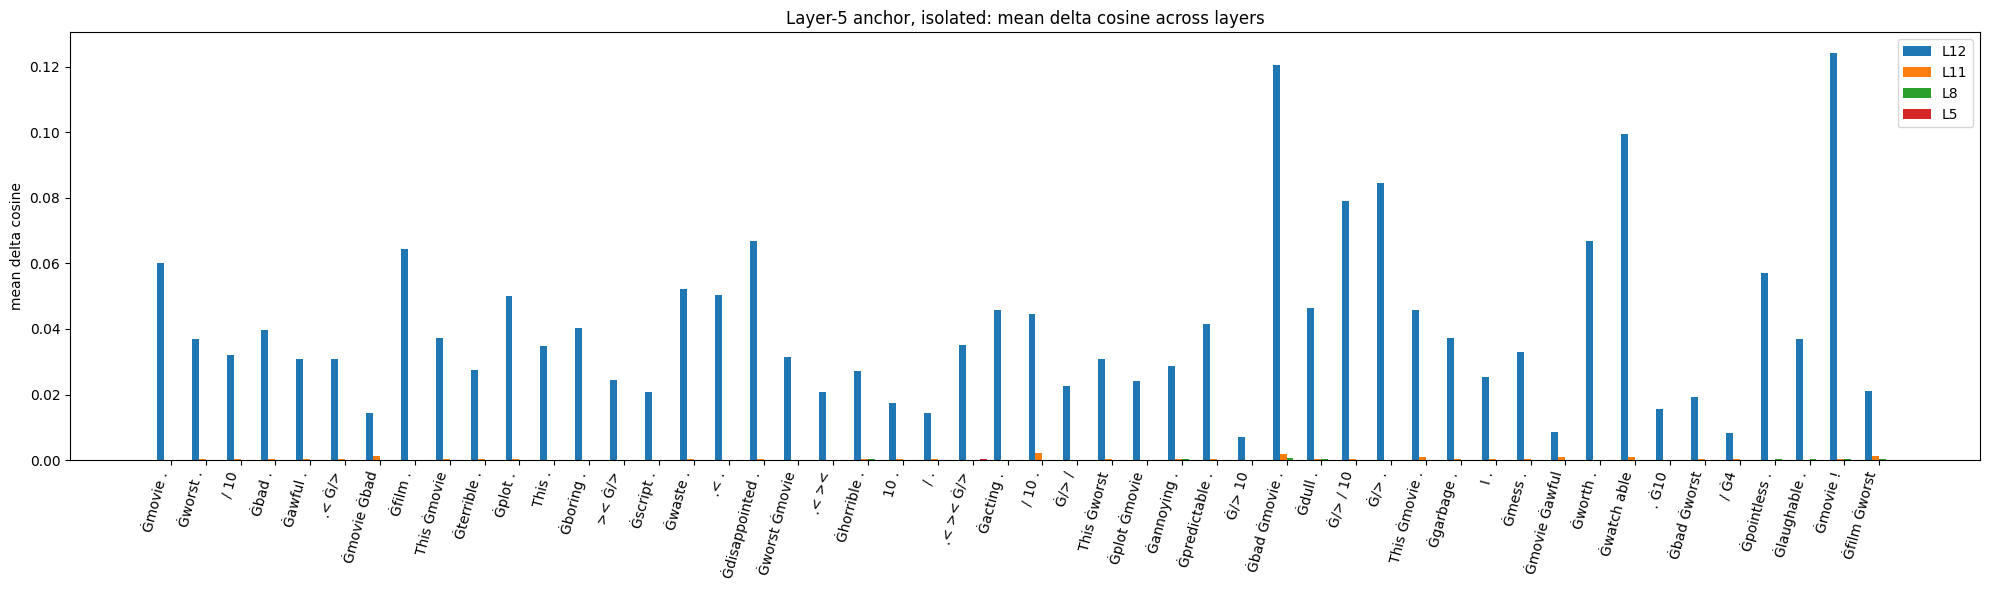

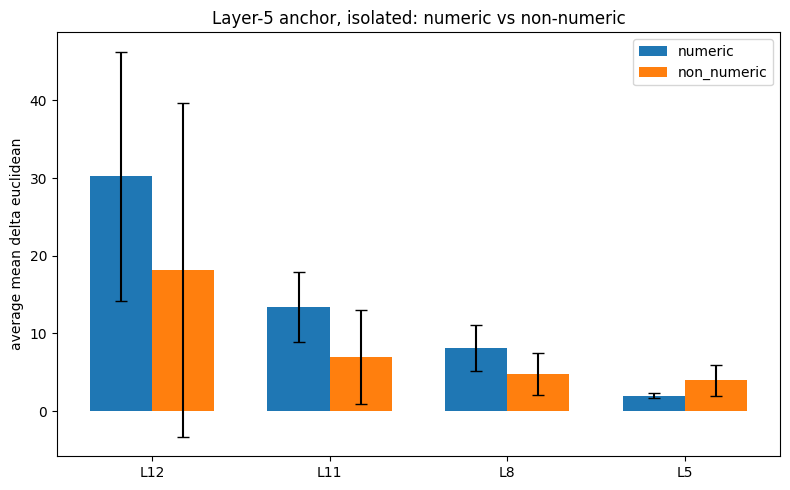

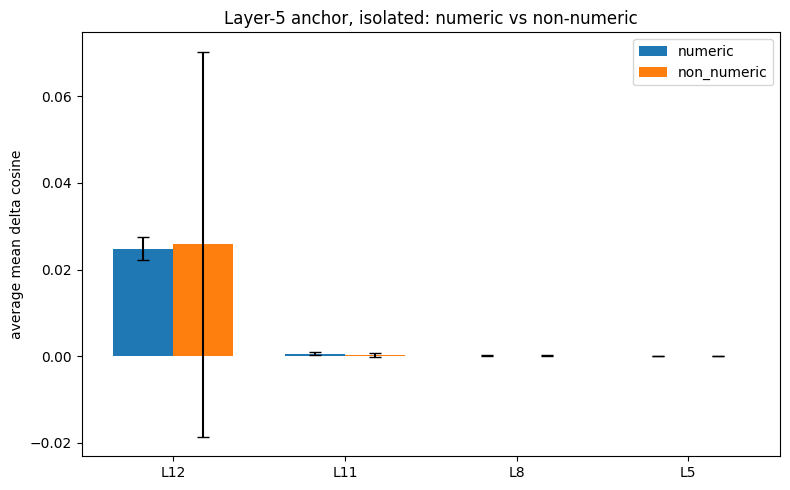

In [104]:
df_iso_l5 = run_anchor_analysis(df_mean, token_df, anchor_layer=5, context="iso")
plot_anchor_overlay(df_iso_l5, anchor_layer=5, context="iso")
plot_numeric_vs_non_numeric(df_iso_l5, anchor_layer=5, context="iso")


Templated


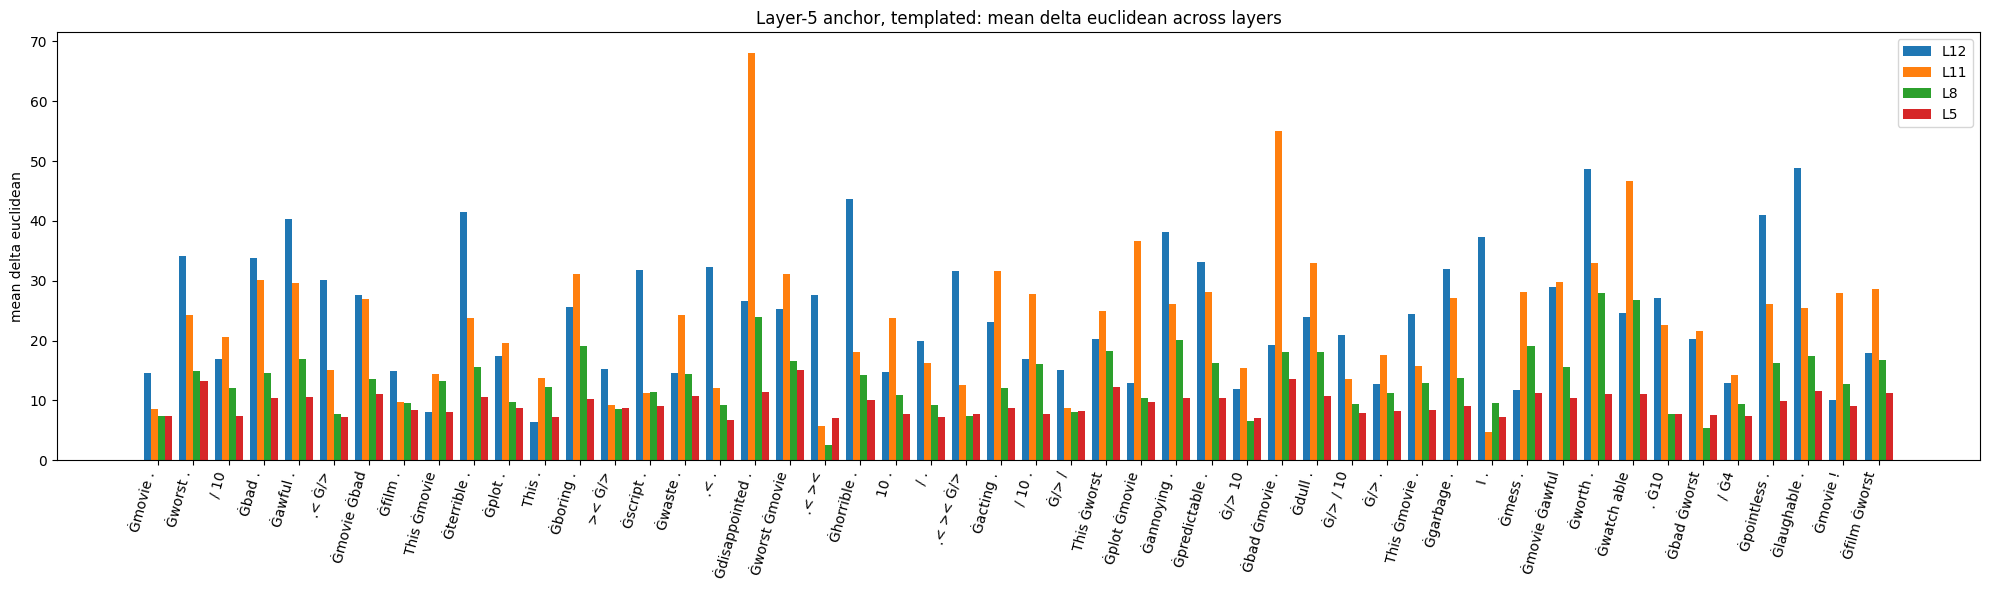

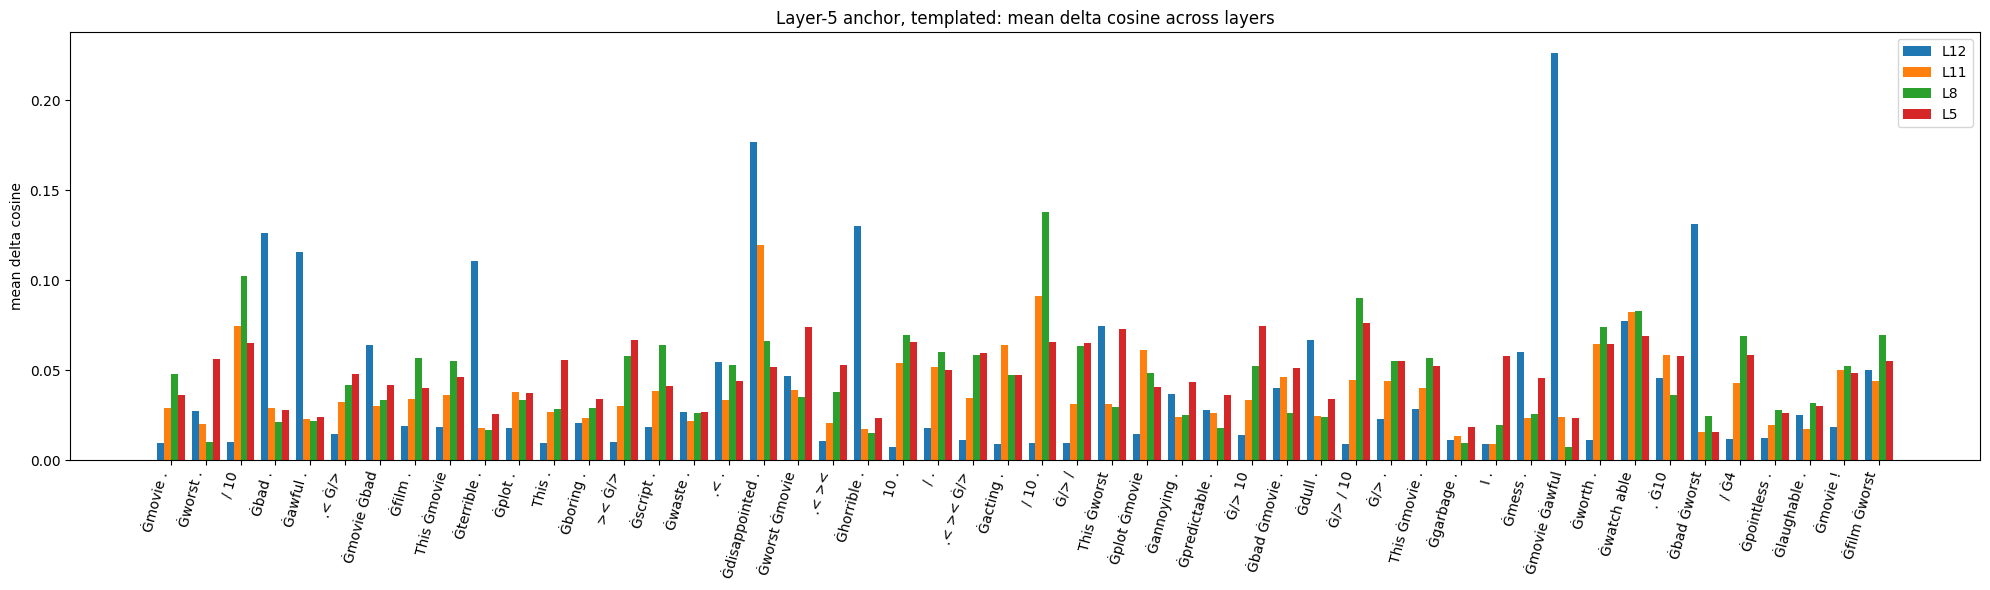

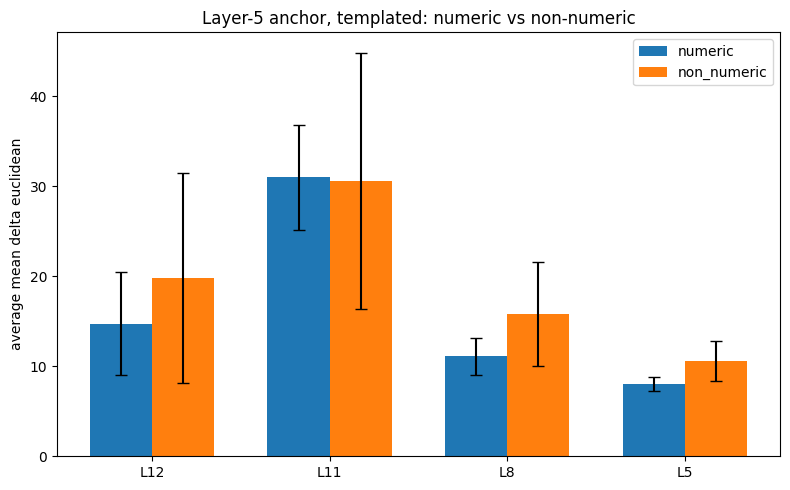

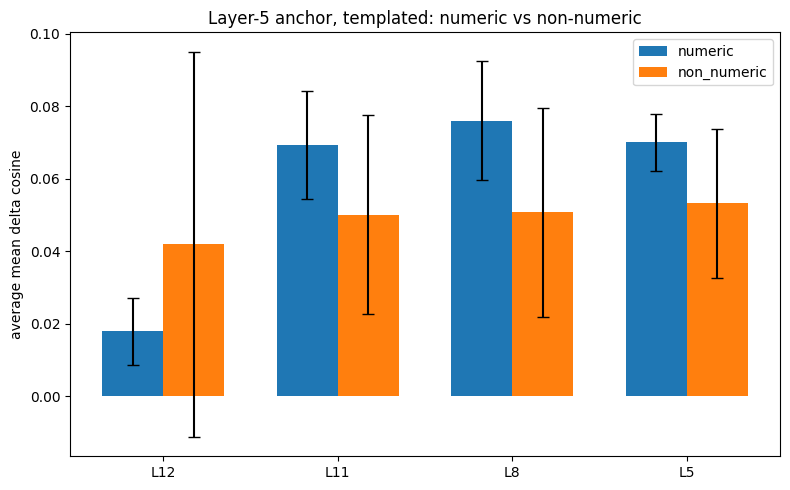

In [105]:
df_tpl_l5 = run_anchor_analysis(df_mean, token_df, anchor_layer=5, context="tpl")
plot_anchor_overlay(df_tpl_l5, anchor_layer=5, context="tpl")
plot_numeric_vs_non_numeric(df_tpl_l5, anchor_layer=5, context="tpl")


In [106]:
import numpy as np
import matplotlib.pyplot as plt

def plot_anchor_same_layer_with_std(
    df,
    anchor_layer,
    context="iso",   # "iso" or "tpl"
    top_n=50,
    min_length=2,
    sort_col="support",
):
    assert context in {"iso", "tpl"}

    if context == "iso":
        euc_mean_col = f"mean_delta_l{anchor_layer}_euclidean_l{anchor_layer}"
        euc_raw_col  = f"delta_l{anchor_layer}_euclidean_l{anchor_layer}"
        cos_mean_col = f"mean_delta_l{anchor_layer}_cosine_l{anchor_layer}"
        cos_raw_col  = f"delta_l{anchor_layer}_cosine_l{anchor_layer}"
        title_prefix = f"Layer-{anchor_layer} anchor, isolated"
    else:
        euc_mean_col = f"mean_delta_tpl_l{anchor_layer}_euclidean_l{anchor_layer}"
        euc_raw_col  = f"delta_tpl_l{anchor_layer}_euclidean_l{anchor_layer}"
        cos_mean_col = f"mean_delta_tpl_l{anchor_layer}_cosine_l{anchor_layer}"
        cos_raw_col  = f"delta_tpl_l{anchor_layer}_cosine_l{anchor_layer}"
        title_prefix = f"Layer-{anchor_layer} anchor, templated"

    plot_df = (
        df[df["length"] >= min_length]
        .sort_values(sort_col, ascending=False)
        .head(top_n)
        .copy()
    )

    plot_df["label"] = plot_df["ordered_tokens"].apply(
        lambda x: " ".join(x) if isinstance(x, list) else str(x)
    )

    # std over the raw NN delta values for each itemset
    plot_df["std_euclidean"] = plot_df[euc_raw_col].apply(
        lambda xs: float(np.std(xs)) if len(xs) > 0 else 0.0
    )
    plot_df["std_cosine"] = plot_df[cos_raw_col].apply(
        lambda xs: float(np.std(xs)) if len(xs) > 0 else 0.0
    )

    x = np.arange(len(plot_df))

    # Euclidean
    plt.figure(figsize=(20, 6))
    plt.bar(
        x,
        plot_df[euc_mean_col],
        yerr=plot_df["std_euclidean"],
        capsize=4
    )
    plt.xticks(x, plot_df["label"], rotation=75, ha="right")
    plt.ylabel("mean delta euclidean")
    plt.title(f"{title_prefix}: same-layer delta euclidean only")
    plt.tight_layout()
    plt.show()

    # Cosine
    plt.figure(figsize=(20, 6))
    plt.bar(
        x,
        plot_df[cos_mean_col],
        yerr=plot_df["std_cosine"],
        capsize=4
    )
    plt.xticks(x, plot_df["label"], rotation=75, ha="right")
    plt.ylabel("mean delta cosine")
    plt.title(f"{title_prefix}: same-layer delta cosine only")
    plt.tight_layout()
    plt.show()

    return plot_df[
        [
            "label",
            euc_mean_col,
            "std_euclidean",
            cos_mean_col,
            "std_cosine",
        ]
    ]


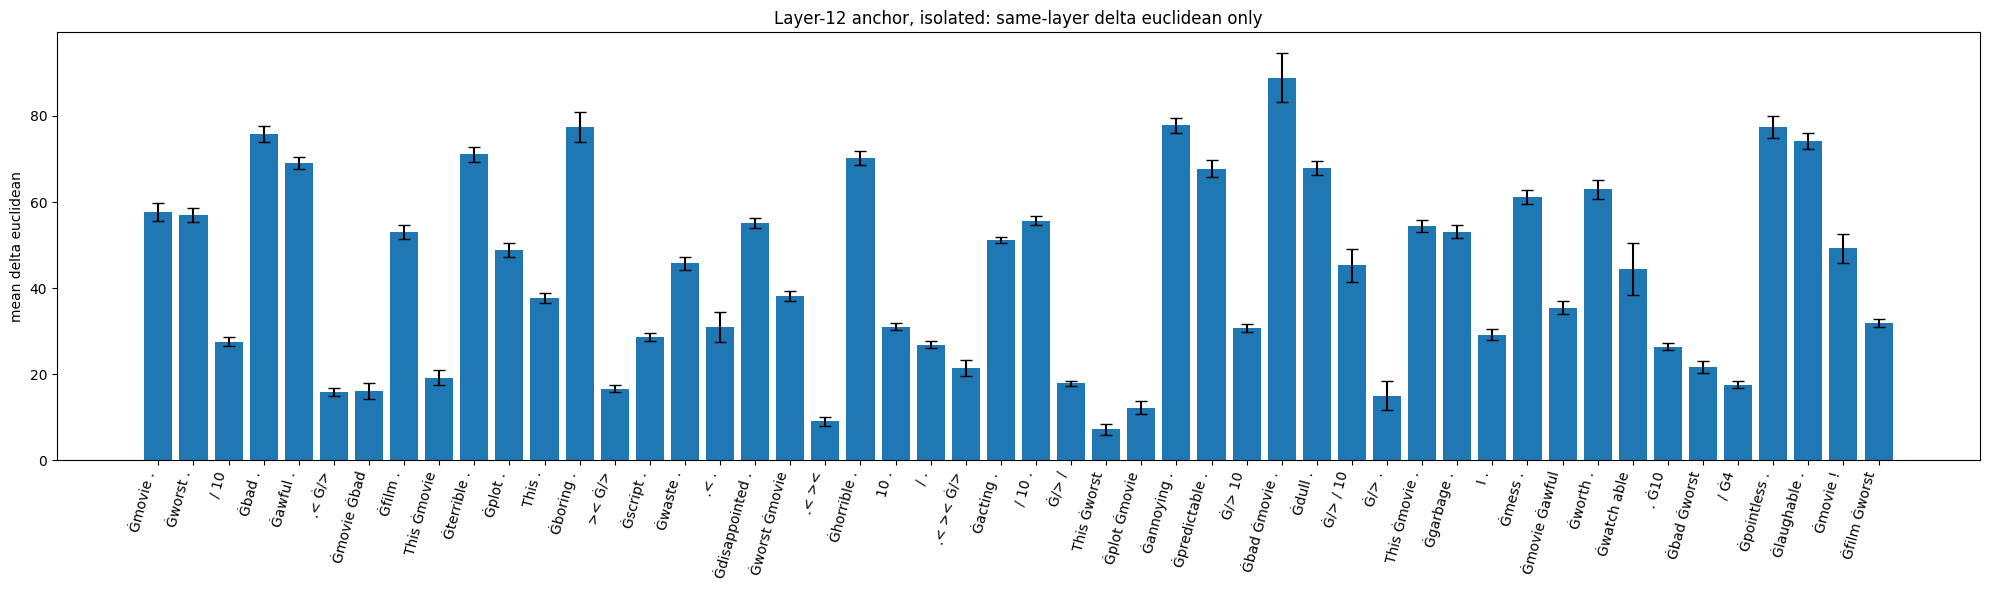

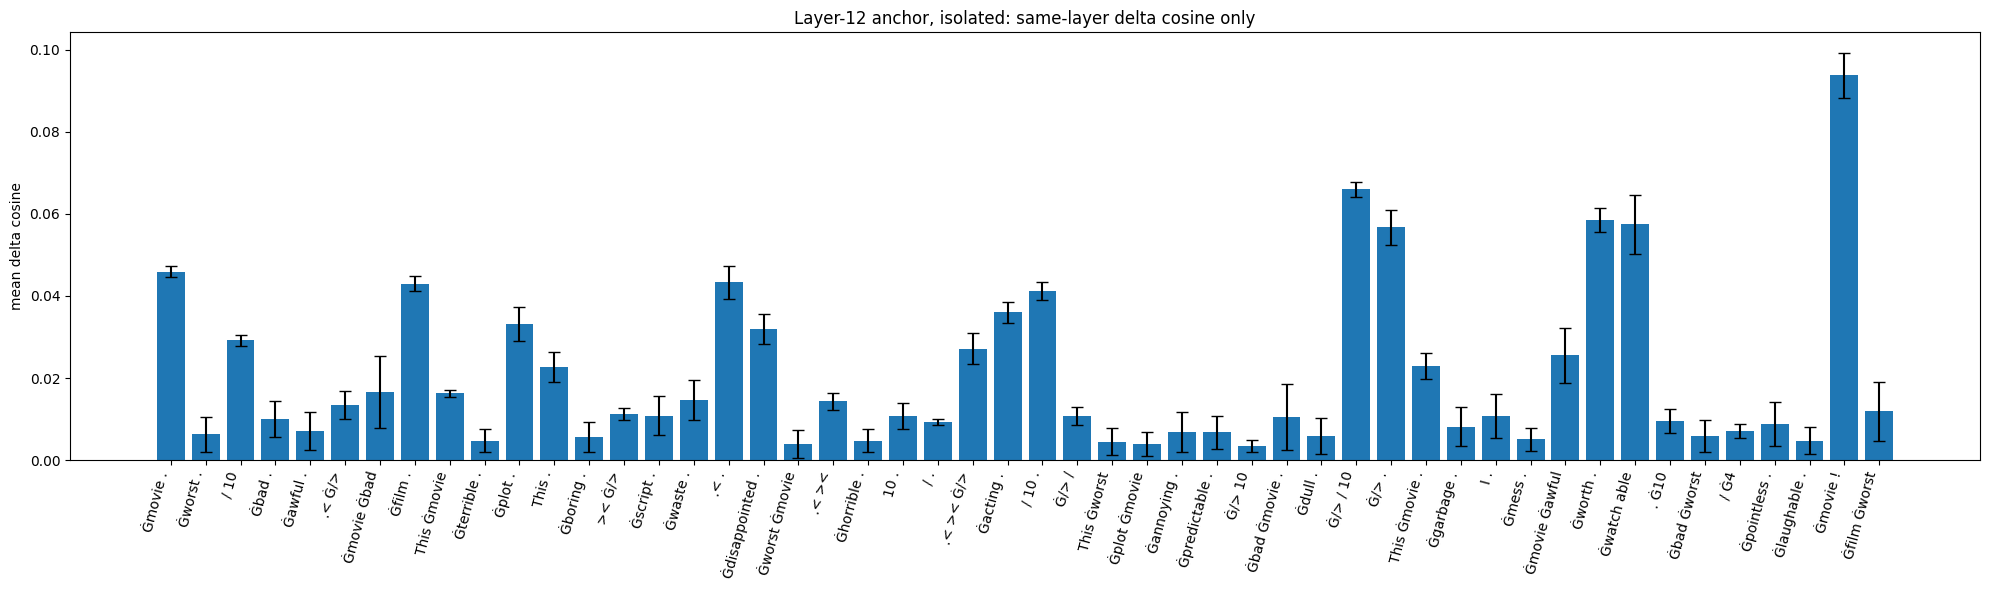

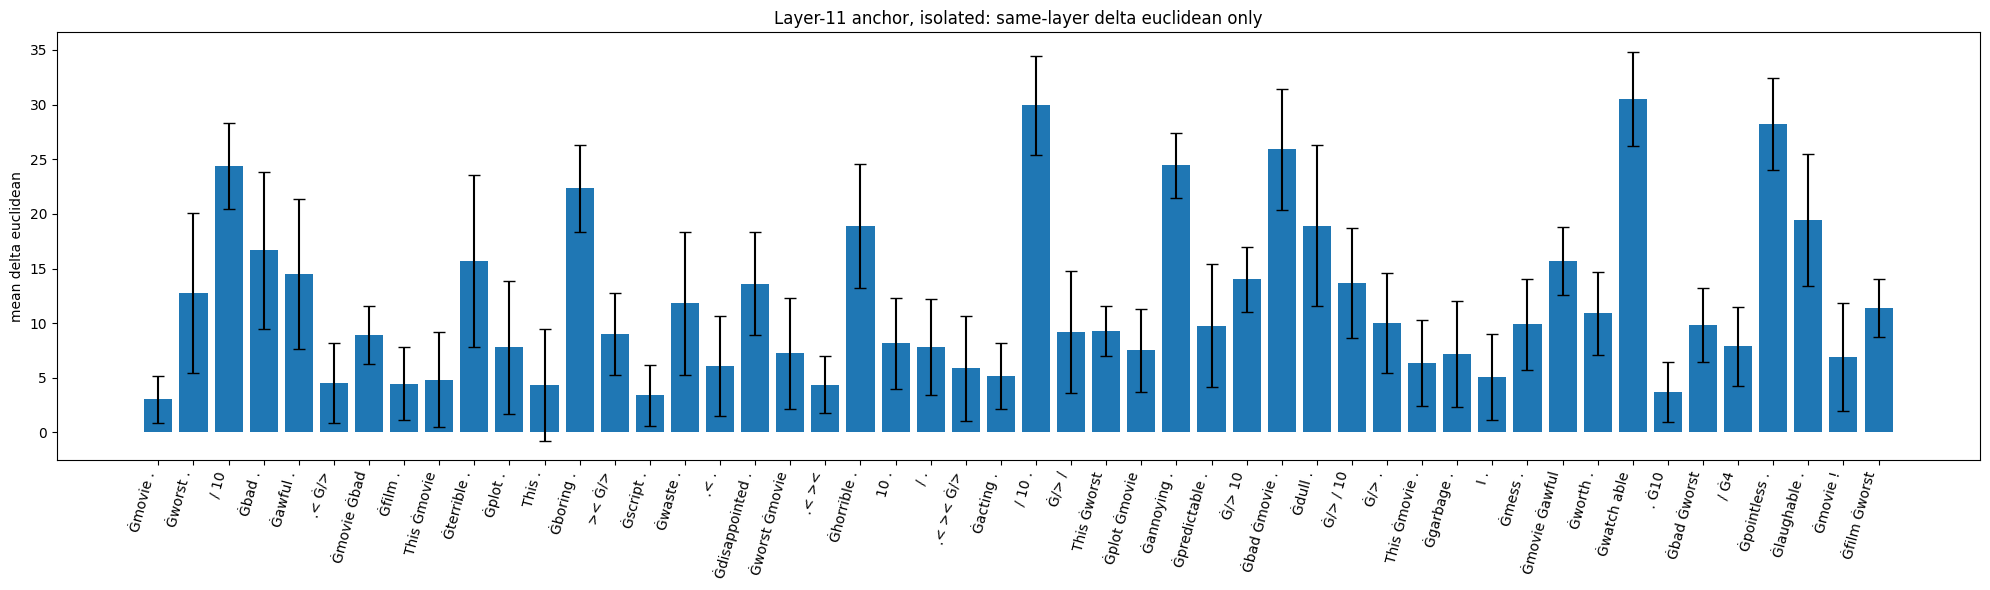

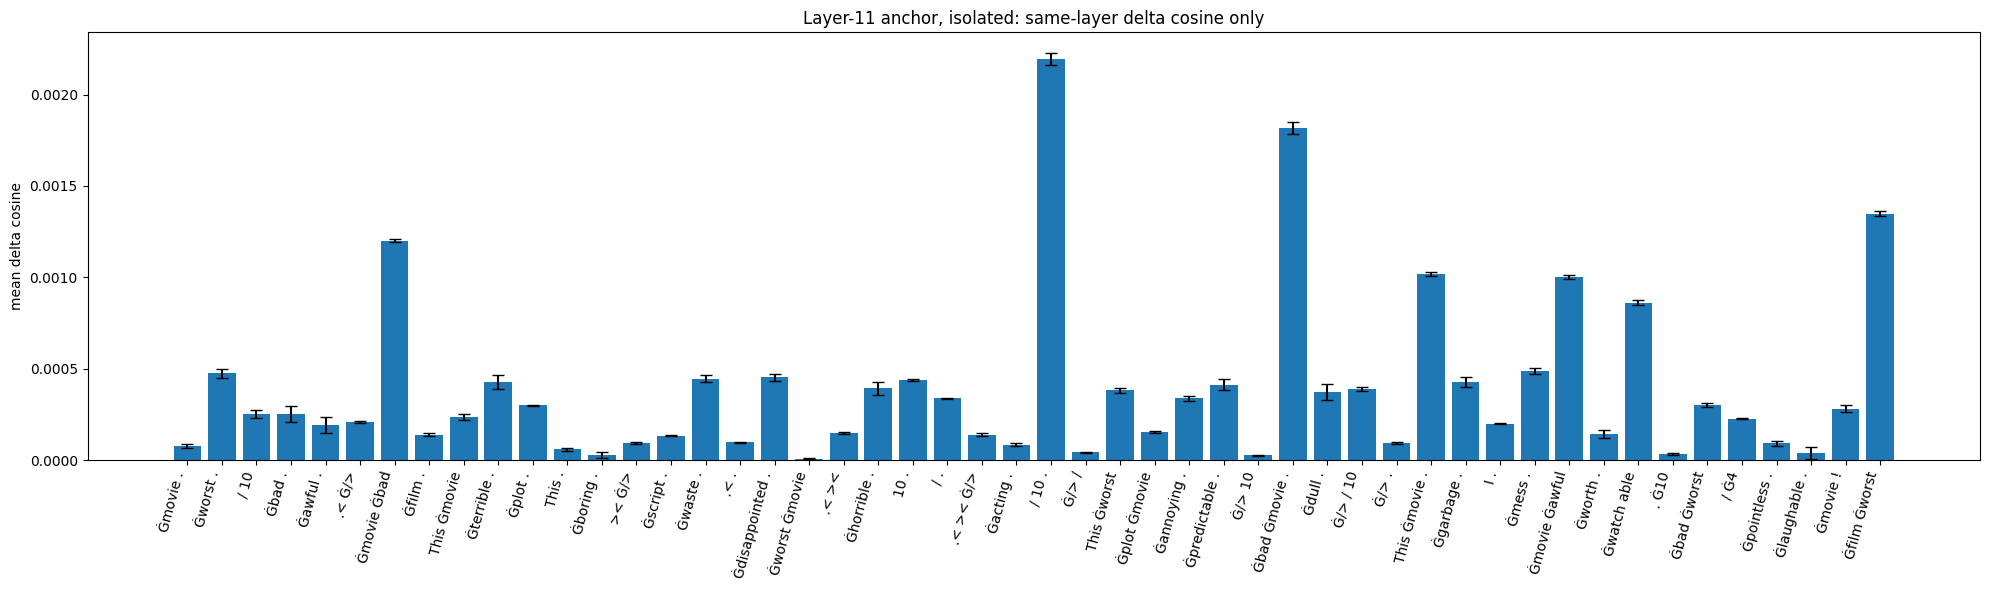

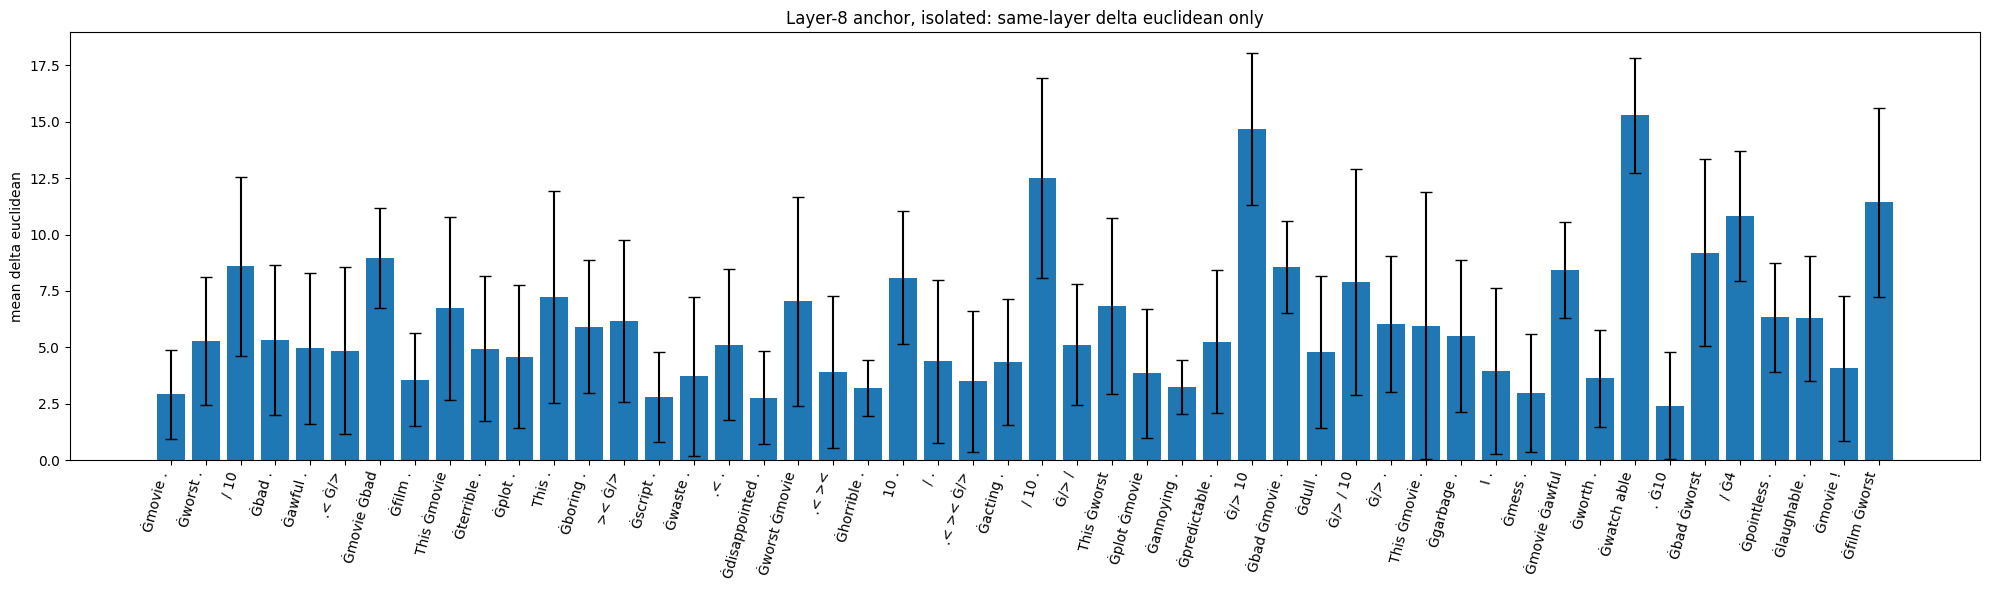

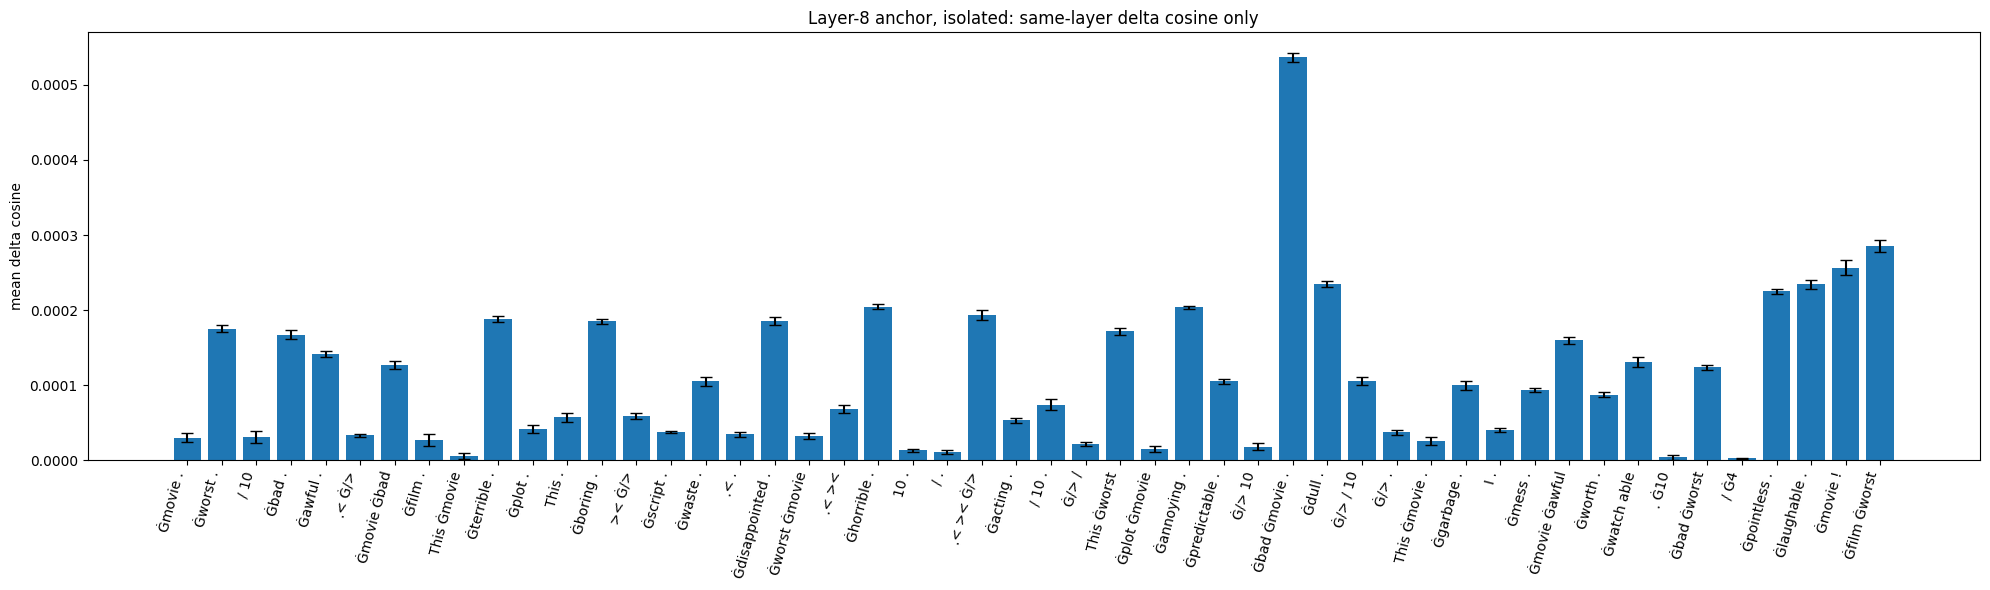

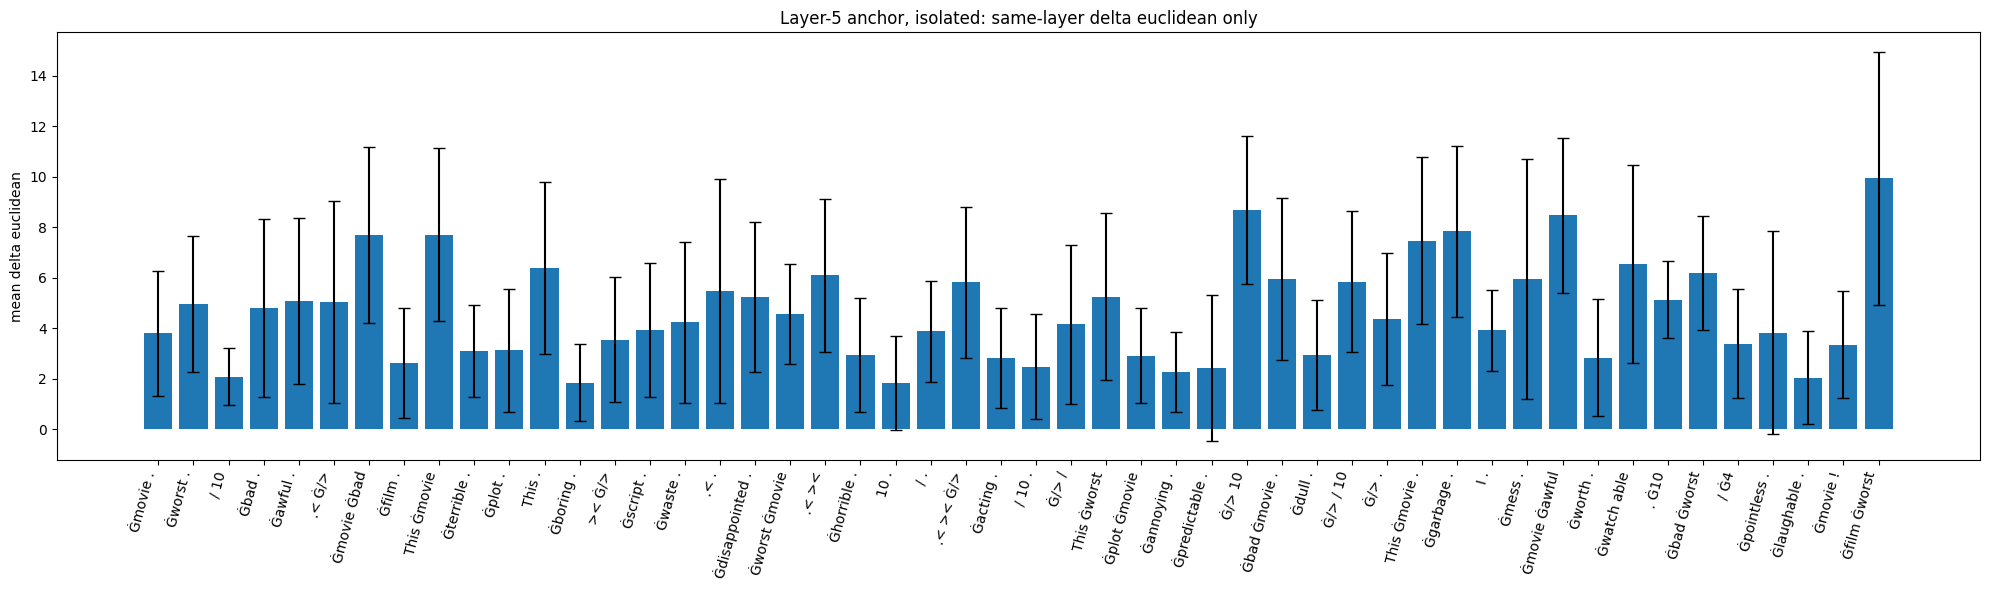

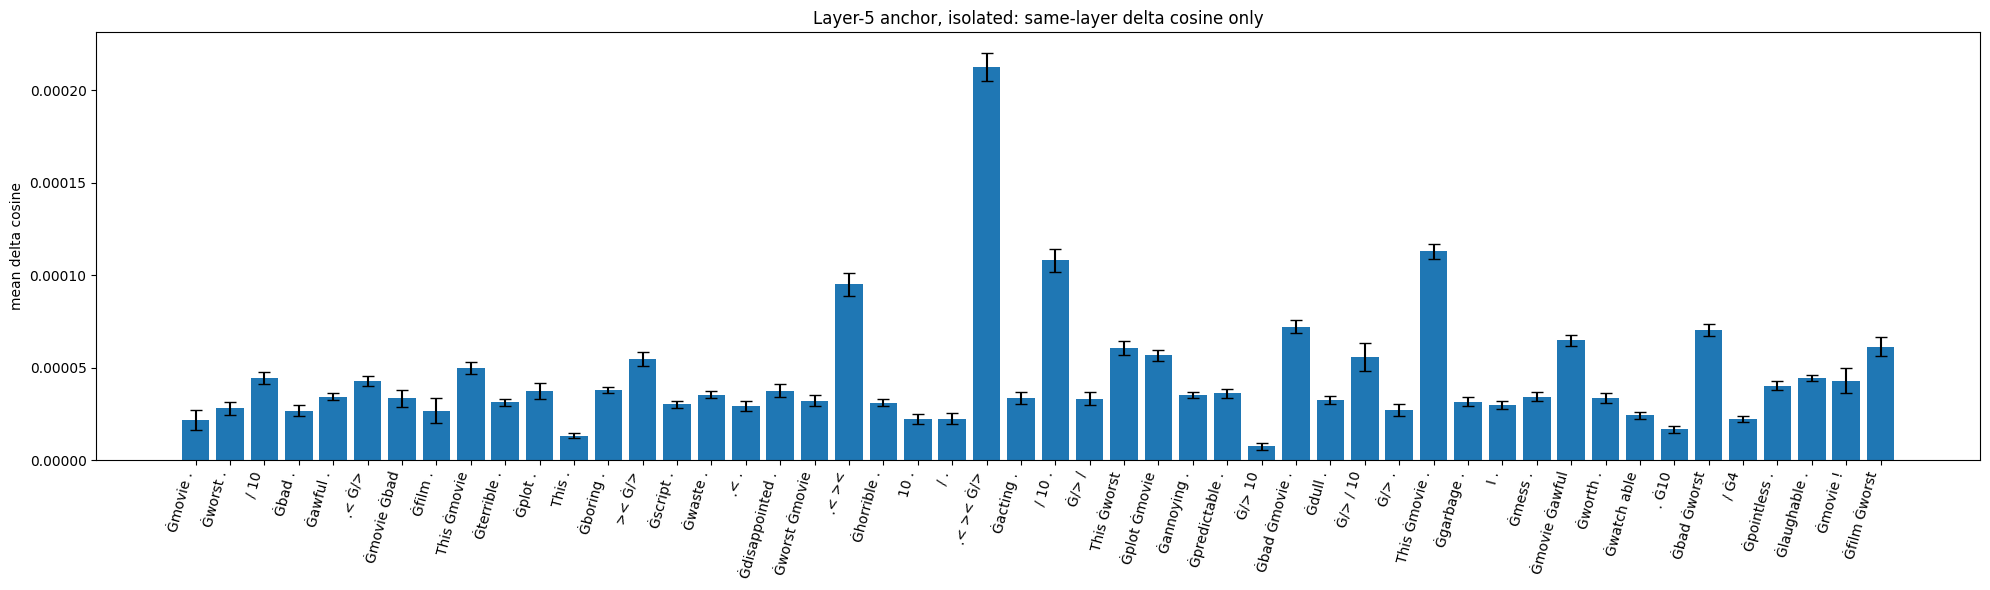

,label,mean_delta_l5_euclidean_l5,std_euclidean,mean_delta_l5_cosine_l5,std_cosine
15,Ġmovie .,3.793774,2.468868,0.000022,0.000005
18,Ġworst .,4.959375,2.686768,0.000028,0.000003
17,/ 10,2.080286,1.146167,0.000044,0.000003
26,Ġbad .,4.795874,3.539738,0.000027,0.000003
27,Ġawful .,5.085388,3.295196,0.000034,0.000002
34,.< Ġ/>,5.021143,3.997039,0.000043,0.000003
42,Ġmovie Ġbad,7.693274,3.484386,0.000033,0.000004
51,Ġfilm .,2.621008,2.175448,0.000027,0.000007
61,This Ġmovie,7.700793,3.427368,0.000050,0.000003
43,Ġterrible .,3.101282,1.815881,0.000031,0.000002


In [107]:
plot_anchor_same_layer_with_std(df_iso_l12, anchor_layer=12, context="iso")
plot_anchor_same_layer_with_std(df_iso_l11, anchor_layer=11, context="iso")
plot_anchor_same_layer_with_std(df_iso_l8,  anchor_layer=8,  context="iso")
plot_anchor_same_layer_with_std(df_iso_l5,  anchor_layer=5,  context="iso")


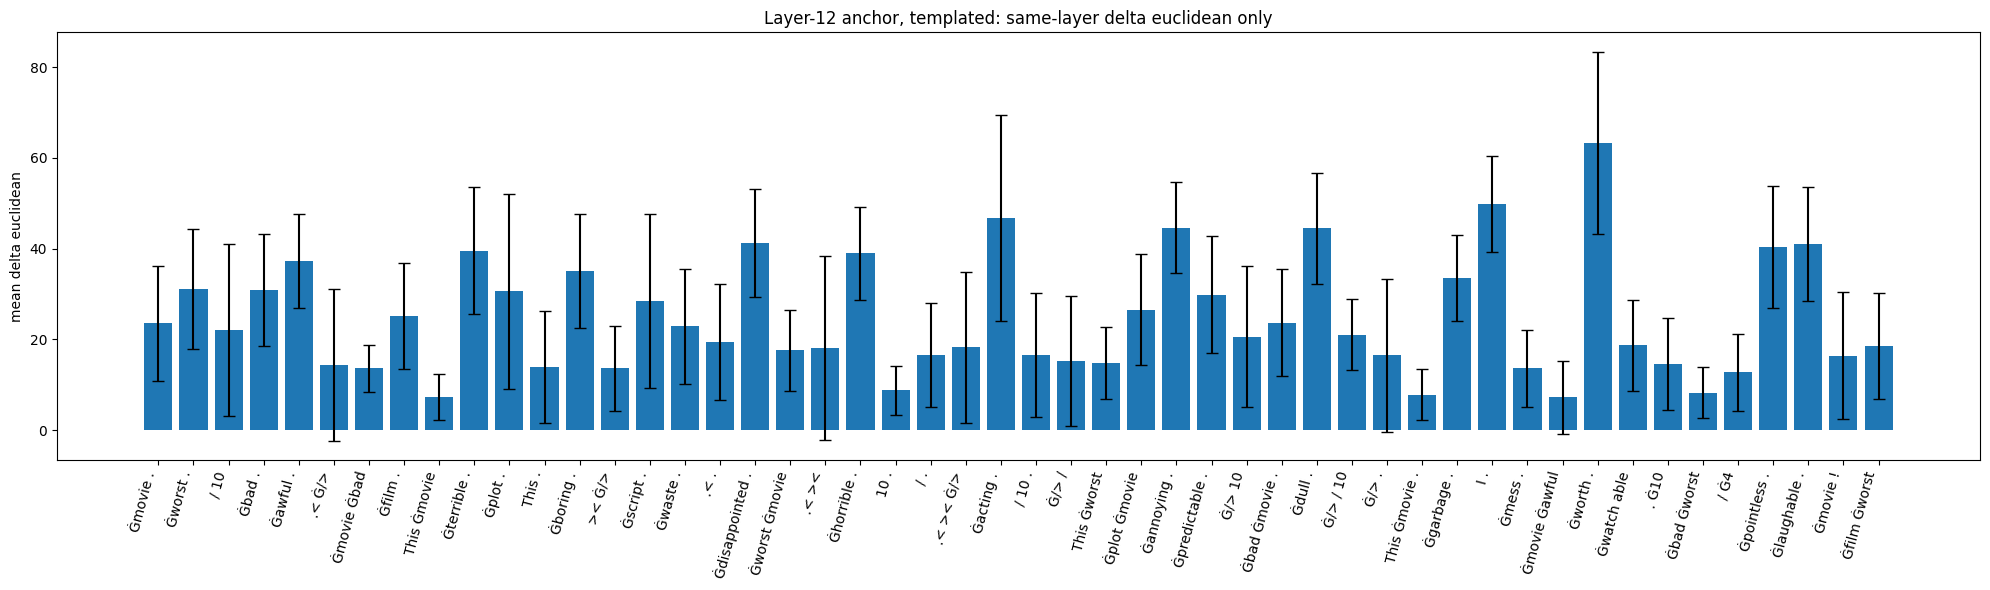

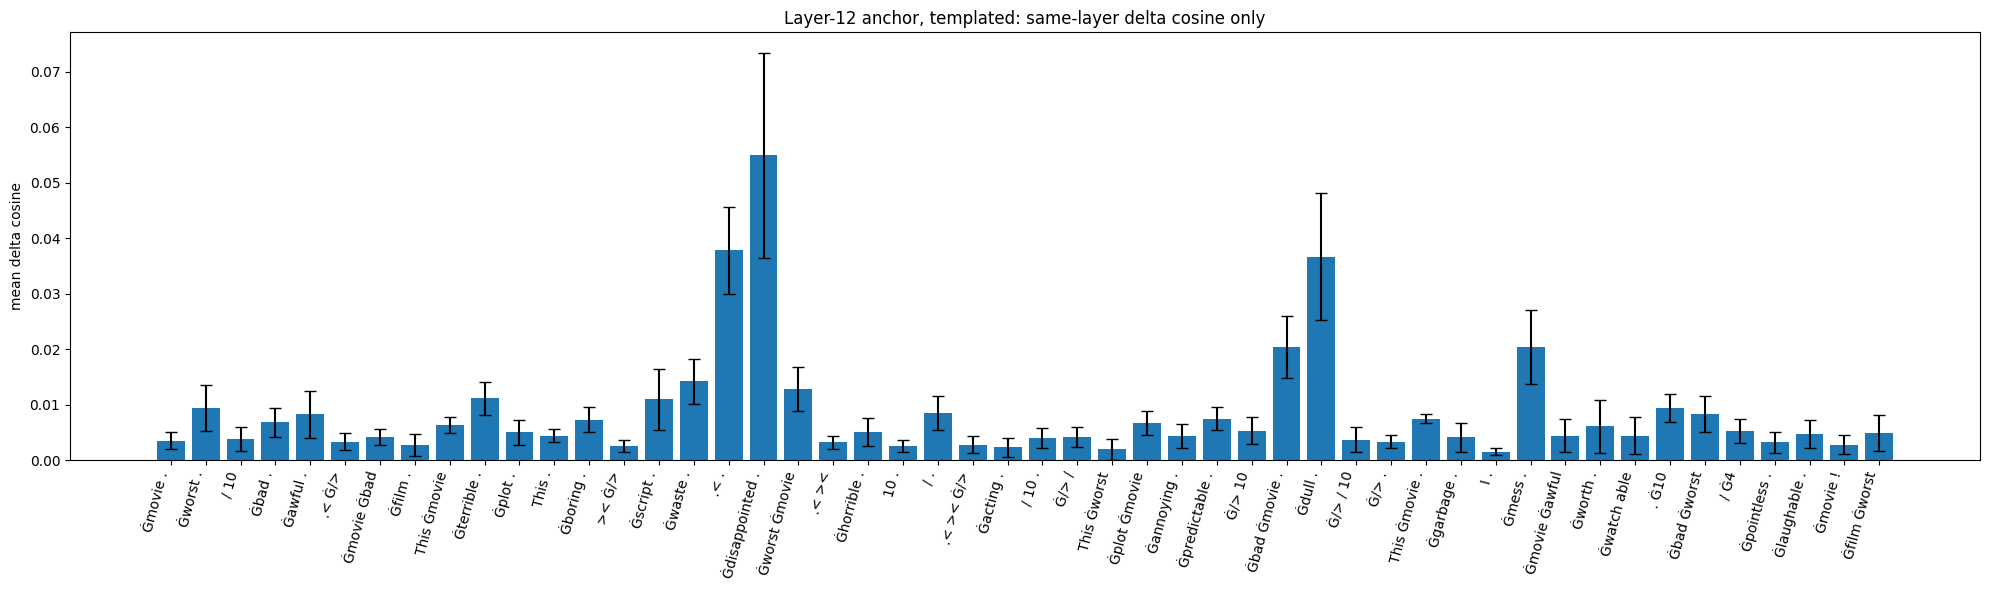

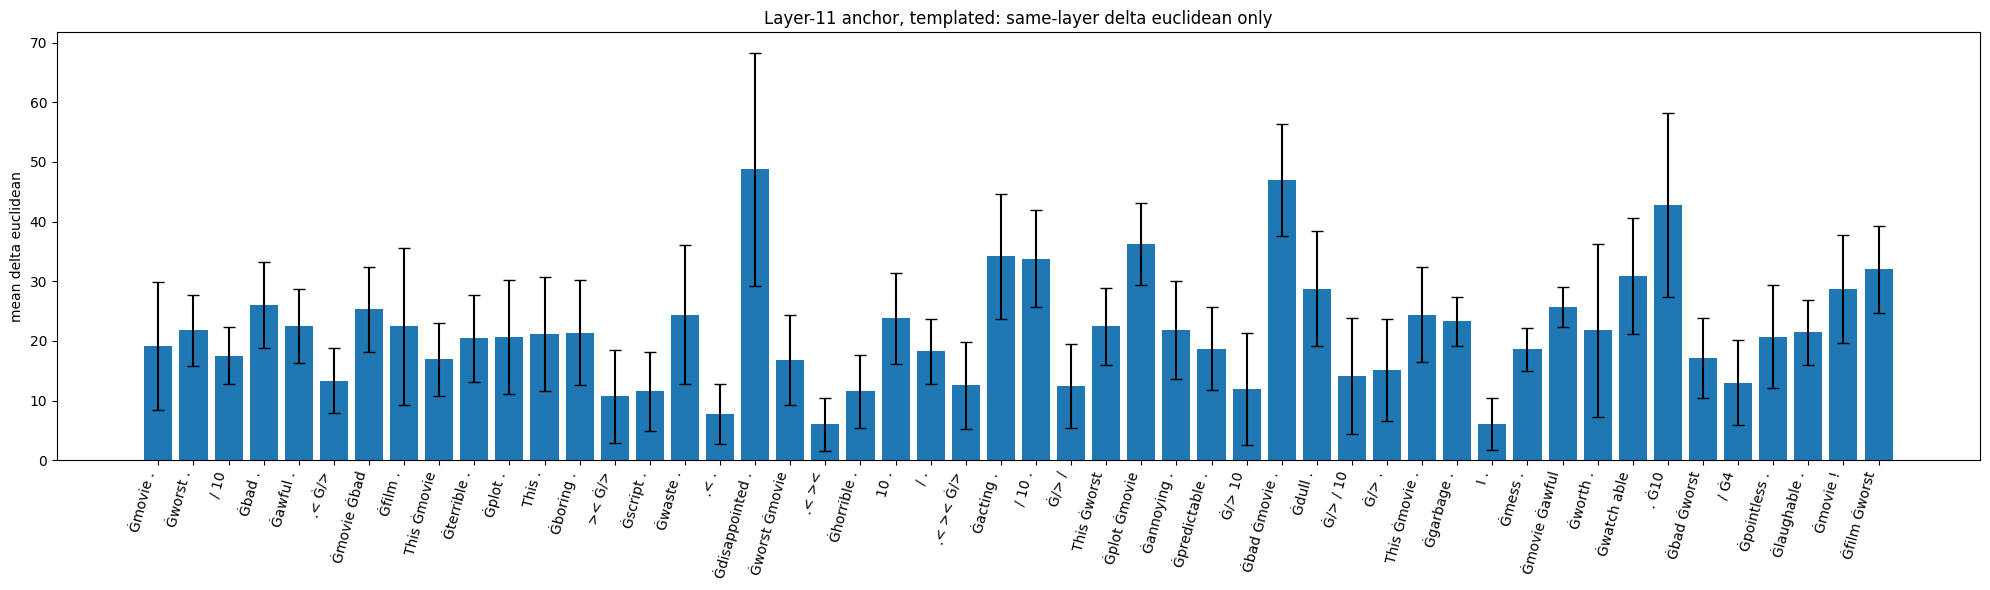

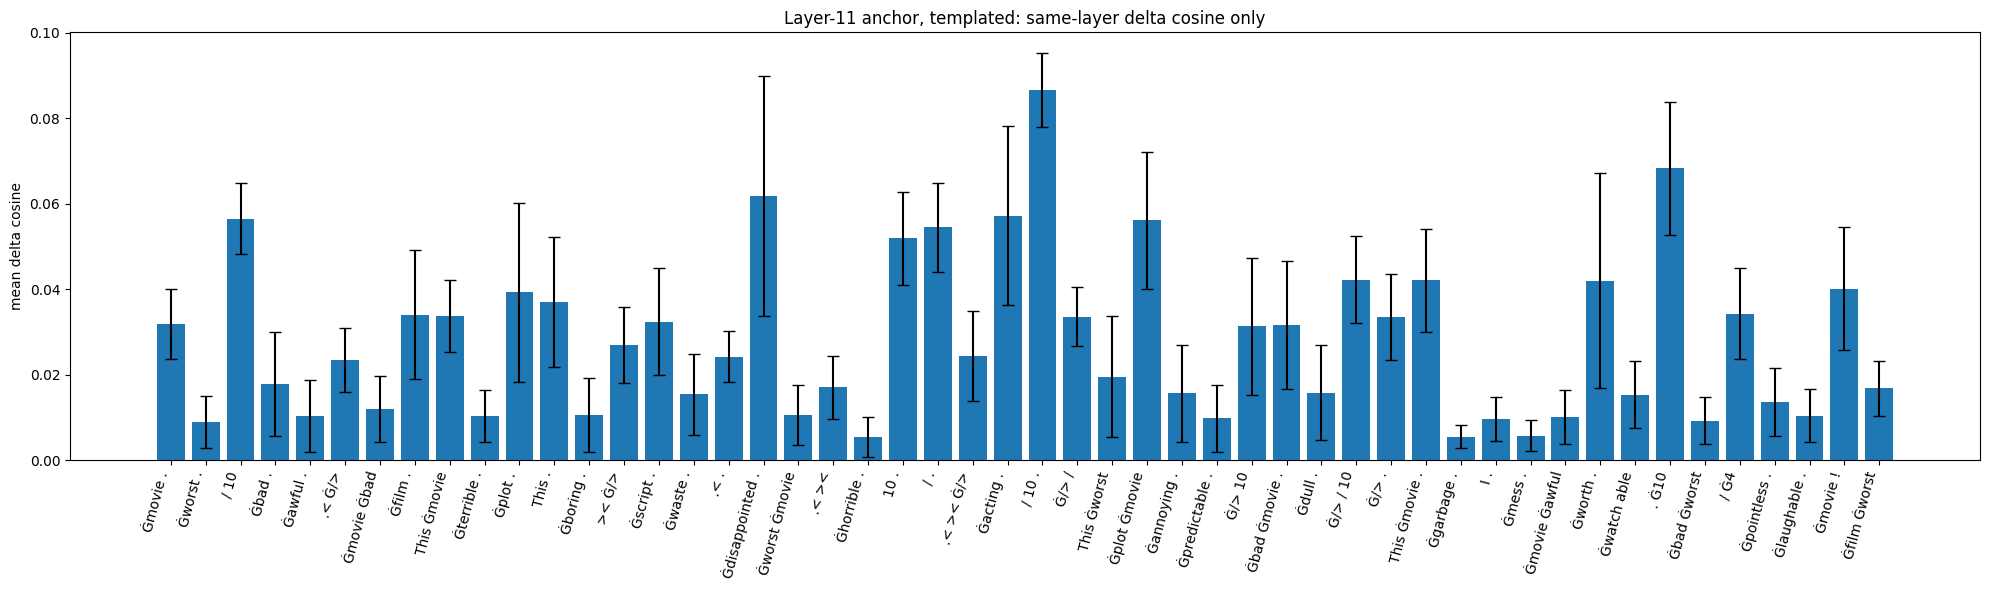

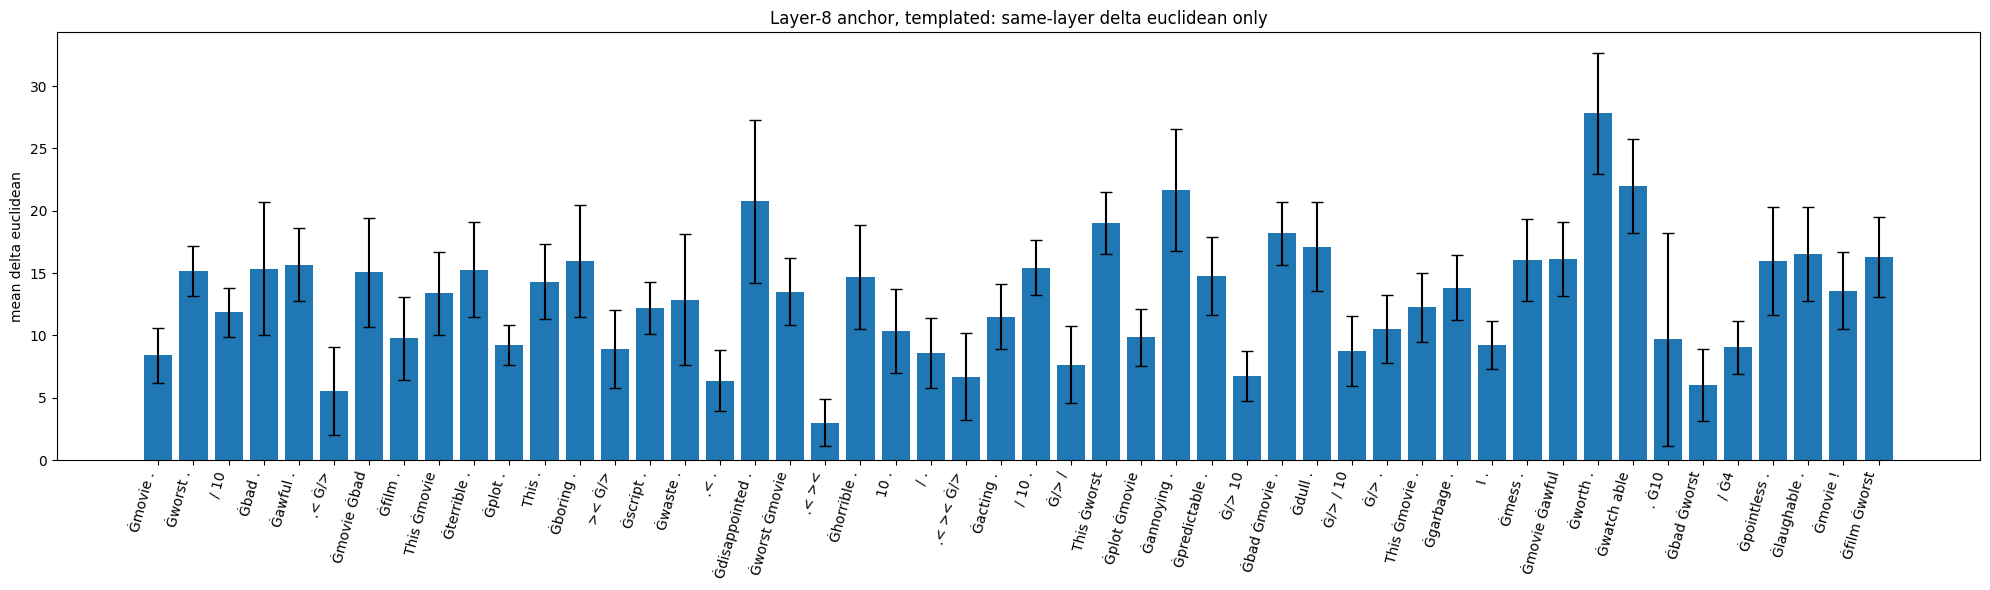

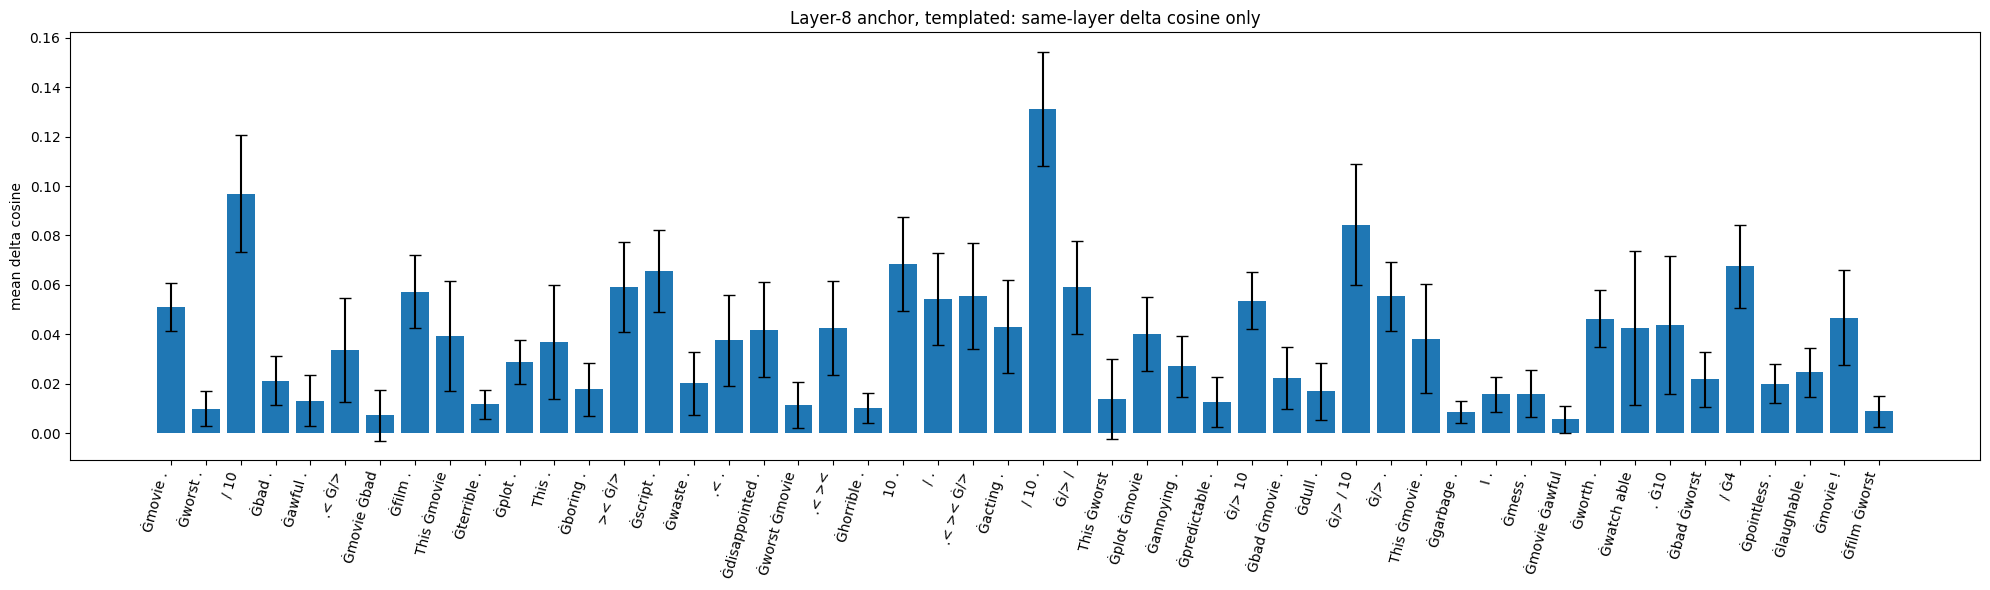

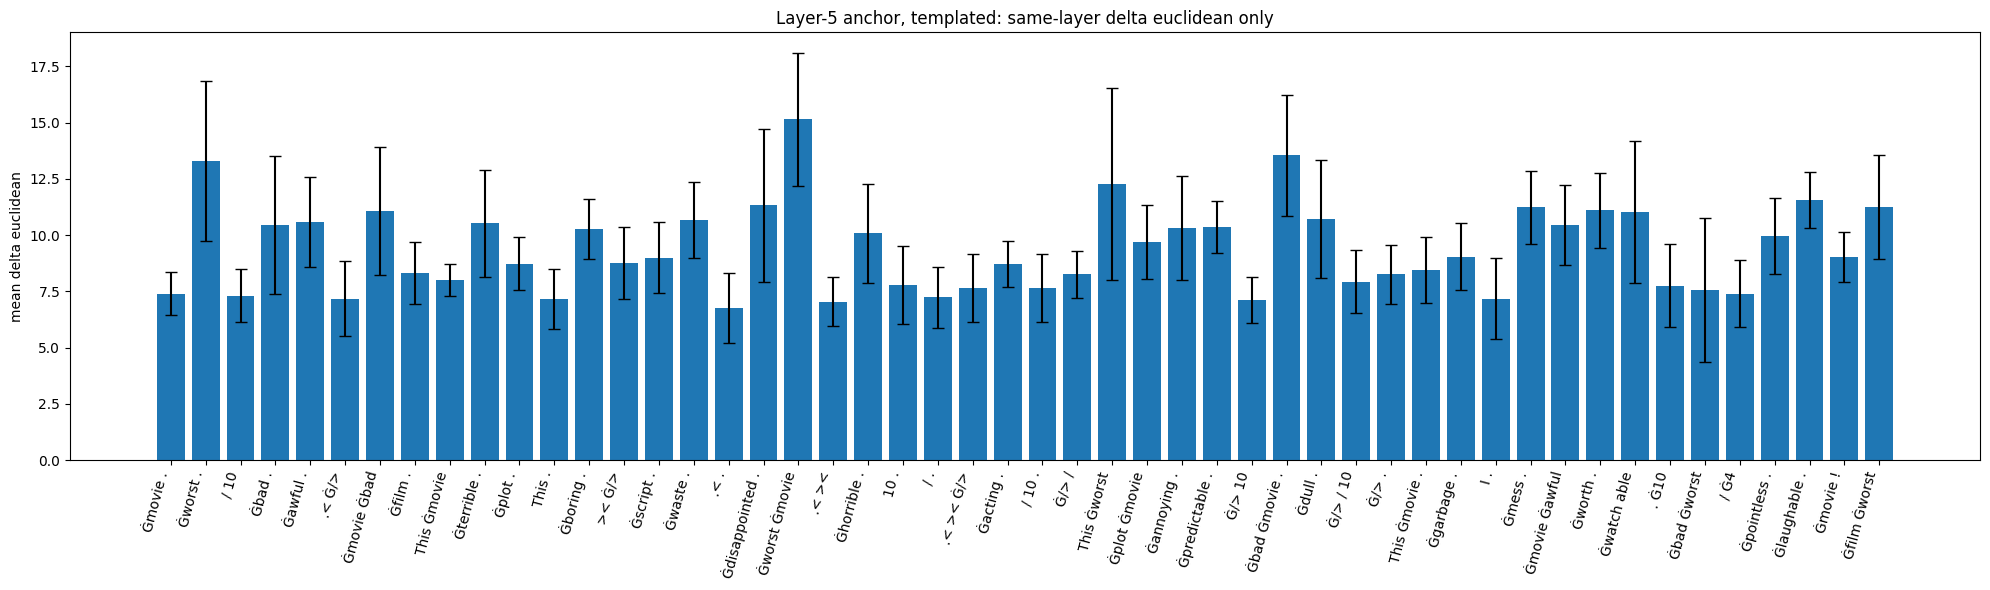

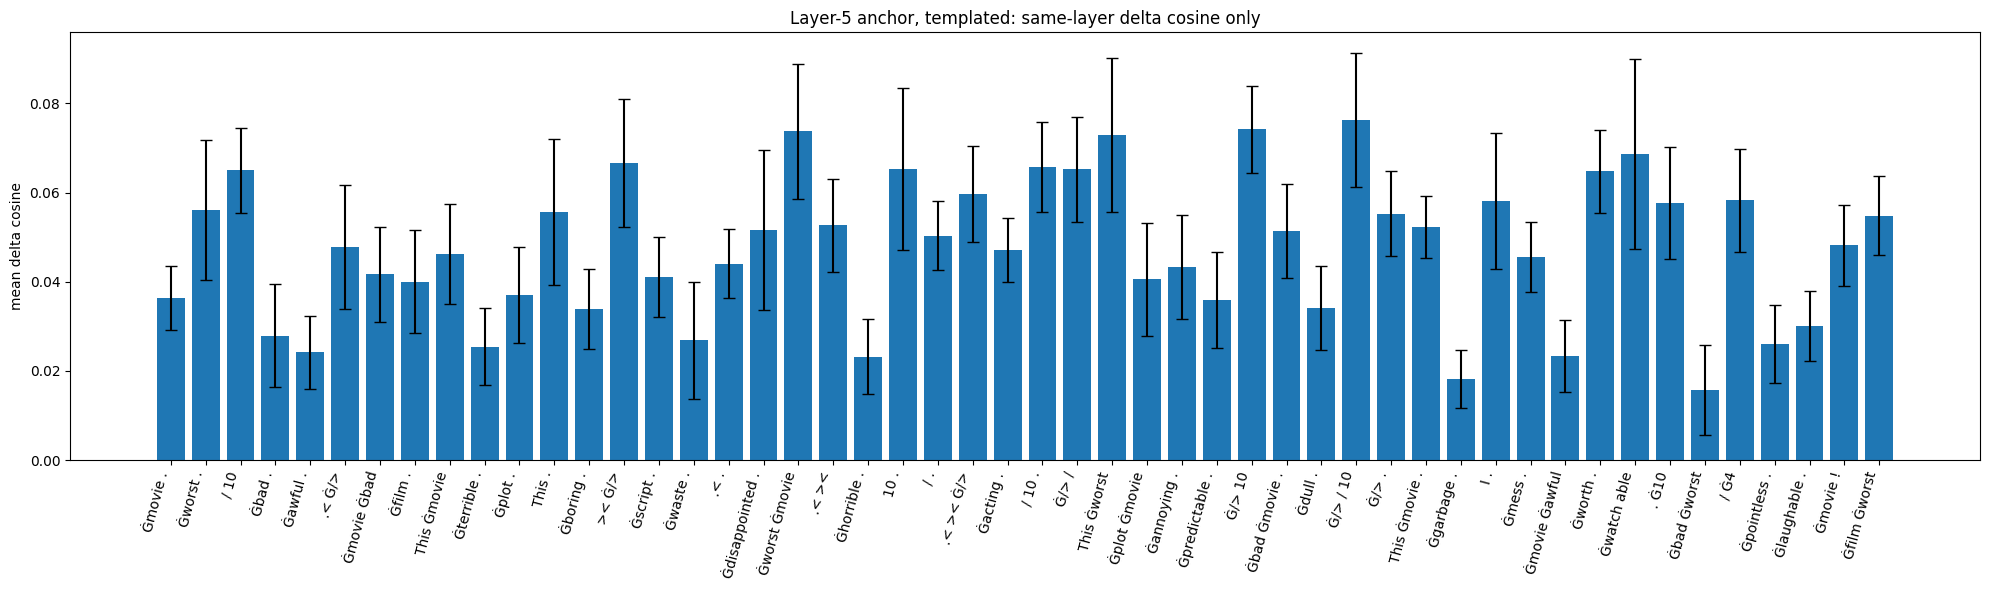

,label,mean_delta_tpl_l5_euclidean_l5,std_euclidean,mean_delta_tpl_l5_cosine_l5,std_cosine
15,Ġmovie .,7.401411,0.965963,0.036412,0.007154
18,Ġworst .,13.296661,3.546461,0.056137,0.015656
17,/ 10,7.317657,1.163129,0.064979,0.009583
26,Ġbad .,10.460169,3.081014,0.027900,0.011549
27,Ġawful .,10.580441,1.993978,0.024167,0.008184
34,.< Ġ/>,7.168264,1.666145,0.047745,0.013958
42,Ġmovie Ġbad,11.067019,2.839572,0.041645,0.010654
51,Ġfilm .,8.303824,1.376501,0.040014,0.011596
61,This Ġmovie,8.011260,0.707807,0.046243,0.011283
43,Ġterrible .,10.521754,2.374333,0.025430,0.008662


In [108]:
plot_anchor_same_layer_with_std(df_tpl_l12, anchor_layer=12, context="tpl")
plot_anchor_same_layer_with_std(df_tpl_l11, anchor_layer=11, context="tpl")
plot_anchor_same_layer_with_std(df_tpl_l8,  anchor_layer=8,  context="tpl")
plot_anchor_same_layer_with_std(df_tpl_l5,  anchor_layer=5,  context="tpl")


In [109]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANCHOR_LAYERS = (12, 11, 8, 5)


# =====================================================
# Decode GPT-2 token groups back into normal text
# =====================================================

def decode_pattern(ids):
    return tokenizer.decode(
        [int(i) for i in ids],
        clean_up_tokenization_spaces=False,
    ).strip()


# Complete IMDb rating patterns only:
# 0/10, 1/10, ..., 9/10, 10/10
RATING_PATTERN = re.compile(
    r"^(?:10|[0-9])\s*/\s*10$")


def is_rating_pattern(text):
    return bool(
        RATING_PATTERN.fullmatch(text.strip()))


# =====================================================
# Build summary
# =====================================================

def build_matched_anchor_summary(anchor_dfs, context="iso"):
    """
    anchor_dfs:
        {
            12: df_anchor_12,
            11: df_anchor_11,
             8: df_anchor_8,
             5: df_anchor_5,
        }

    Uses only the diagonal / matched columns:
      anchor 12 -> layer 12
      anchor 11 -> layer 11
      anchor  8 -> layer  8
      anchor  5 -> layer  5

    GPT-2-specific:
    Numeric classification is performed on decoded text rather
    than raw GPT-2 BPE tokens such as 'Ġ4'.
    """

    assert context in {"iso", "tpl"}

    rows = []

    for anchor_layer in ANCHOR_LAYERS:

        df_plot = anchor_dfs[anchor_layer].copy()

        # -------------------------------------------------
        # Decode GPT-2 BPE token IDs
        # -------------------------------------------------

        df_plot["decoded_text"] = (
            df_plot["ordered_ids"]
            .apply(decode_pattern)
        )

        # -------------------------------------------------
        # Numeric vs non-numeric
        # -------------------------------------------------

        is_numeric = (
        df_plot["decoded_text"]
        .apply(is_rating_pattern)
        )
        df_numeric = df_plot[is_numeric]
        df_non_numeric = df_plot[~is_numeric]

        # -------------------------------------------------
        # Select matched anchor/layer columns
        # -------------------------------------------------

        if context == "iso":

            euc_col = (
                f"mean_delta_l{anchor_layer}"
                f"_euclidean_l{anchor_layer}"
            )

            cos_col = (
                f"mean_delta_l{anchor_layer}"
                f"_cosine_l{anchor_layer}"
            )

        else:

            euc_col = (
                f"mean_delta_tpl_l{anchor_layer}"
                f"_euclidean_l{anchor_layer}"
            )

            cos_col = (
                f"mean_delta_tpl_l{anchor_layer}"
                f"_cosine_l{anchor_layer}"
            )

        # -------------------------------------------------
        # Numeric
        # -------------------------------------------------

        rows.append({
            "group": "numeric",
            "layer": f"L{anchor_layer}",

            "n": len(df_numeric),

            "mean_delta_euclidean":
                df_numeric[euc_col].mean(),

            "std_delta_euclidean":
                df_numeric[euc_col].std(),

            "mean_delta_cosine":
                df_numeric[cos_col].mean(),

            "std_delta_cosine":
                df_numeric[cos_col].std(),
        })

        # -------------------------------------------------
        # Non-numeric
        # -------------------------------------------------

        rows.append({
            "group": "non_numeric",
            "layer": f"L{anchor_layer}",

            "n": len(df_non_numeric),

            "mean_delta_euclidean":
                df_non_numeric[euc_col].mean(),

            "std_delta_euclidean":
                df_non_numeric[euc_col].std(),

            "mean_delta_cosine":
                df_non_numeric[cos_col].mean(),

            "std_delta_cosine":
                df_non_numeric[cos_col].std(),
        })


    summary = pd.DataFrame(rows)

    layer_order = [
        f"L{L}"
        for L in ANCHOR_LAYERS
    ]

    summary["layer"] = pd.Categorical(
        summary["layer"],
        categories=layer_order,
        ordered=True,
    )

    summary = (
        summary
        .sort_values(["layer", "group"])
        .reset_index(drop=True)
    )

    return summary


# =====================================================
# Plot summary
# =====================================================

def plot_matched_anchor_deltas(anchor_dfs, context="iso"):
    """
    Bar plots with standard-deviation error bars for
    matched anchor/layer deltas only.
    """

    summary = build_matched_anchor_summary(
        anchor_dfs,
        context=context,
    )

    layer_order = [
        f"L{L}"
        for L in ANCHOR_LAYERS
    ]

    num = (
        summary[
            summary["group"] == "numeric"
        ]
        .set_index("layer")
        .loc[layer_order]
    )

    non = (
        summary[
            summary["group"] == "non_numeric"
        ]
        .set_index("layer")
        .loc[layer_order]
    )

    x = np.arange(len(layer_order))
    width = 0.35

    if context == "iso":
        title_prefix = (
            "Matched anchor/layer only, isolated"
        )
    else:
        title_prefix = (
            "Matched anchor/layer only, templated"
        )


    # =================================================
    # Euclidean
    # =================================================

    plt.figure(figsize=(8, 5))

    plt.bar(
        x - width / 2,
        num["mean_delta_euclidean"].values,
        width,
        yerr=num["std_delta_euclidean"].values,
        label="numeric",
        capsize=4,
    )

    plt.bar(
        x + width / 2,
        non["mean_delta_euclidean"].values,
        width,
        yerr=non["std_delta_euclidean"].values,
        label="non_numeric",
        capsize=4,
    )

    plt.xticks(x, layer_order)

    plt.ylabel(
        "average mean delta euclidean"
    )

    plt.title(
        f"{title_prefix}: "
        "numeric vs non-numeric"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()


    # =================================================
    # Cosine
    # =================================================

    plt.figure(figsize=(8, 5))

    plt.bar(
        x - width / 2,
        num["mean_delta_cosine"].values,
        width,
        yerr=num["std_delta_cosine"].values,
        label="numeric",
        capsize=4,
    )

    plt.bar(
        x + width / 2,
        non["mean_delta_cosine"].values,
        width,
        yerr=non["std_delta_cosine"].values,
        label="non_numeric",
        capsize=4,
    )

    plt.xticks(x, layer_order)

    plt.ylabel(
        "average mean delta cosine"
    )

    plt.title(
        f"{title_prefix}: "
        "numeric vs non-numeric"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

    return summary

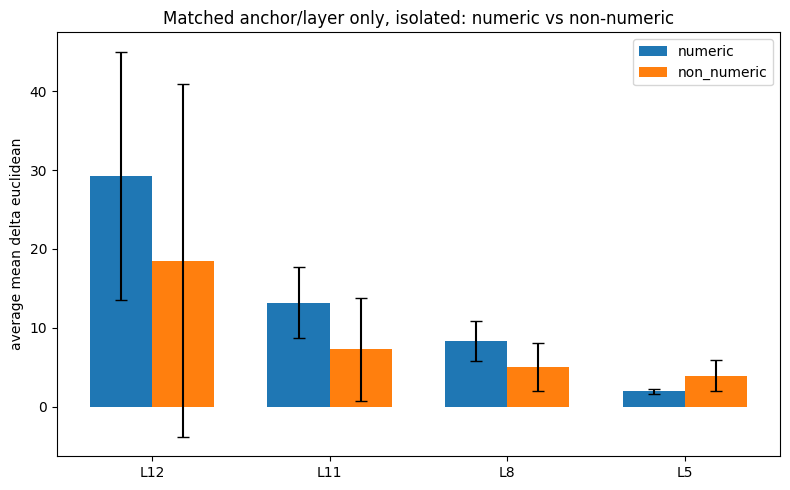

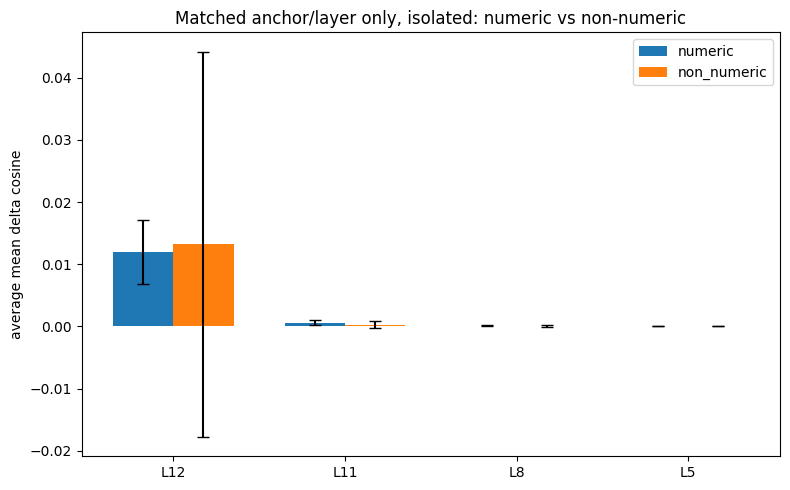

,group,layer,n,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_numeric,L12,1892,18.541002,22.365676,0.013203,0.030996
1,numeric,L12,7,29.302835,15.710460,0.011898,0.005143
2,non_numeric,L11,1892,7.287839,6.532361,0.000255,0.000547
3,numeric,L11,7,13.188173,4.528585,0.000592,0.000401
4,non_numeric,L8,1892,5.040687,3.002421,0.000070,0.000151
5,numeric,L8,7,8.332066,2.484802,0.000117,0.000028
6,non_numeric,L5,1892,3.952688,1.991143,0.000029,0.000040
7,numeric,L5,7,1.960236,0.306560,0.000068,0.000008


In [110]:
iso_anchor_dfs = {
    12: df_iso_l12,
    11: df_iso_l11,
     8: df_iso_l8,
     5: df_iso_l5,
}

summary_iso_matched = plot_matched_anchor_deltas(iso_anchor_dfs, context="iso")
summary_iso_matched


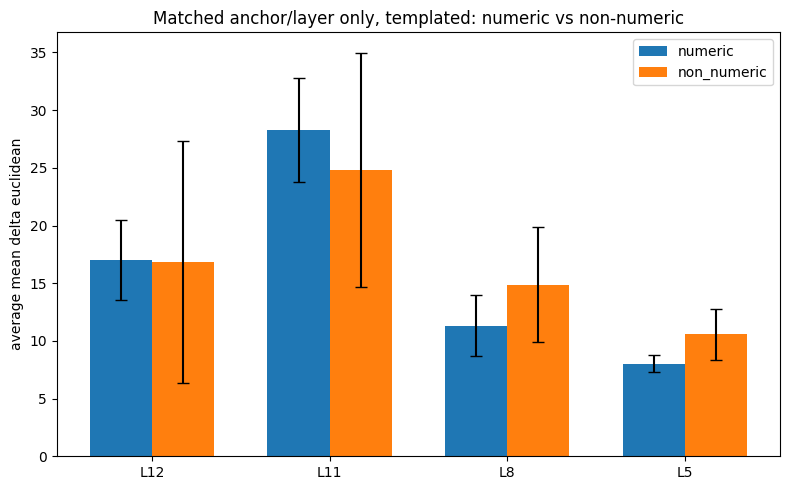

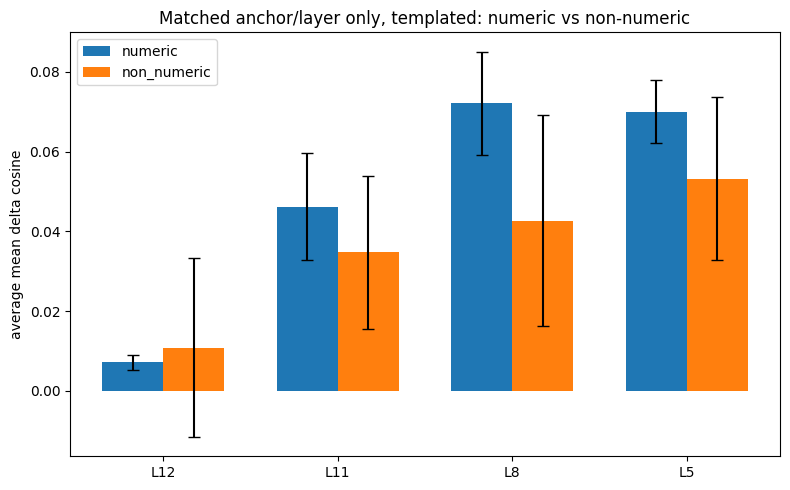

,group,layer,n,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_numeric,L12,1892,16.835397,10.484941,0.010836,0.022447
1,numeric,L12,7,17.001226,3.443705,0.007097,0.001798
2,non_numeric,L11,1892,24.817050,10.180188,0.034715,0.019242
3,numeric,L11,7,28.262471,4.527916,0.046224,0.013368
4,non_numeric,L8,1892,14.879710,4.999820,0.042705,0.026396
5,numeric,L8,7,11.312850,2.637699,0.072122,0.012992
6,non_numeric,L5,1892,10.573131,2.218853,0.053219,0.020524
7,numeric,L5,7,8.039339,0.731627,0.070009,0.007903


In [111]:
tpl_anchor_dfs = {
    12: df_tpl_l12,
    11: df_tpl_l11,
     8: df_tpl_l8,
     5: df_tpl_l5,
}

summary_tpl_matched = plot_matched_anchor_deltas(tpl_anchor_dfs, context="tpl")
summary_tpl_matched


DF_First


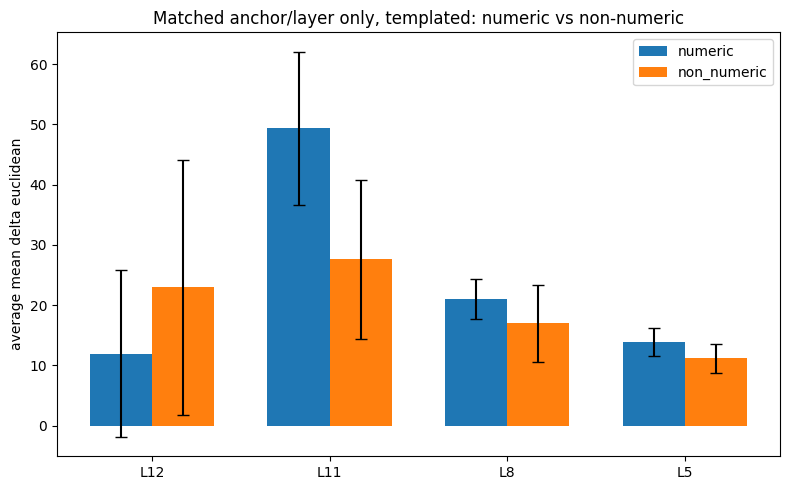

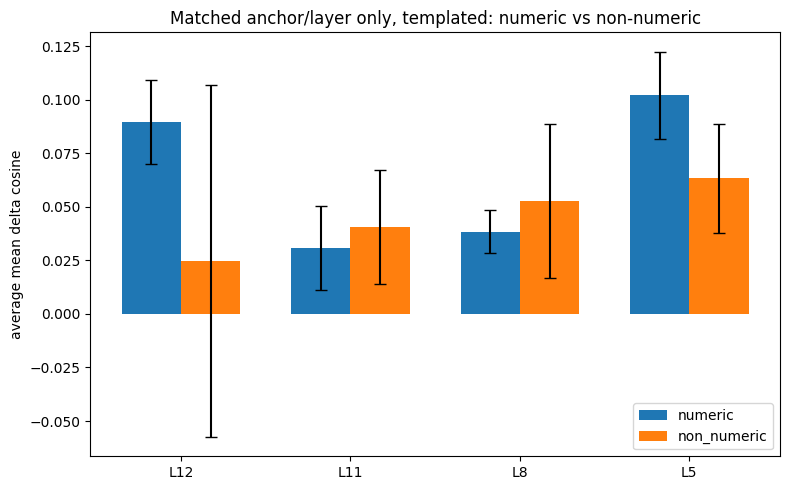

,group,layer,n,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_numeric,L12,1892,22.938912,21.230351,0.024692,0.082163
1,numeric,L12,7,11.955972,13.847029,0.089572,0.019595
2,non_numeric,L11,1892,27.616436,13.210074,0.040462,0.026685
3,numeric,L11,7,49.355454,12.748663,0.030785,0.019713
4,non_numeric,L8,1892,16.970510,6.381701,0.052730,0.035977
5,numeric,L8,7,21.033144,3.273442,0.038353,0.010112
6,non_numeric,L5,1892,11.163082,2.392049,0.063263,0.025476
7,numeric,L5,7,13.923553,2.352069,0.102044,0.020433


In [112]:

# =====================================================
# PRIMARY GPT-2 matched-anchor analysis: LAST TOKEN
# =====================================================

df_tpl_last_l12 = run_anchor_analysis(
    df_last_token, token_df, anchor_layer=12, context="tpl"
)
df_tpl_last_l11 = run_anchor_analysis(
    df_last_token, token_df, anchor_layer=11, context="tpl"
)
df_tpl_last_l8 = run_anchor_analysis(
    df_last_token, token_df, anchor_layer=8, context="tpl"
)
df_tpl_last_l5 = run_anchor_analysis(
    df_last_token, token_df, anchor_layer=5, context="tpl"
)

tpl_last_anchor_dfs = {
    12: df_tpl_last_l12,
    11: df_tpl_last_l11,
    8: df_tpl_last_l8,
    5: df_tpl_last_l5,
}

summary_tpl_last_matched = plot_matched_anchor_deltas(
    tpl_last_anchor_dfs,
    context="tpl",
)

summary_tpl_last_matched


DF_Sum


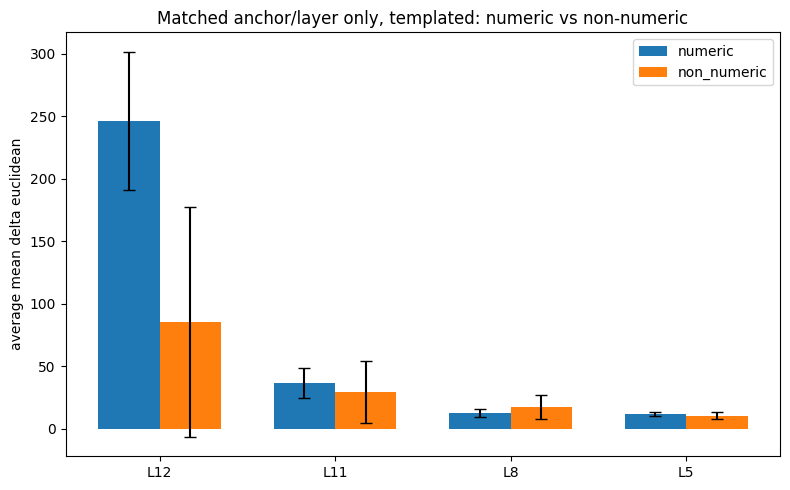

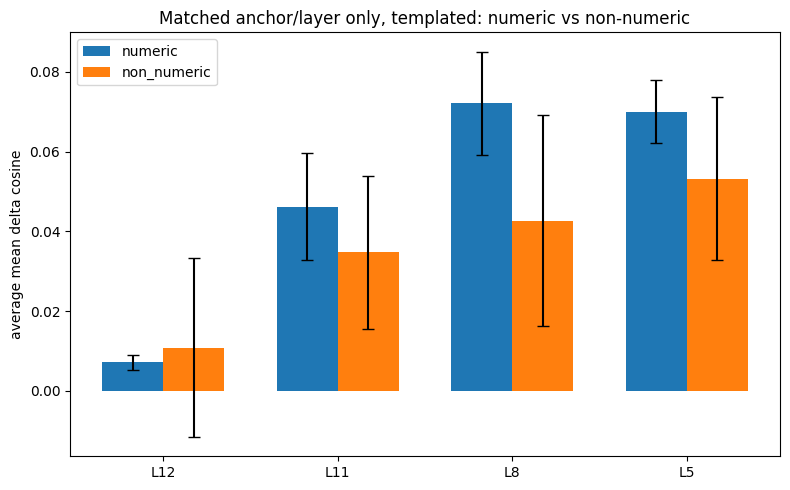

,group,layer,n,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_numeric,L12,1892,85.319690,92.096832,0.010836,0.022447
1,numeric,L12,7,246.127987,55.492750,0.007097,0.001798
2,non_numeric,L11,1892,29.545395,24.880828,0.034715,0.019242
3,numeric,L11,7,36.420496,11.645019,0.046224,0.013368
4,non_numeric,L8,1892,17.138507,9.862837,0.042705,0.026396
5,numeric,L8,7,12.227591,3.088054,0.072122,0.012992
6,non_numeric,L5,1892,10.362320,3.009722,0.053219,0.020524
7,numeric,L5,7,11.719171,1.461222,0.070009,0.007903


In [113]:
df_tpl_sum_l12 = run_anchor_analysis(df_sum, token_df, anchor_layer=12, context="tpl")
df_tpl_sum_l11 = run_anchor_analysis(df_sum, token_df, anchor_layer=11, context="tpl")
df_tpl_sum_l8  = run_anchor_analysis(df_sum, token_df, anchor_layer=8,  context="tpl")
df_tpl_sum_l5  = run_anchor_analysis(df_sum, token_df, anchor_layer=5,  context="tpl")

tpl_sum_anchor_dfs = {
    12: df_tpl_sum_l12,
    11: df_tpl_sum_l11,
     8: df_tpl_sum_l8,
     5: df_tpl_sum_l5,
}

summary_tpl_sum_matched = plot_matched_anchor_deltas(tpl_sum_anchor_dfs, context="tpl")
summary_tpl_sum_matched
